# Лекция 4. Self-supervised learning визуальных представлений

Курс «Современное компьютерное зрение». Блокнот рассчитан на Google Colab: ячейки выполняются сверху вниз. Нужны torch, transformers, timm, scikit-learn, pandas и matplotlib (в Colab всё установлено) и umap-learn (первая ячейка установит его сама).

Что скачивается автоматически:

- CIFAR-10 в формате parquet, около 140 МБ;
- веса четырёх ViT — DINOv2-S/14, DINO-S/16, MAE-B/16 и ViT-S/16, обученного с учителем, — около 0,8 ГБ (пятая модель, ViT-S/16 со случайными весами, ничего не скачивает);
- одна фотография из COCO val2017 для карт внимания.

Сохранённые выводы получены на CPU в режиме `FAST_DEV_RUN`:

- 300 шагов мини-предобучения на метод на 10 000 изображениях;
- 150 размеченных изображений на класс и 1000 тестовых для предобученных энкодеров;
- 600 изображений в эксперименте с паразитным признаком.

Прогон занял около 31 минуты на двух ядрах CPU вместе с загрузкой. Ветка для GPU в Colab (`FAST_DEV_RUN = False`: 3000 шагов, 50 000 изображений пула, 500 изображений на класс, шире сеть) написана, но не проверялась. На ней числа будут другими, переносить стоит направления эффектов.

## Цели лекции

После лекции слушатель должен уметь:

1. Объяснить, как контрастные методы (SimCLR, MoCo) избегают коллапса за счёт негативов, вывести InfoNCE и его градиент, объяснить роль температуры, очереди и momentum-энкодера.
2. Объяснить, почему BYOL и DINO работают без негативов: асимметрия, предиктор, EMA-учитель, центрирование и заострение. Узнавать коллапс по мониторам.
3. Описать masked image modeling (MAE, iBOT) и объяснить, почему признаки MAE хуже по linear probe, но хорошо дообучаются.
4. Корректно оценить представление: weighted k-NN, linear probe, few-shot с доверительными интервалами, кривые по объёму разметки.
5. Строить и честно читать проекции UMAP и t-SNE, обнаруживать паразитные признаки (shortcut learning) и бороться с ними.

## Обозначения

| Символ | Смысл |
|---|---|
| $x$ | изображение |
| $t, t'\sim\mathcal T$ | случайные аугментации из семейства $\mathcal T$ |
| $f_\theta$ | энкодер (backbone) с параметрами $\theta$ |
| $h=f_\theta(x)\in\mathbb R^{d}$ | представление, используемое на downstream-задачах |
| $g$ | проекционная голова (projector) |
| $z=g(h)$ | проекция, по которой считается SSL-потеря |
| $\bar z=z/\|z\|_2$ | нормированный вектор |
| $\mathrm{sim}(u,v)=\bar u^\top\bar v$ | косинусное сходство |
| $\tau$ | температура softmax |
| $N$ или $B$ | размер батча (число изображений) |
| $K$ | число негативов (MoCo) или размерность выхода головы (DINO) |
| $m,\lambda$ | коэффициент экспоненциального скользящего среднего (EMA) |
| $\mathrm{sg}(\cdot)$ | stop-gradient: значение используется, градиент через него не идёт |
| $H(p)$ | энтропия распределения $p$ |
| $H(p,q)=-\sum_k p_k\log q_k$ | кросс-энтропия |
| $n$ | число размеченных примеров на класс (shots) |

## Как устроен блокнот

- **Часть I. Теория** (разделы 1–8):
  - зачем учиться без разметки, аугментации и проекционная голова;
  - контрастное обучение: InfoNCE, SimCLR, MoCo, alignment и uniformity;
  - методы без негативов: коллапс, BYOL, SimSiam, DINO, SwAV, Barlow Twins, VICReg, DINOv2;
  - masked image modeling: BEiT, MAE, iBOT, I-JEPA;
  - оценка представлений: k-NN, linear probe, few-shot, кривые по разметке;
  - визуализация эмбеддингов: PCA, t-SNE, UMAP;
  - паразитные признаки и shortcut learning;
  - практические рецепты.
- **Часть II. Практикум** (разделы 9–15):
  - 9 — подготовка данных и аугментации на батче;
  - 10 — функции потерь и мониторы коллапса своими руками;
  - 11 — мини-предобучение SimCLR, MoCo, BYOL, DINO и MAE с нуля, включая два сломанных варианта;
  - 12 — пять предобученных ViT, карты внимания DINO, PCA патчей DINOv2, реконструкции MAE;
  - 13 — протоколы оценки и кривые по объёму разметки;
  - 14 — PCA, t-SNE и UMAP с количественной проверкой;
  - 15 — контролируемый эксперимент с паразитным признаком, аудит и способы борьбы.
- **Выводы, контрольные вопросы с ответами, задания, источники.**

После каждого эксперимента идёт абзац **Что видно.** Он написан по сохранённым выводам этого прогона. При перезапуске числа немного изменятся, а на GPU с `FAST_DEV_RUN = False` — заметно.

# Часть I. Теория

## 1. Зачем учиться без разметки

### 1.1. Проблема

Обучение с учителем требует разметки. В прикладных задачах курса (сквозной проект в одном домене) разметка дорогая и медленная, а иногда невозможна в нужном объёме: медицинские снимки, промышленный контроль, аэрофотосъёмка. Неразмеченных изображений при этом обычно много: архивы камер, кадры видео, снимки с производства.

Self-supervised learning (SSL, самообучение) использует неразмеченные данные. Модели ставится вспомогательная задача (pretext task), правильный ответ на которую извлекается из самих данных. Решая её, энкодер учится представлению $h=f_\theta(x)$, полезному для целевых (downstream) задач.

Формально:

- дано: множество $\mathcal D_u=\{x_i\}_{i=1}^{N_u}$ без меток и малое множество $\mathcal D_l=\{(x_j,y_j)\}_{j=1}^{N_l}$, $N_l\ll N_u$;
- этап 1, предобучение: $\theta^\star=\arg\min_\theta \mathcal L_{\text{SSL}}(\theta;\mathcal D_u)$;
- этап 2, адаптация: на $\mathcal D_l$ обучается дешёвая надстройка над $f_{\theta^\star}$ — k-NN, линейный классификатор, лёгкая голова. Либо энкодер дообучается целиком (fine-tuning).

Качество SSL-метода измеряется на этапе 2. Поэтому в части 5 оценке посвящён отдельный большой раздел.

### 1.2. Краткая история pretext-задач

Ранние работы придумывали «головоломки», для решения которых нужно понимать содержимое изображения:

- Предсказание относительного положения двух патчей одного изображения ([Doersch et al., 2015](https://arxiv.org/abs/1505.05192)). Чтобы решить задачу, нужно узнавать объекты и их части.
- Сборка пазла из перемешанных фрагментов ([Noroozi, Favaro, 2016](https://arxiv.org/abs/1603.09246)).
- Предсказание угла поворота изображения: 0°, 90°, 180°, 270° ([Gidaris et al., 2018](https://arxiv.org/abs/1803.07728)). Чтобы понять, где «верх», надо распознать объект.

У таких задач общий недостаток: признаки подстраиваются под конкретную головоломку и часто используют низкоуровневые подсказки. Например, при сборке пазла это стыки краёв и хроматическая аберрация объектива. Это ранний пример shortcut-а (часть 7).

Современные методы устроены по-другому. Они либо требуют инвариантности представления к семейству искажений (части 2–3), либо восстанавливают скрытую часть входа (часть 4). На рис. 1 показаны три семейства, которые мы разберём.

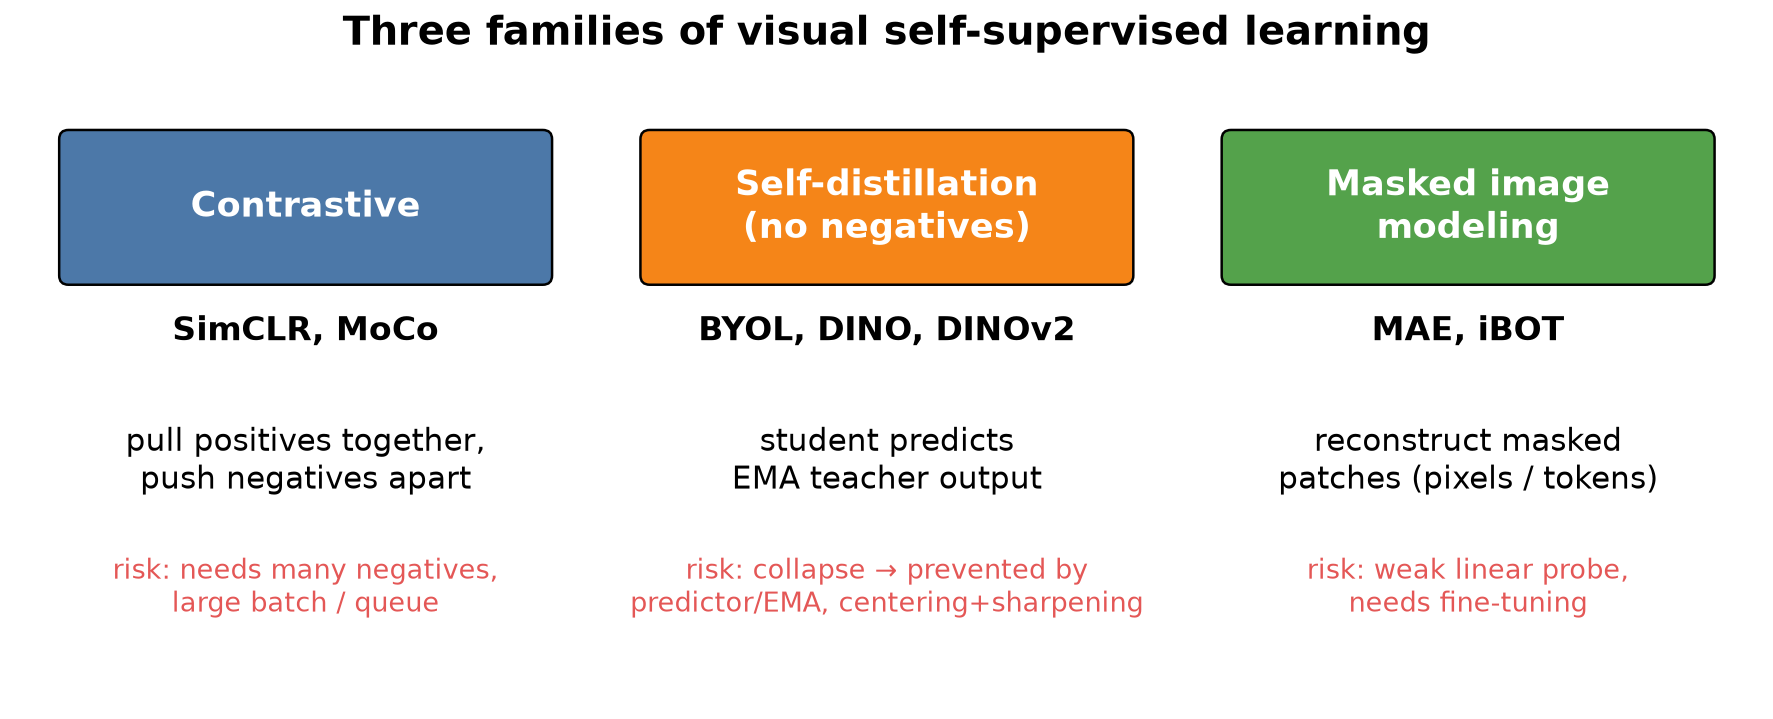

### 1.3. Что значит «хорошее представление»

Желаемые свойства:

1. Семантическая информативность: класс объекта (и другие целевые факторы) легко извлекается — линейно или по ближайшим соседям.
2. Инвариантность к мешающим факторам: освещению, кадрированию, небольшим сдвигам цвета. Это задаётся аугментациями. Важно, что инвариантность к фактору означает удаление информации о нём. Если инвариантность к цвету навязана, а цвет важен для задачи (спелость плода, цвет сигнала светофора), представление будет хуже.
3. Невырожденность: представление не схлопывается в константу или в подпространство малой размерности (коллапс, часть 3.1).
4. Переносимость: работает на других наборах данных и задачах — детекции, сегментации, оценке глубины.
5. Отсутствие паразитных признаков: решение не держится на артефактах вроде водяных знаков, рамок или особенностей камеры (часть 7).

Свойства 1 и 2 конфликтуют с 3. Чем сильнее мы требуем «одинаковости» разных видов, тем проще вырожденное решение «всё одинаково». Каждый метод ниже — способ разрешить этот конфликт.

### 1.4. Роль аугментаций и проекционной головы

Аугментации задают, что считать «одним и тем же». Для ImageNet-подобных фотографий стандартный набор из [SimCLR](https://arxiv.org/abs/2002.05709):

- random resized crop (площадь 0.08–1.0 от исходной, соотношение сторон 3/4–4/3) с горизонтальным отражением;
- color jitter с вероятностью 0.8;
- перевод в оттенки серого с вероятностью 0.2;
- гауссово размытие с вероятностью 0.5.

Для своего домена аугментации нужно пересматривать. Повороты на 90° уместны для аэро- и микроскопических снимков, но не для фотографий улиц. Сильный color jitter вреден, если цвет несёт информацию.

Проекционная голова $g$ — небольшой MLP после энкодера. Потеря считается по $z=g(h)$, а на downstream используется $h$. Причина: SSL-потеря требует инвариантности к аугментациям и может «стирать» полезную информацию (цвет, ориентацию) в выходном пространстве. Голова принимает этот удар на себя, а $h$ сохраняет больше информации. В SimCLR представление до головы заметно лучше представления после неё ([SimCLR](https://arxiv.org/abs/2002.05709)).

## 2. Контрастное обучение

### 2.1. Идея

Для «якоря» $x$ берём позитив $x^+$ (другой вид того же изображения) и негативы $x^-_1,\dots,x^-_K$ (виды других изображений). Требуем, чтобы эмбеддинг якоря был ближе к позитиву, чем к любому негативу. Негативы не дают решению схлопнуться: если все эмбеддинги одинаковы, отличить позитив невозможно, и потеря будет большой.

### 2.2. Функция потерь InfoNCE

Обозначим сходства $s_+=\mathrm{sim}(z,z^+)$ и $s_i=\mathrm{sim}(z,z^-_i)$. Функция потерь InfoNCE в форме из [MoCo](https://arxiv.org/abs/1911.05722):

$
\mathcal L=-\log\frac{\exp(s_+/\tau)}{\exp(s_+/\tau)+\sum_{i=1}^{K}\exp(s_i/\tau)}.
$

Интерпретация 1: классификация. Это обычная кросс-энтропия $(K{+}1)$-классовой задачи. Логиты равны $s/\tau$, «правильный класс» — позитив. Поэтому InfoNCE в коде реализуется через `cross_entropy`.

Интерпретация 2: взаимная информация. В [CPC](https://arxiv.org/abs/1807.03748) показано, что минимизация InfoNCE с $N$ кандидатами (один позитив и $N-1$ негатив) максимизирует нижнюю оценку взаимной информации между связанными переменными:

$
I(x^+;x)\ \ge\ \log N-\mathcal L_N.
$

Оптимальный «критик» $\exp(s/\tau)$ пропорционален отношению плотностей $p(x^+\mid x)/p(x^+)$. Отсюда две практические подсказки:

- оценка становится точнее с ростом $N$, поэтому контрастным методам нужно много негативов;
- взаимная информация не может превысить $\log N$, то есть оценка ограничена сверху.

### 2.3. Градиент InfoNCE и роль температуры

Запишем потерю через логиты: $\mathcal L=-s_+/\tau+\log\sum_{j\in\{+,1..K\}}e^{s_j/\tau}$. Обозначим $p_j=\mathrm{softmax}(s/\tau)_j$. Тогда

$
\frac{\partial\mathcal L}{\partial s_+}=\frac{p_+-1}{\tau}\le0,\qquad
\frac{\partial\mathcal L}{\partial s_i}=\frac{p_i}{\tau}\ge0.
$

Выводы:

1. Позитив притягивается, а каждый негатив отталкивается с силой, пропорциональной $p_i\propto\exp(s_i/\tau)$. Негативы, уже похожие на якорь (hard negatives), получают экспоненциально больший вес.
2. Температура регулирует эту концентрацию (рис. 10).
   - При малом $\tau$ почти весь градиент уходит в несколько самых похожих негативов. Это даёт хорошую разделимость, но повышает чувствительность к «ложным негативам»: другим изображениям того же класса, которые метод вынужден расталкивать.
   - При большом $\tau$ все негативы толкаются почти одинаково, и сигнал становится слабым.
3. Множитель $1/\tau$ масштабирует и сам градиент. При смене $\tau$ обычно нужно перенастроить скорость обучения.

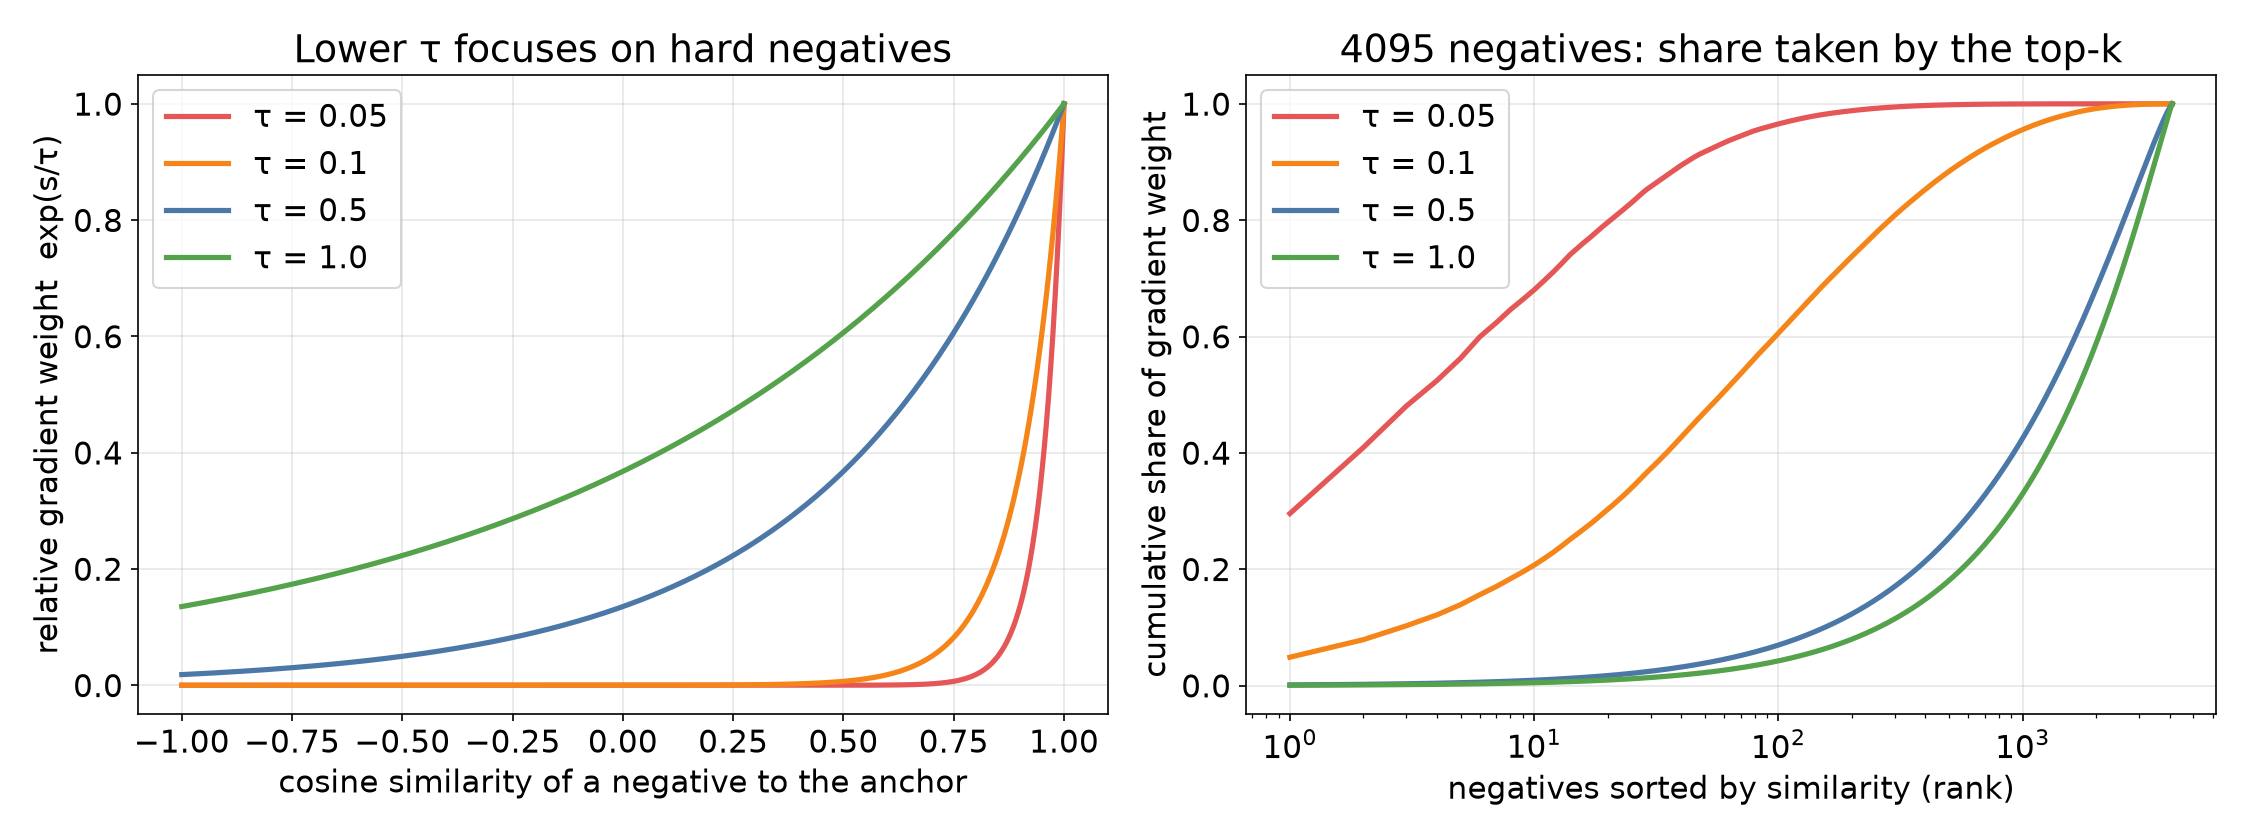

Эмпирически в [SimCLR](https://arxiv.org/abs/2002.05709) на ImageNet лучшим из протестированных значений было $\tau=0.1$: 64.4% top-1 против 59.7% при 0.05, 60.7% при 0.5 и 58.0% при 1.0. На CIFAR-10 оптимум был около 0.5. В [MoCo](https://arxiv.org/abs/1911.05722) использовано $\tau=0.07$.

Проблема ложных негативов принципиальна. Контрастная потеря не знает классов, поэтому две разные кошки для неё — негативы. Большое число негативов статистически «разбавляет» эту проблему: доля негативов того же класса около $1/C$ для $C$ классов. Для доменов с малым числом классов и сильно похожими изображениями проблема заметнее.

### 2.4. SimCLR

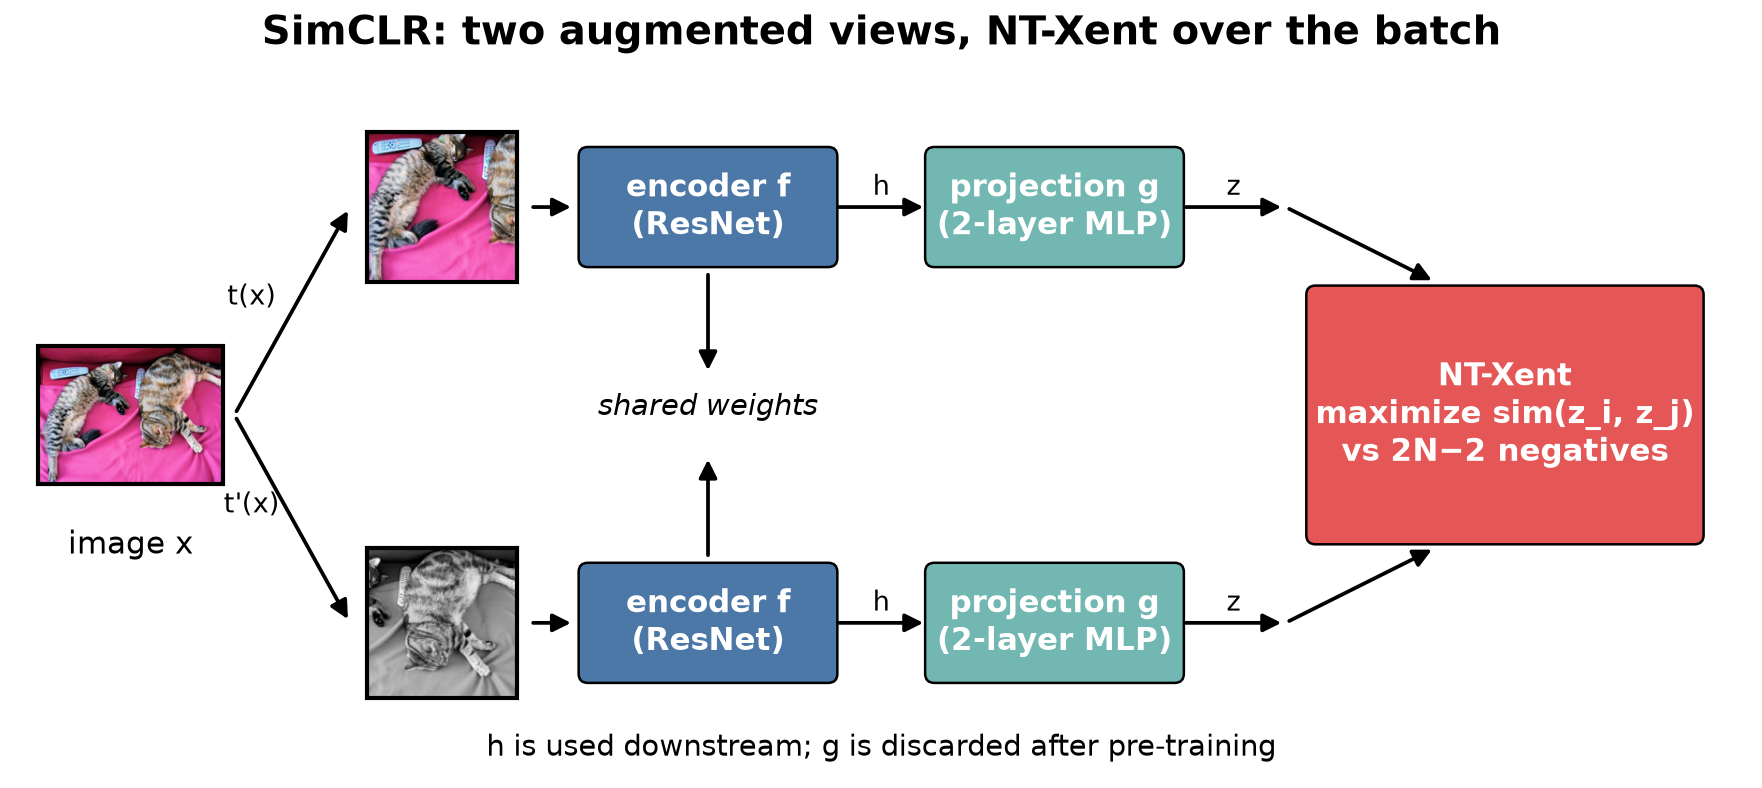

Схема [SimCLR](https://arxiv.org/abs/2002.05709):

1. Батч из $N$ изображений; к каждому применяются две аугментации, получается $2N$ видов.
2. Энкодер (ResNet) даёт $h$, двухслойный MLP-проектор даёт 128-мерный $z$.
3. Для пары $(i,j)$ видов одного изображения потеря NT-Xent (normalized temperature-scaled cross-entropy):
$
\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb 1[k\ne i]\exp(\mathrm{sim}(z_i,z_k)/\tau)}.
$
   Итоговая потеря — среднее по всем $2N$ якорям.
4. Негативы: остальные $2N-2$ вида в батче (рис. 3). При $N=4096$ это 8190 негативов.

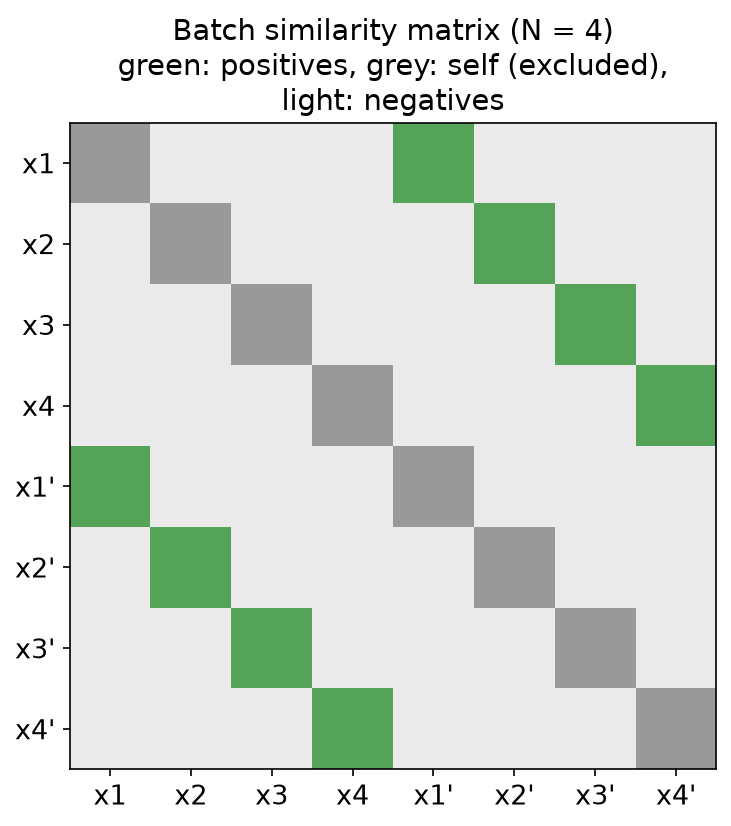

Остальной рецепт:

- оптимизатор LARS;
- $lr=0.3\times N/256$, то есть 4.8 при $N=4096$;
- weight decay $10^{-6}$;
- 10 эпох разогрева, косинусное затухание.

Результаты linear evaluation на ImageNet ([SimCLR](https://arxiv.org/abs/2002.05709)): ResNet-50 — 69.3% top-1, ResNet-50 (4×) — 76.5%.

Главные выводы статьи:

1. Композиция аугментаций критична. Особенно важна пара «кроп + цветовые искажения». Без цвета задачу можно решить по цветовой гистограмме: два кропа одного снимка имеют похожие цвета.
2. Нелинейная проекционная голова улучшает представление $h$.
3. Большие батчи и долгое обучение важнее для SSL, чем для обучения с учителем.

```python
import torch, torch.nn.functional as F

def nt_xent(z1, z2, tau=0.1):
    """z1, z2: [N, D] проекции двух видов одного батча."""
    z = F.normalize(torch.cat([z1, z2]), dim=1)            # [2N, D]
    sim = z @ z.T / tau                                       # [2N, 2N]
    sim.fill_diagonal_(float("-inf"))                         # исключаем k = i
    N = z1.shape[0]
    target = torch.cat([torch.arange(N, 2 * N), torch.arange(0, N)]).to(z.device)
    return F.cross_entropy(sim, target)                       # среднее по 2N якорям
```

### 2.5. MoCo

Ограничение SimCLR — число негативов привязано к батчу, а большой батч требует много памяти. [MoCo](https://arxiv.org/abs/1911.05722) отвязывает словарь негативов от батча (рис. 4).

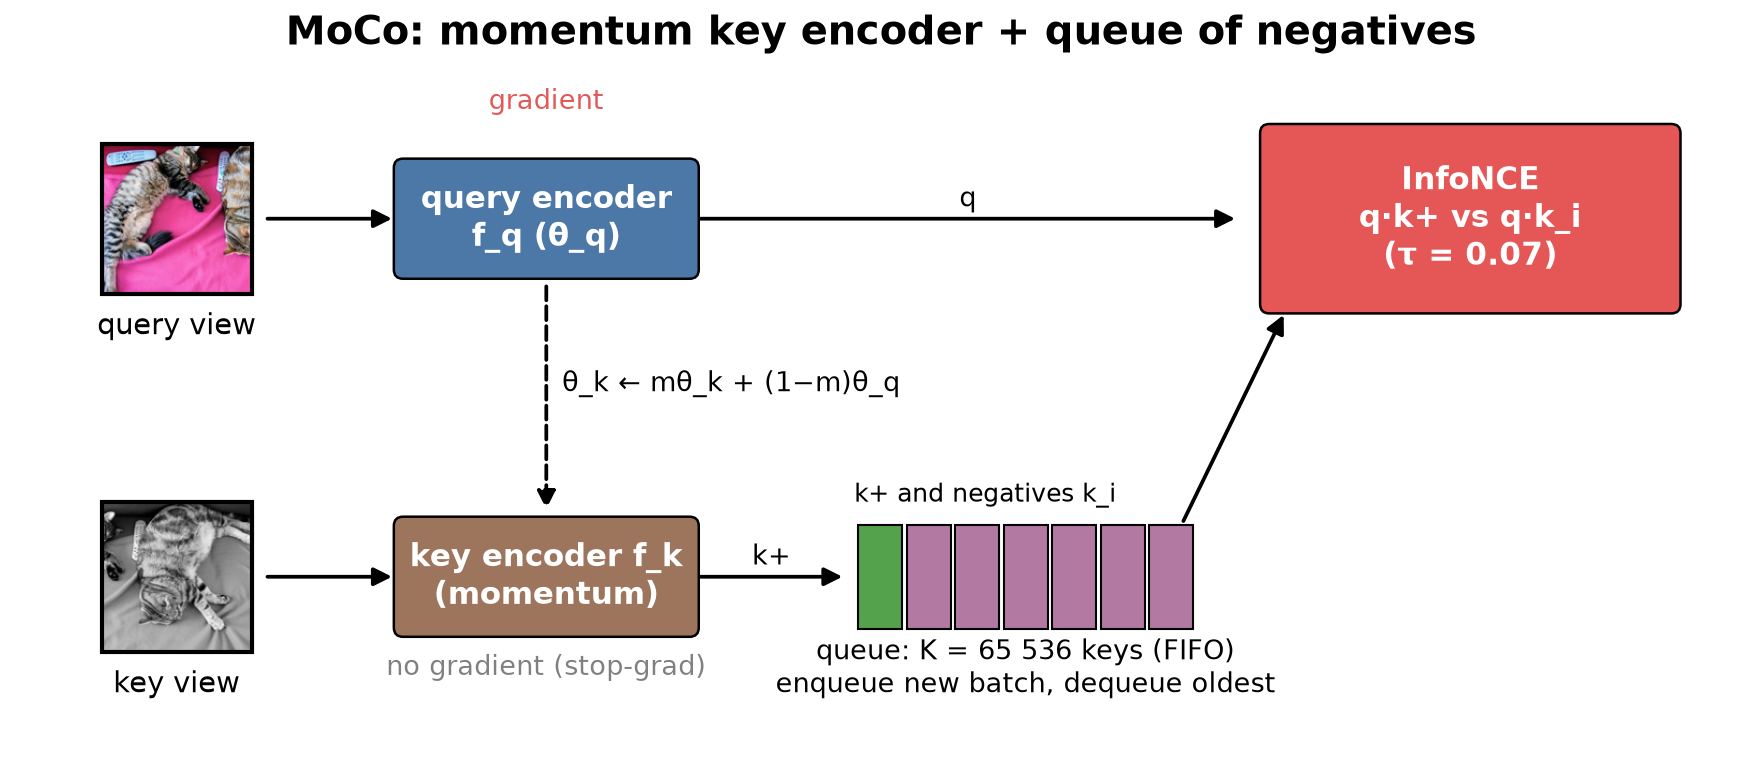

Компоненты:

1. Очередь ключей (FIFO) размера $K=65\,536$. После каждого шага эмбеддинги текущего батча добавляются в очередь, самые старые удаляются.
2. Momentum-энкодер ключей $f_k$. Если бы ключи считал тот же энкодер, что обучается градиентом, ключи в очереди, посчитанные разными версиями сети, были бы несогласованы. Поэтому $f_k$ обновляется медленно:
$
\theta_k\leftarrow m\,\theta_k+(1-m)\,\theta_q,\qquad m=0.999.
$
   При $m=0.999$ эффективное «окно» усреднения — около $1/(1-m)=1000$ шагов.
3. Потеря InfoNCE с $\tau=0.07$ между запросом $q=f_q(x^q)$, позитивом $k_+=f_k(x^k)$ и ключами из очереди.
4. Shuffling BN. Внутри батча BatchNorm позволяет запросу и его позитиву «общаться» через общие статистики, и модель находит путь уменьшить потерю, не уча хороших признаков. MoCo перемешивает примеры между GPU для ключевого энкодера, чтобы статистики позитива и запроса считались по разным подвыборкам ([MoCo](https://arxiv.org/abs/1911.05722)).

Результаты: MoCo v1 с ResNet-50 — 60.6% linear top-1 на ImageNet ([MoCo](https://arxiv.org/abs/1911.05722)). [MoCo v2](https://arxiv.org/abs/2003.04297) добавил MLP-голову и более сильные аугментации из SimCLR и достиг 71.1% при обычном размере батча.

```python
class MoCoQueue:
    def __init__(self, dim, K=65536):
        self.q = F.normalize(torch.randn(K, dim), dim=1); self.ptr = 0
    @torch.no_grad()
    def push(self, k):                                  # k: [B, dim], уже нормированы
        B = k.shape[0]; idx = (self.ptr + torch.arange(B)) % self.q.shape[0]
        self.q[idx] = k; self.ptr = int((self.ptr + B) % self.q.shape[0])

@torch.no_grad()
def momentum_update(f_q, f_k, m=0.999):
    for pq, pk in zip(f_q.parameters(), f_k.parameters()):
        pk.mul_(m).add_(pq.detach(), alpha=1 - m)

def moco_loss(q, k, queue, tau=0.07):
    q, k = F.normalize(q, dim=1), F.normalize(k, dim=1)
    l_pos = (q * k).sum(1, keepdim=True)                 # [B, 1]
    l_neg = q @ queue.q.T                                 # [B, K]
    logits = torch.cat([l_pos, l_neg], 1) / tau
    return F.cross_entropy(logits, torch.zeros(len(q), dtype=torch.long, device=q.device))
```

### 2.6. Alignment и uniformity

[Wang и Isola](https://arxiv.org/abs/2005.10242) дали геометрическое объяснение того, что оптимизирует контрастная потеря на единичной гиперсфере. Определения ($f$ нормирован, $\alpha>0, t>0$):

$
\mathcal L_{\text{align}}(f;\alpha)=\mathbb E_{(x,y)\sim p_{\text{pos}}}\big\|f(x)-f(y)\big\|_2^{\alpha},\qquad
\mathcal L_{\text{uniform}}(f;t)=\log\mathbb E_{x,y\overset{\text{iid}}{\sim}p_{\text{data}}}e^{-t\|f(x)-f(y)\|_2^2}.
$

В реализации авторов по умолчанию $\alpha=2$, $t=2$. Теорема 1 из статьи: при числе негативов $M\to\infty$

$
\mathcal L_{\text{contr}}-\log M\ \to\ -\frac1\tau\,\mathbb E_{\text{pos}}\big[f(x)^\top f(y)\big]+\mathbb E_x\Big[\log\mathbb E_{x^-}e^{f(x^-)^\top f(x)/\tau}\Big].
$

Первый член минимален при идеальном alignment. Второй минимизируется равномерным на сфере распределением, если такое существует. Отклонение от предела убывает как $O(M^{-1/2})$. Авторы показали, что прямая оптимизация $\mathcal L_{\text{align}}+\mathcal L_{\text{uniform}}$ даёт представления не хуже контрастных.

Полезный ориентир для чтения чисел. Для двух независимых точек, равномерных на сфере большой размерности, $\|u-v\|^2\approx2$. Тогда при $t=2$ имеем $\mathcal L_{\text{uniform}}\approx\log e^{-4}=-4$: это нижний предел на практике. Полный коллапс даёт $\mathcal L_{\text{uniform}}=0$.

В практикуме (раздел 13.1) uniformity и эффективный ранг считаются для пяти предобученных ViT, а в разделе 10.3 — для искусственных облаков точек. Важно читать оба числа вместе: alignment без uniformity ничего не значит, потому что идеальное совпадение видов достигается и при коллапсе.

## 3. Методы без негативов

### 3.1. Коллапс и как его измерять

Если убрать негативы и требовать только близости видов, тривиальное решение $f(x)\equiv c$ даёт нулевую потерю. Различают два вида коллапса (рис. 11).

- Полный коллапс: все эмбеддинги совпадают.
- Размерностный коллапс: эмбеддинги различаются, но занимают подпространство малой размерности. Часть «осей» пропадает, и информация о многих факторах теряется.

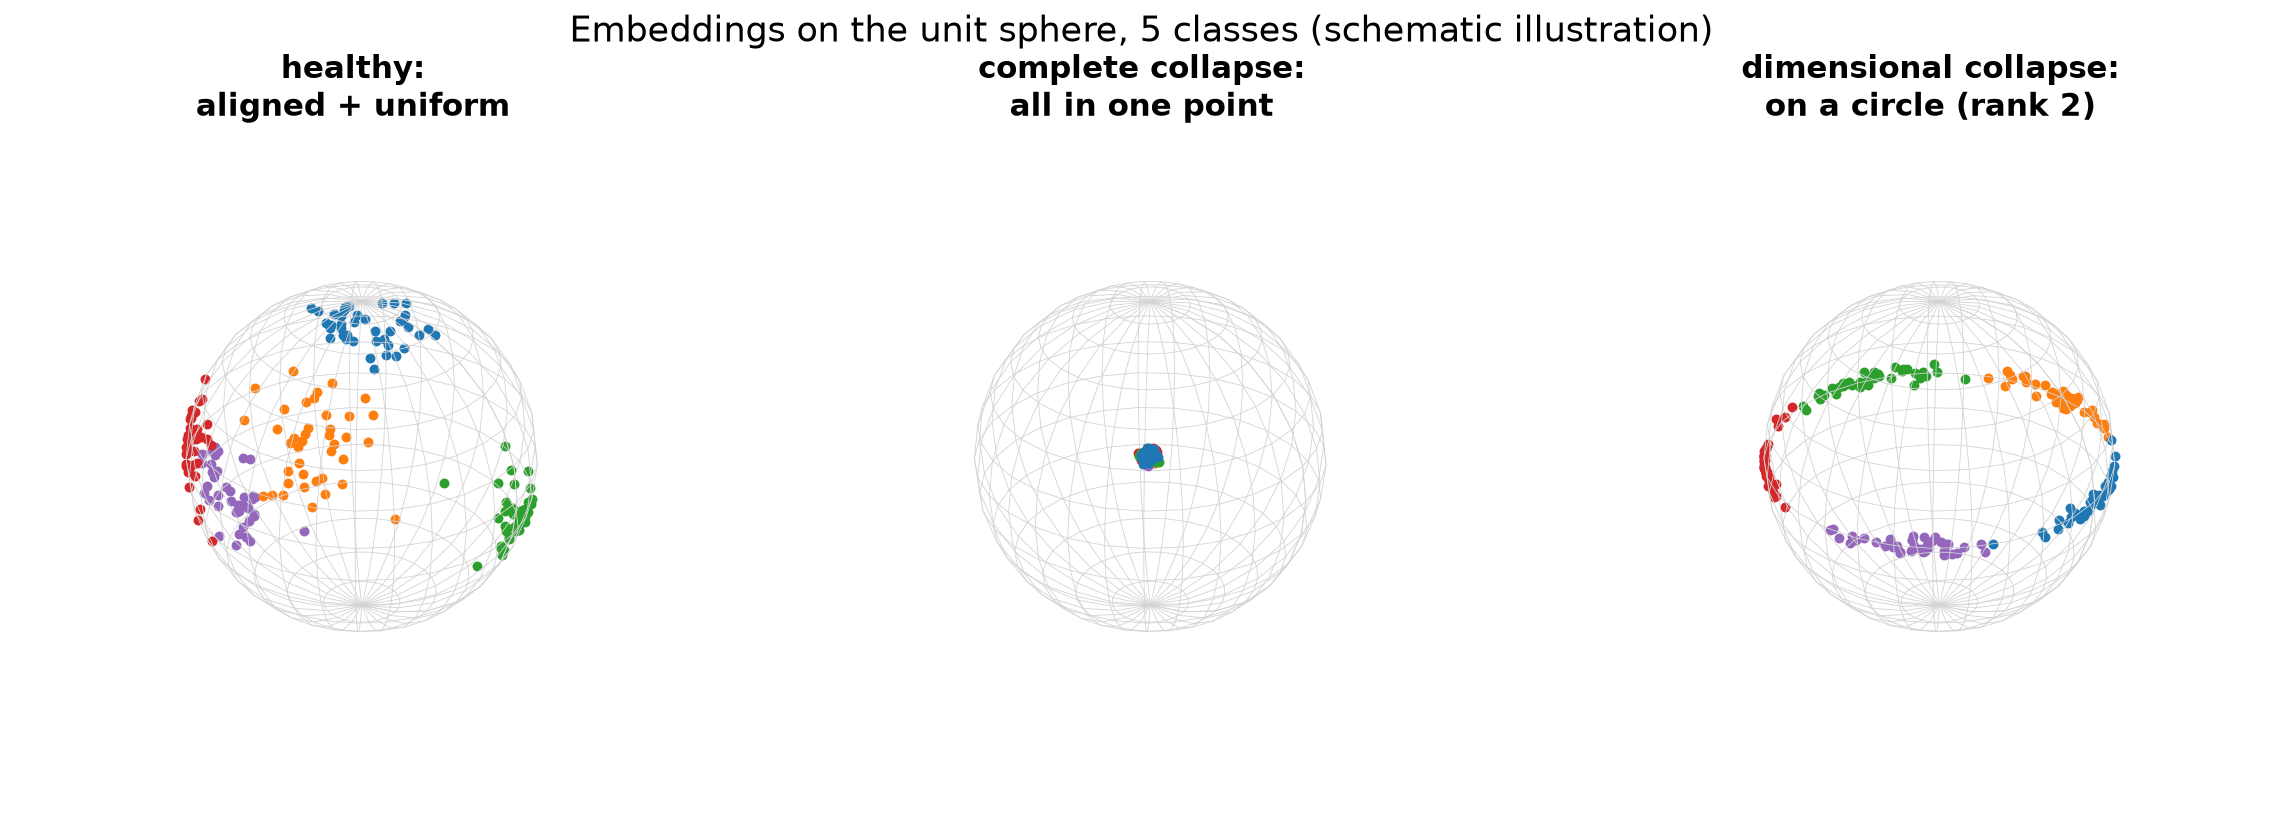

Мониторинг во время обучения:

1. Стандартное отклонение нормированных эмбеддингов по батчу, усреднённое по координатам. При полном коллапсе оно падает к нулю. Для нормированных векторов без коллапса ориентир около $1/\sqrt d$.
2. Спектр сингулярных чисел матрицы нормированных эмбеддингов батча и эффективный ранг ([Roy, Vetterli, 2007](https://infoscience.epfl.ch/record/110188)); без центрирования это метрика RankMe ([Garrido et al., 2023](https://arxiv.org/abs/2210.02885)):
$
\mathrm{erank}(Z)=\exp\Big(-\sum_k p_k\log p_k\Big),\qquad p_k=\frac{\sigma_k}{\sum_j\sigma_j}.
$
   Эффективный ранг лежит между 1 и $d$. Его резкое падение сигнализирует о размерностном коллапсе.
3. Uniformity (раздел 2.6) и, для DINO-подобных методов, энтропия выхода учителя (раздел 3.4).

Реализация мониторов — раздел 10.3 практикума, их поведение при обучении и при специально сломанных методах — раздел 11, спектры признаков предобученных энкодеров — раздел 13.1. Эффективный ранг — необходимое, а не достаточное условие качества: можно иметь высокий ранг и шумные признаки.

### 3.2. BYOL

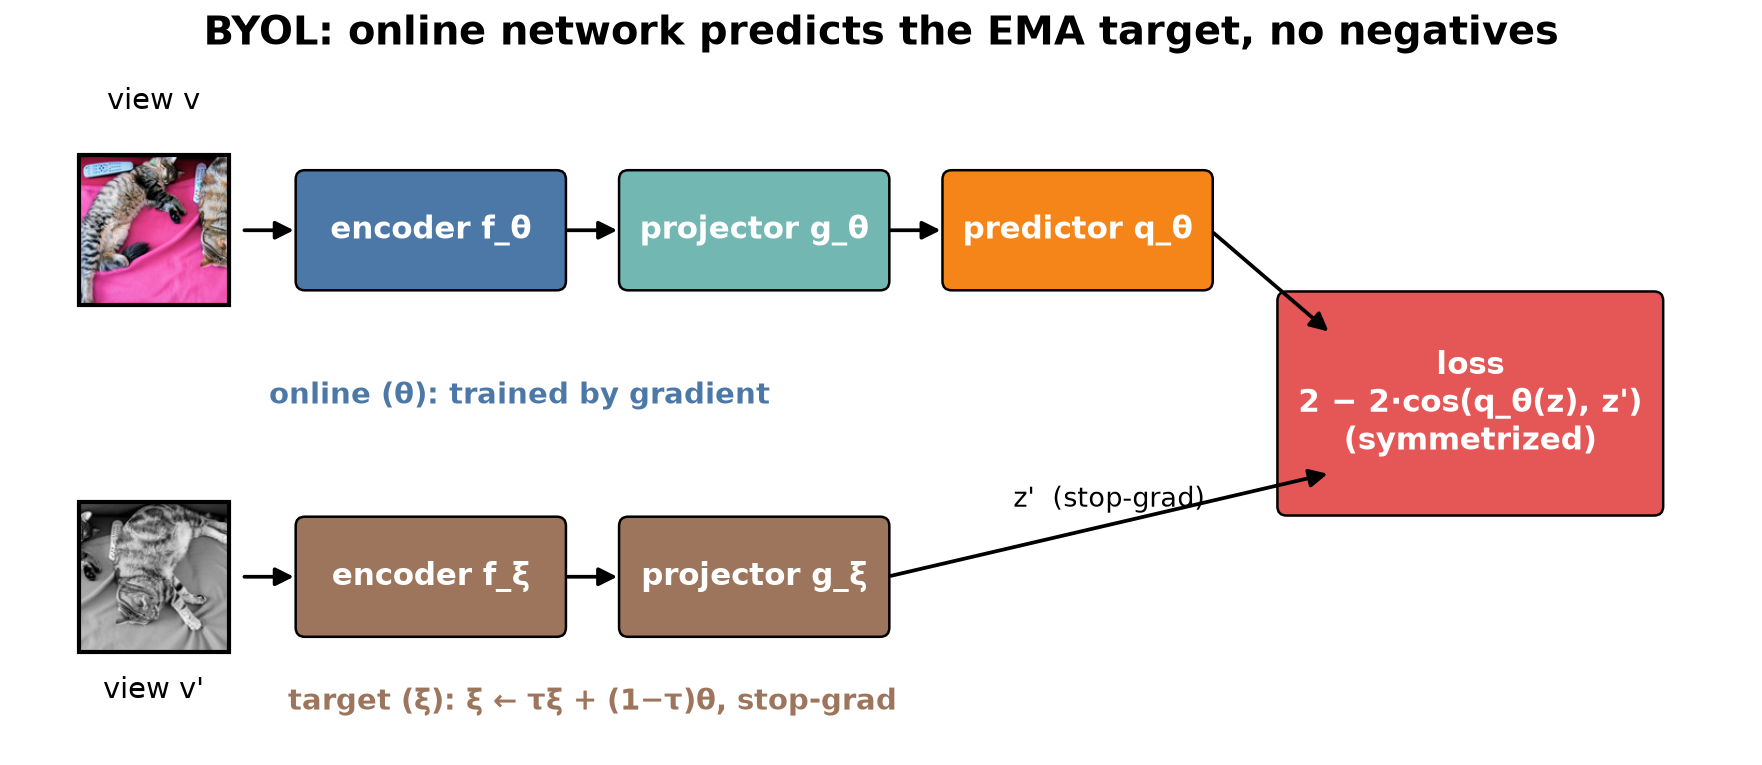

[BYOL](https://arxiv.org/abs/2006.07733) состоит из двух сетей.

Online-сеть с параметрами $\theta$:

- энкодер $f_\theta$;
- проектор $g_\theta$;
- предиктор $q_\theta$. Он есть только в online-ветви; это MLP 4096 → 256 с BatchNorm и ReLU.

Target-сеть с параметрами $\xi$:

- те же энкодер и проектор, без предиктора;
- градиент через неё не идёт;
- веса обновляются как EMA online-сети.

Потеря — квадрат расстояния между нормированными векторами, что эквивалентно $2-2\cos$:

$
\mathcal L_{\theta,\xi}=\Big\|\frac{q_\theta(z_\theta)}{\|q_\theta(z_\theta)\|}-\frac{z'_\xi}{\|z'_\xi\|}\Big\|_2^2=2-2\cos\big(q_\theta(z_\theta),z'_\xi\big),
\qquad
\mathcal L^{\text{BYOL}}=\mathcal L_{\theta,\xi}+\widetilde{\mathcal L}_{\theta,\xi},
$

где $\widetilde{\mathcal L}$ — та же потеря с переставленными видами. Оптимизация идёт только по $\theta$. Target-сеть обновляется по формуле

$
\xi\leftarrow\tau\xi+(1-\tau)\theta,\qquad
\tau_k=1-(1-\tau_{\text{base}})\frac{\cos(\pi k/K)+1}{2},\quad\tau_{\text{base}}=0.996,
$

то есть $\tau$ плавно растёт от 0.996 до 1 к концу обучения ($k$ — шаг, $K$ — число шагов).

Почему нет коллапса, хотя константа — решение. Авторы [BYOL](https://arxiv.org/abs/2006.07733) прямо пишут, что функция потерь допускает коллапс, но в экспериментах он не наблюдался. Объяснение в статье:

1. Предиктор делает ветви асимметричными. Если предиктор близок к оптимальному, обновление online-сети действует как спуск по условной дисперсии target-представления при данном online-представлении. Выбрасывание информации эту дисперсию не уменьшает, поэтому константные признаки неустойчивы.
2. Медленная target-сеть держит предиктор вблизи оптимума, поскольку цели меняются плавно.
3. В абляциях хорошо работал только вариант, где есть и предиктор, и EMA-target. Удаление любого компонента вело к коллапсу или резкому падению качества. Авторы также сообщают, что EMA можно убрать, если поддерживать предиктор достаточно хорошим, например повышенной скоростью обучения предиктора.

Устойчивость к батчу и аугментациям (ImageNet linear top-1, 300 эпох; [BYOL](https://arxiv.org/abs/2006.07733)):

| Условие | BYOL | SimCLR |
|---|---|---|
| Батч 4096 | 72.5 | 67.9 |
| Батч 512 | 72.2 | 66.5 |
| Батч 256 | 71.8 | 64.3 |
| Без color jitter и grayscale | 63.4 | 45.7 |
| Только random crop | 59.4 | 40.3 |

Итог полной версии: 74.3% linear top-1 для ResNet-50 и 79.6% для более широкой сети ([BYOL](https://arxiv.org/abs/2006.07733)).

### 3.3. SimSiam: минимальная версия

[SimSiam](https://arxiv.org/abs/2011.10566) показал, что можно обойтись без негативов, без больших батчей и даже без momentum-энкодера. Достаточно сиамской сети с предиктором и операции stop-gradient на одной ветви:

$
\mathcal L=\tfrac12 D\big(p_1,\mathrm{sg}(z_2)\big)+\tfrac12 D\big(p_2,\mathrm{sg}(z_1)\big),\qquad D(p,z)=-\cos(p,z).
$

Авторы подтверждают, что коллапсирующие решения у этой потери существуют, и именно stop-gradient играет ключевую роль в их избегании ([SimSiam](https://arxiv.org/abs/2011.10566)). Для учебных экспериментов в Colab SimSiam и BYOL — самые удобные отправные точки: они просты и не требуют большого батча.

### 3.4. DINO

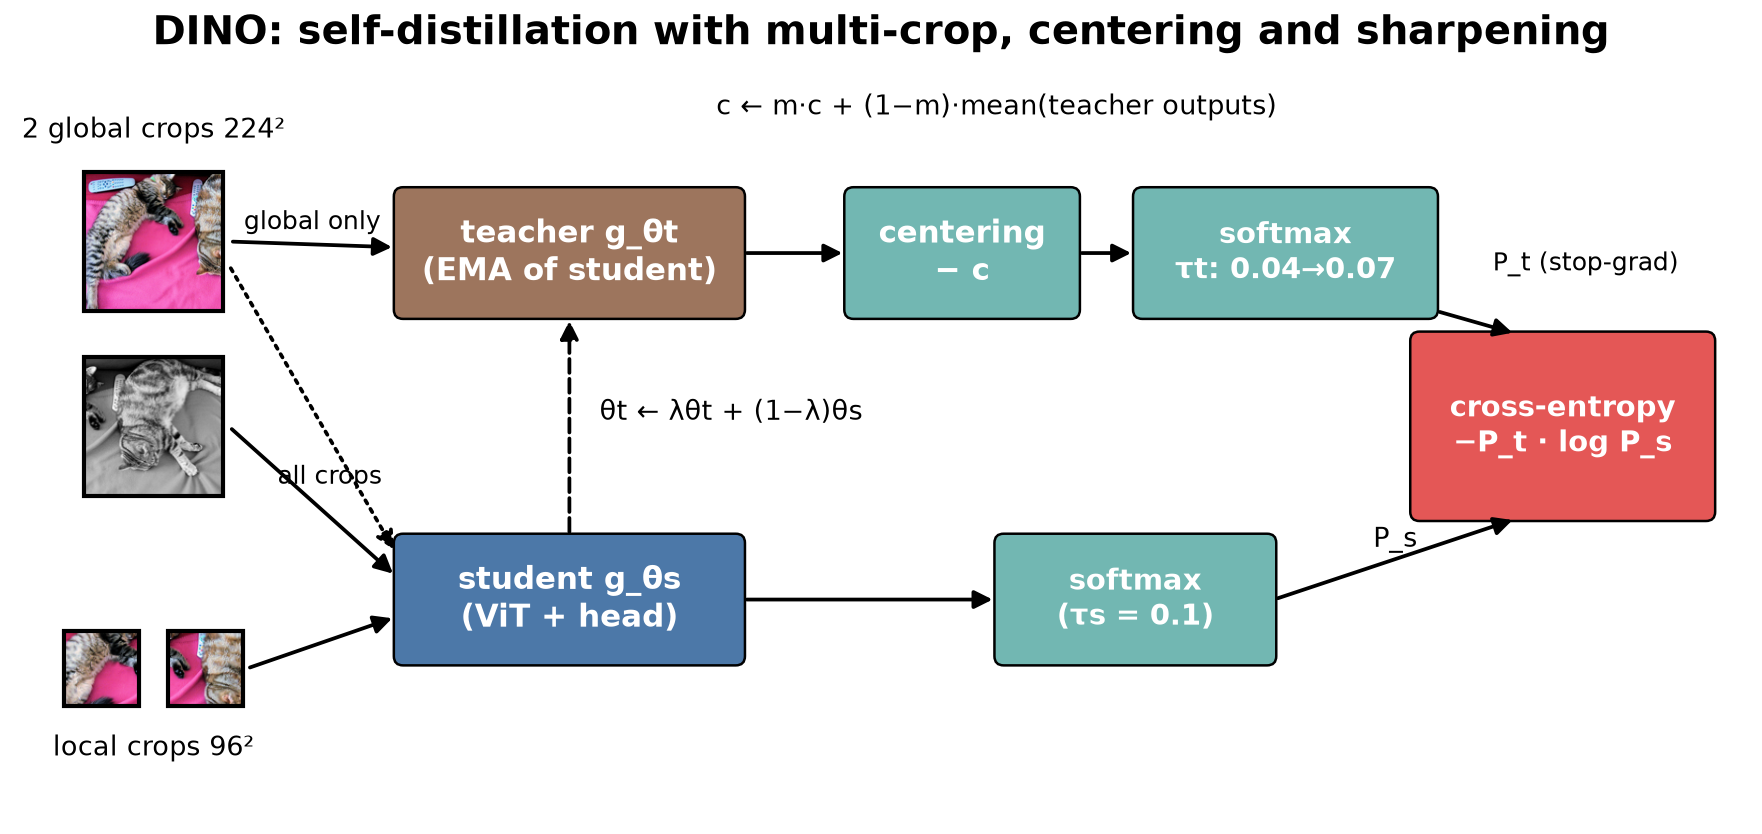

[DINO](https://arxiv.org/abs/2104.14294) (self-distillation with no labels) переносит идею BYOL на ViT. Вместо регрессии векторов он сопоставляет распределения над $K$ измерениями выхода головы: $K=65\,536$ по умолчанию.

Учитель — EMA студента, $\theta_t\leftarrow\lambda\theta_t+(1-\lambda)\theta_s$, где $\lambda$ растёт по косинусу от 0.996 до 1. Учитель лучше студента на протяжении обучения: усреднение весов работает как ансамбль моделей по времени.

Multi-crop:

- 2 глобальных кропа $224^2$ и несколько локальных $96^2$ (в разных опытах 2, 6 или 10);
- учитель видит только глобальные, студент — все;
- в итоге студент учится по фрагменту предсказывать «смысл» всего изображения.

Распределения:

$
P_s(x)=\mathrm{softmax}\big(g_{\theta_s}(x)/\tau_s\big),\qquad
P_t(x)=\mathrm{softmax}\big((g_{\theta_t}(x)-c)/\tau_t\big),
$

где $\tau_s=0.1$, а $\tau_t$ линейно растёт от 0.04 до 0.07 за первые 30 эпох.

Потеря:

$
\mathcal L=\sum_{x\in\{x^g_1,x^g_2\}}\ \sum_{\substack{x'\in V\\x'\ne x}}H\big(P_t(x),P_s(x')\big).
$

Центрирование: $c\leftarrow m\,c+(1-m)\frac1B\sum_{i=1}^{B}g_{\theta_t}(x_i)$, $m=0.9$.

Почему нужны и центрирование, и заострение. Разложим кросс-энтропию:

$
H(P_t,P_s)=H(P_t)+\mathrm{KL}(P_t\,\|\,P_s).
$

Возможны два вида коллапса:

- «Одна размерность доминирует»: $P_t$ становится one-hot в одном и том же измерении для всех изображений.
- «Равномерный выход»: $P_t$ равномерно для всех изображений.

В обоих случаях студент легко копирует учителя, и $\mathrm{KL}\to0$. Механизмы действуют так:

- Центрирование вычитает средний по батчу логит. Ни одно измерение не может систематически выигрывать, и выход толкается к равномерному.
- Заострение, то есть малое $\tau_t$, делает $P_t$ пиковым и толкает от равномерного.

Только баланс двух противоположных сил предотвращает коллапс ([DINO](https://arxiv.org/abs/2104.14294)). В абляции слишком медленное центрирование ($m=0.999$) приводило к коллапсу.

На практике полезно логировать $H(P_t)$ и $\mathrm{KL}(P_t\|P_s)$. Если энтропия учителя уходит в $\log K$ (равномерный выход) или в 0, а KL к нулю, обучение коллапсировало.

```python
class DINOLoss(torch.nn.Module):
    def __init__(self, K, tau_s=0.1, m=0.9):
        super().__init__(); self.tau_s, self.m = tau_s, m
        self.register_buffer("c", torch.zeros(1, K))

    def forward(self, s_out, t_out, tau_t):
        """s_out: логиты студента по всем видам (сначала 2 глобальных); t_out: логиты учителя по 2 глобальным."""
        t_prob = [F.softmax((t - self.c) / tau_t, -1).detach() for t in t_out]
        loss, n = 0.0, 0
        for i, pt in enumerate(t_prob):
            for j, s in enumerate(s_out):
                if j == i:
                    continue                                   # тот же вид не сравниваем
                loss = loss + (-pt * F.log_softmax(s / self.tau_s, -1)).sum(-1).mean(); n += 1
        with torch.no_grad():
            self.c.mul_(self.m).add_((1 - self.m) * torch.cat(t_out).mean(0, keepdim=True))
        return loss / n

def teacher_entropy(t_logits, c, tau_t):           # монитор коллапса
    p = F.softmax((t_logits - c) / tau_t, -1)
    return -(p * torch.log(p + 1e-12)).sum(-1).mean()
```

Результаты [DINO](https://arxiv.org/abs/2104.14294) на ImageNet (замороженные признаки):

| Модель | Linear, % | k-NN, % |
|---|---|---|
| ViT-S/16 | 77.0 | 74.5 |
| ViT-S/8 | 79.7 | 78.3 |
| ViT-B/8 | 80.1 | 77.4 |

Меньший патч (8 вместо 16) даёт больше токенов и лучшее качество ценой вычислений.

Emergent properties. Карты внимания [CLS]-токена последнего слоя выделяют объекты без какой-либо разметки. Признаки особенно хороши для k-NN: у ViT-S/16 74.5% k-NN при 77.0% linear ([DINO](https://arxiv.org/abs/2104.14294)).

### 3.5. SwAV: кластеры вместо пар

[SwAV](https://arxiv.org/abs/2006.09882) — мост между контрастными методами и DINOv2.

Устройство:

- Вместо попарного сравнения признаков каждый вид относится к одному из $K$ обучаемых прототипов $C=[c_1,\dots,c_K]$.
- Модель учится «перекрёстному предсказанию»: по признаку одного вида предсказывается код (мягкое назначение кластерам) другого вида:
$
L(z_t,z_s)=\ell(z_t,q_s)+\ell(z_s,q_t),\qquad
\ell(z_t,q_s)=-\sum_k q_s^{(k)}\log\frac{\exp(z_t^\top c_k/\tau)}{\sum_{k'}\exp(z_t^\top c_{k'}/\tau)}.
$
- Коды $Q$ считаются онлайн для батча как решение задачи оптимального транспорта с энтропийной регуляризацией:
$
\max_{Q\in\mathcal Q}\ \mathrm{Tr}(Q^\top C^\top Z)+\varepsilon H(Q),\qquad
\mathcal Q=\Big\{Q\in\mathbb R_+^{K\times B}:\ Q\mathbf 1_B=\tfrac1K\mathbf 1_K,\ Q^\top\mathbf 1_K=\tfrac1B\mathbf 1_B\Big\}.
$
  Ограничение равномерного разбиения (equipartition) запрещает назначить все изображения одному прототипу. Это и есть механизм против коллапса.
- Задача решается алгоритмом Sinkhorn-Knopp: на практике 3 итерации, $\varepsilon=0.05$.
- SwAV ввёл multi-crop ($2\times224+6\times96$), позже заимствованный DINO.

Результат: ResNet-50 — 75.3% top-1 на ImageNet в linear evaluation ([SwAV](https://arxiv.org/abs/2006.09882)).

```python
@torch.no_grad()
def sinkhorn(scores, eps=0.05, n_iter=3):
    """scores: [B, K] = z @ C. Возвращает мягкие коды Q: [B, K], строки суммируются в 1."""
    Q = torch.exp(scores / eps).T                 # [K, B]
    Q /= Q.sum(); K, B = Q.shape
    for _ in range(n_iter):
        Q /= Q.sum(1, keepdim=True); Q /= K      # равные массы прототипов
        Q /= Q.sum(0, keepdim=True); Q /= B      # равные массы примеров
    return (Q * B).T
```

### 3.6. Регуляризация статистик: Barlow Twins и VICReg

Третий способ избежать коллапса — явно штрафовать вырожденные статистики эмбеддингов батча.

[Barlow Twins](https://arxiv.org/abs/2103.03230) строит матрицу кросс-корреляций $C$ между эмбеддингами двух видов, нормированными по батчу, и тянет её к единичной:

$
\mathcal L_{BT}=\sum_i\big(1-C_{ii}\big)^2+\lambda\sum_i\sum_{j\ne i}C_{ij}^2,\qquad
C_{ij}=\frac{\sum_b z^A_{b,i}z^B_{b,j}}{\sqrt{\sum_b(z^A_{b,i})^2}\sqrt{\sum_b(z^B_{b,j})^2}}.
$

- Первый член — инвариантность: каждая координата одинакова для двух видов.
- Второй — снижение избыточности: разные координаты декоррелированы. Это прямо запрещает размерностный коллапс.

Подробности:

- $\lambda=5\cdot10^{-3}$;
- проектор из трёх слоёв по 8192 нейрона: метод выигрывает от очень высокой размерности;
- ResNet-50 — 73.2% linear top-1;
- не нужны ни большой батч, ни асимметрия ветвей ([Barlow Twins](https://arxiv.org/abs/2103.03230)).

[VICReg](https://arxiv.org/abs/2105.04906) раскладывает требования на три явных члена:

$
\ell(Z,Z')=\lambda\,s(Z,Z')+\mu\big[v(Z)+v(Z')\big]+\nu\big[c(Z)+c(Z')\big],
$
$
s=\frac1n\sum_i\|z_i-z'_i\|_2^2,\quad
v(Z)=\frac1d\sum_{j=1}^{d}\max\big(0,\gamma-\sqrt{\mathrm{Var}(z_{\cdot j})+\epsilon}\big),\quad
c(Z)=\frac1d\sum_{i\ne j}[C(Z)]_{ij}^2.
$

Члены:

- invariance $s$ — близость видов;
- variance $v$ — каждая координата должна иметь стандартное отклонение не ниже $\gamma=1$ по батчу, это запрет полного коллапса;
- covariance $c$ — декорреляция координат, запрет размерностного коллапса.

Коэффициенты по умолчанию $\lambda=\mu=25$, $\nu=1$. ResNet-50 — 73.2% linear top-1 ([VICReg](https://arxiv.org/abs/2105.04906)). Члены интерпретируемы, поэтому VICReg удобен для учебных экспериментов: каждое слагаемое можно логировать и выключать.

```python
def vicreg_loss(z1, z2, lam=25.0, mu=25.0, nu=1.0, gamma=1.0, eps=1e-4):
    n, d = z1.shape
    inv = F.mse_loss(z1, z2, reduction="none").sum(1).mean()
    def var(z): return F.relu(gamma - torch.sqrt(z.var(0) + eps)).mean()
    def cov(z):
        z = z - z.mean(0); C = (z.T @ z) / (n - 1)
        return (C.pow(2).sum() - C.diagonal().pow(2).sum()) / d
    return lam * inv + mu * (var(z1) + var(z2)) + nu * (cov(z1) + cov(z2))
```

### 3.7. DINOv2

[DINOv2](https://arxiv.org/abs/2304.07193) — не новый принцип, а тщательно собранный рецепт масштабирования.

Данные LVD-142M:

- исходный пул — 1.2 млрд уникальных веб-изображений после фильтрации;
- дедупликация, включая удаление почти-дубликатов изображений из тестовых наборов бенчмарков;
- эмбеддинги считаются самообученным ViT-H/16;
- для каждого изображения из курируемых наборов (ImageNet-22k, Google Landmarks, ряд fine-grained наборов) извлекаются ближайшие соседи, $N=4$;
- итог — 142 млн изображений.

Отбор данных по «похожести на полезное» — существенная часть успеха. Он же означает, что представление настроено на распределение, близкое к курируемым наборам.

Потеря:

1. DINO-потеря на [CLS] (раздел 3.4).
2. iBOT-потеря на маскированных патчах (раздел 4.4). У двух потерь раздельные головы: на больших масштабах это работало лучше общей головы.
3. Регуляризатор KoLeo, основанный на оценке дифференциальной энтропии Козаченко-Леоненко. Он расталкивает признаки внутри батча:
$
\mathcal L_{\text{KoLeo}}=-\frac1n\sum_{i=1}^{n}\log d_{n,i},\qquad d_{n,i}=\min_{j\ne i}\|x_i-x_j\|,
$
   причём признаки предварительно $\ell_2$-нормируются.
4. Центрирование учителя через Sinkhorn-Knopp (3 итерации) вместо EMA-центра, как в SwAV.

Обучение и семейство моделей:

- короткая финальная фаза на разрешении $518\times518$ улучшает плотные признаки;
- ViT-g/14 с 1.1 млрд параметров обучен с нуля;
- модели поменьше (ViT-S/B/L) получены дистилляцией из замороженного ViT-g, а не обучены независимо ([DINOv2](https://arxiv.org/abs/2304.07193)).

В абляции на ViT-L полный рецепт даёт 82.0% k-NN и 84.5% linear на ImageNet-1k.

Регистры. [Darcet et al.](https://arxiv.org/abs/2309.16588) обнаружили, что в картах признаков больших ViT, обученных как с учителем, так и без, появляются артефактные токены с высокой нормой. Они возникают в малоинформативных фоновых областях, и модель использует их как «черновик» для глобальных вычислений. Решение — добавить на вход несколько обучаемых токенов-регистров, которые берут эту роль на себя. Карты признаков и внимания становятся гладкими, качество плотных задач растёт. Для сегментации и детекции берите варианты DINOv2 с регистрами (в timm — суффикс `reg4`).

### 3.8. DINOv3 (обзорно)

[DINOv3](https://ai.meta.com/research/dinov3/) масштабирует подход ещё раз: модель примерно в 6 раз больше, данных примерно в 12 раз больше, ViT с 7 млрд параметров на 1.7 млрд изображений. Главная методическая проблема, описанная в [техническом отчёте](https://arxiv.org/abs/2508.10104): при длительном обучении плотные (патчевые) признаки деградируют, хотя глобальные продолжают улучшаться.

Решение — Gram anchoring:

- матрица попарных сходств патчей студента $F_SF_S^\top$ притягивается к такой же матрице более ранней контрольной точки той же модели («Gram teacher»), у которой патчевые признаки ещё чистые;
- ограничивается только относительная геометрия патчей, а сами признаки остаются свободными:
$
\mathcal L_{\text{Gram}}\propto\big\|F_SF_S^\top-F_GF_G^\top\big\|_F^2.
$

Модель 7B дистиллирована в семейство ViT и ConvNeXt. Отдельно выпущена модель для спутниковых снимков. Для курса это ориентир на будущее: в бесплатном Colab разумно работать с ViT-S/B.

### 3.9. Сводка по механизмам против коллапса

| Механизм | Где используется | Что делает |
|---|---|---|
| Негативы в знаменателе | SimCLR, MoCo | Явно расталкивает разные изображения (uniformity) |
| Асимметрия + EMA-цель | BYOL, DINO | Делает константу неустойчивой точкой динамики |
| Stop-gradient + предиктор | SimSiam | То же без EMA |
| Центрирование + заострение | DINO | Баланс против двух видов коллапса распределения |
| Равномерное разбиение (Sinkhorn) | SwAV, DINOv2 | Запрещает назначать всё одному прототипу |
| Декорреляция / дисперсия | Barlow Twins, VICReg | Прямой штраф размерностного и полного коллапса |
| KoLeo | DINOv2 | Расталкивает ближайших соседей в батче |
| Реконструкция входа | MAE | Константа не может восстановить разные изображения |

## 4. Masked image modeling

### 4.1. Идея и отличие от joint-embedding

В языковых моделях задача «восстанови пропущенное слово» (BERT) дала сильные представления. Masked image modeling (MIM) переносит её на изображения: часть патчей скрывается, модель восстанавливает скрытое. В отличие от методов частей 2–3, здесь не нужны вручную подобранные аугментации: обучающий сигнал создаёт маскирование.

Три способа поставить задачу показаны на рис. 12.

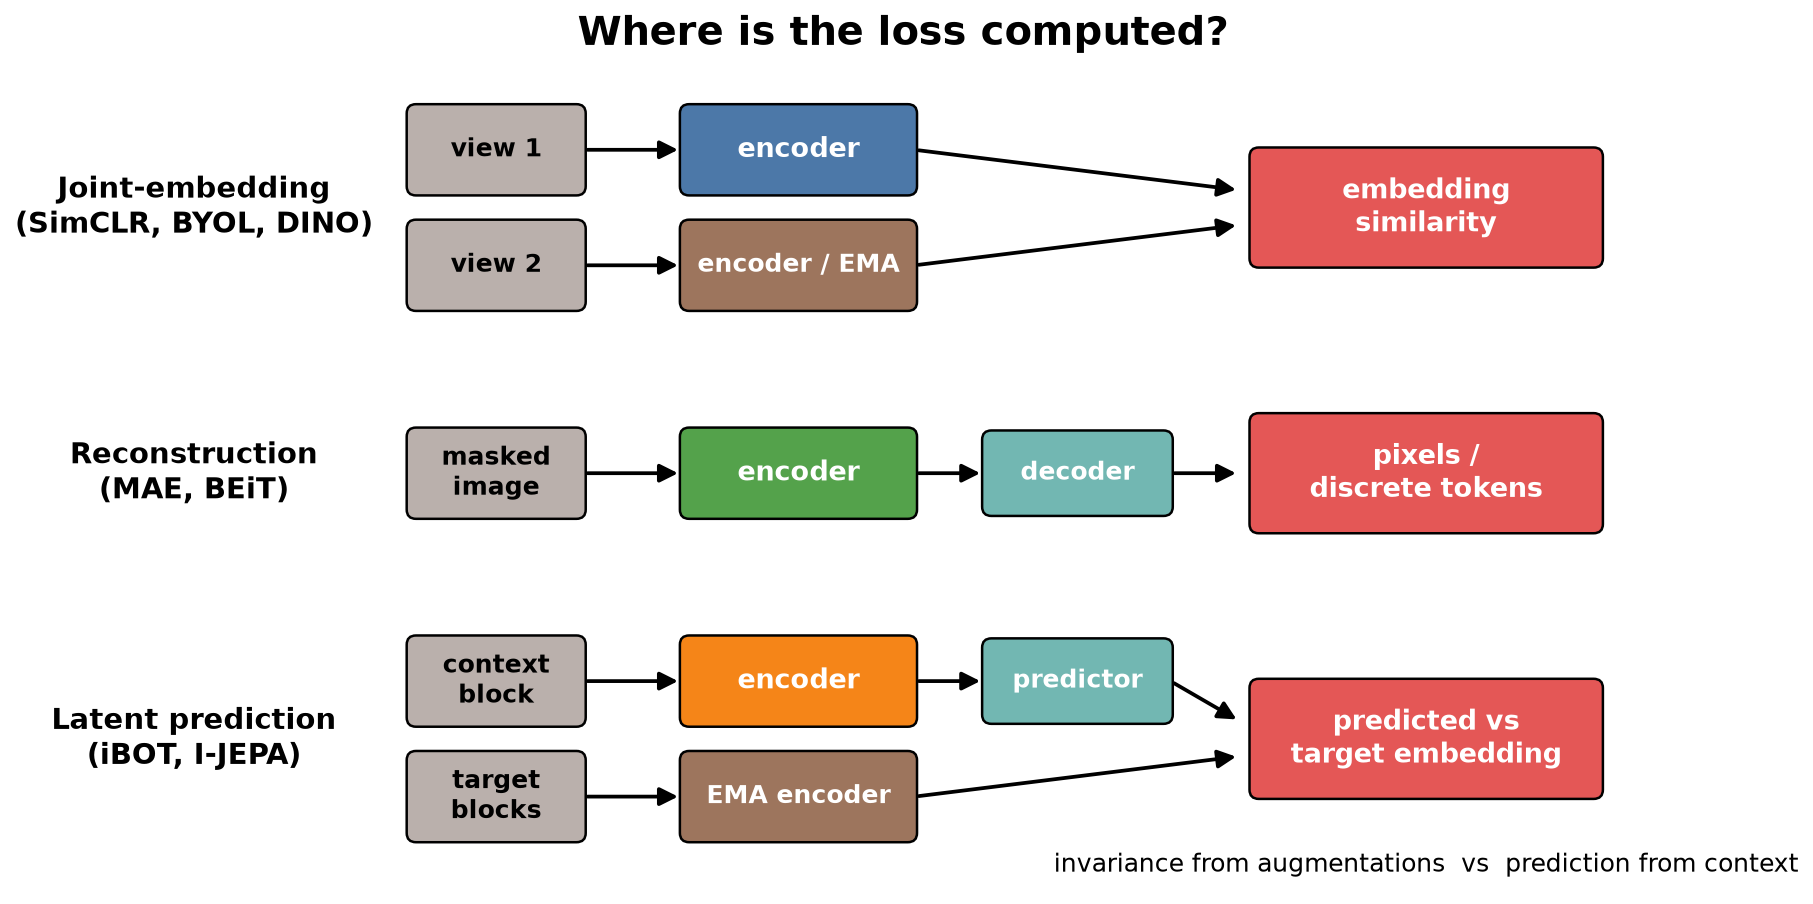

Следствия выбора цели:

- Joint-embedding (SimCLR, BYOL, DINO) учит инвариантности к аугментациям. Признаки сразу семантические и хорошо работают «как есть» (k-NN, linear probe). Но они наследуют предвзятость выбранных аугментаций.
- Реконструкция (MAE, BEiT) учит восстанавливать содержимое. Признаки содержат много низкоуровневой информации, нужной для реконструкции, и раскрываются при fine-tuning.
- Предсказание в пространстве признаков (iBOT, I-JEPA) — компромисс. Цель семантическая (эмбеддинг учителя), но не требует ручных аугментаций или требует их меньше.

### 4.2. BEiT

[BEiT](https://arxiv.org/abs/2106.08254) ввёл BERT-подобное предобучение ViT:

- изображение заранее переводится отдельным токенизатором в дискретные «визуальные токены»;
- часть патчей маскируется;
- модель предсказывает токены скрытых патчей.

Результаты: после fine-tuning base-модель BEiT даёт 83.2% top-1 на ImageNet-1K против 81.8% у DeiT, обученного с нуля в той же постановке. Large-модель — 86.3% только на ImageNet-1K ([BEiT](https://arxiv.org/abs/2106.08254)). Недостаток — двухэтапность: токенизатор нужно обучить заранее.

### 4.3. MAE

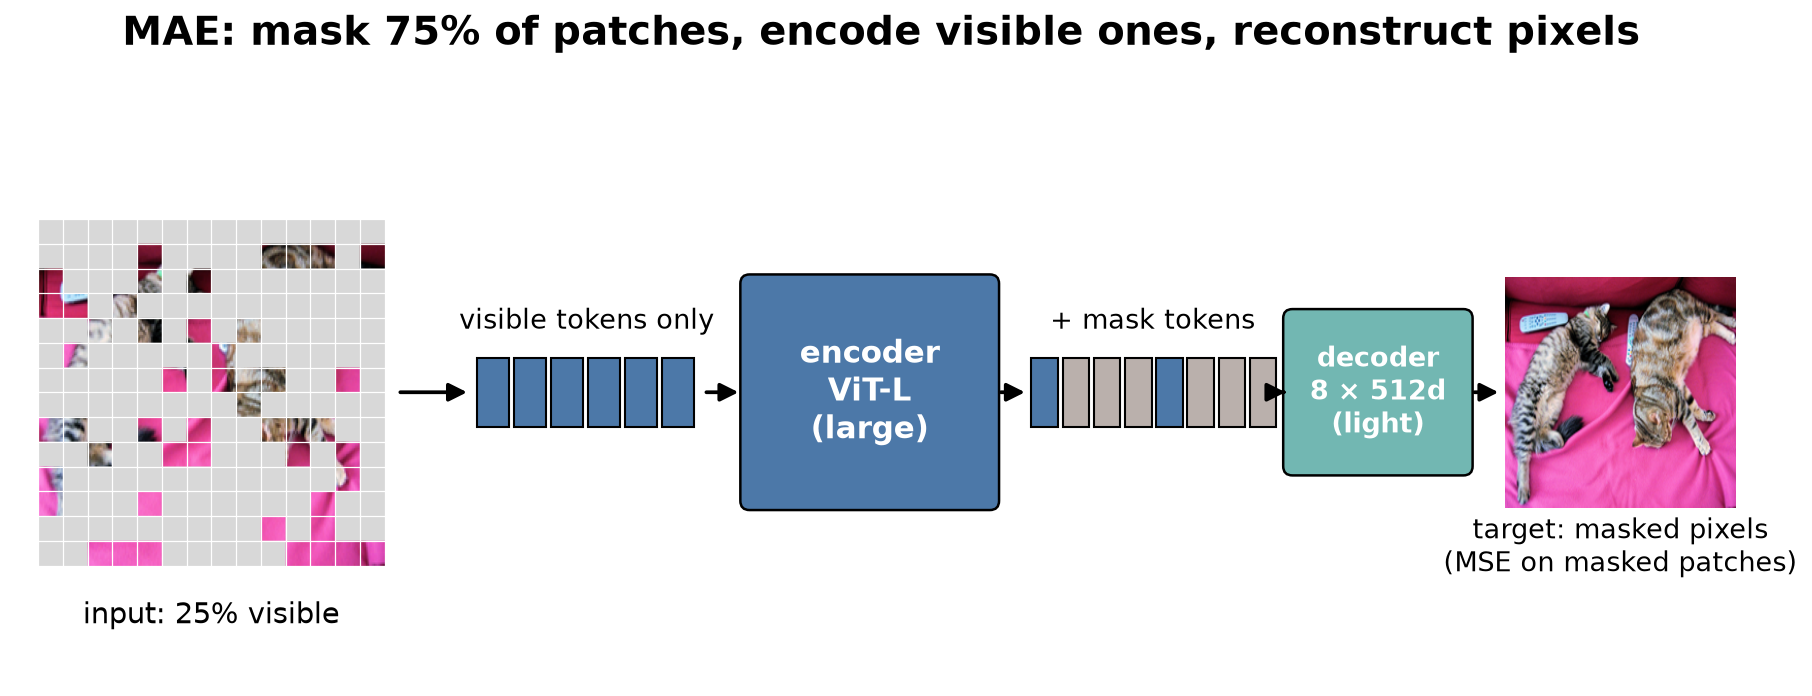

Конструкция [MAE](https://arxiv.org/abs/2111.06377):

1. Изображение режется на патчи 16×16, случайно маскируется 75%.
2. Асимметричная схема: энкодер (ViT) получает только 25% видимых патчей, без mask-токенов. Вычисления энкодера сокращаются примерно вчетверо, поэтому обучение ускоряется в 3 раза и более.
3. Лёгкий декодер получает закодированные видимые токены, mask-токены (один общий обучаемый вектор) и позиционные эмбеддинги для всех позиций. Декодер по умолчанию — 8 блоков ширины 512. Это около 9% FLOPs ViT-L на токен.
4. Восстанавливаются пиксели скрытых патчей.
5. После предобучения декодер выбрасывается.

Функция потерь — MSE только по маскированным патчам $M$, с нормированной целью:

$
\mathcal L_{\text{MAE}}=\frac1{|M|}\sum_{p\in M}\big\|\hat x_p-\tilde x_p\big\|_2^2,\qquad
\tilde x_p=\frac{x_p-\mu_p}{\sigma_p},
$

где $\mu_p,\sigma_p$ — среднее и стандартное отклонение пикселей самого патча $p$.

Почему именно так ([MAE](https://arxiv.org/abs/2111.06377)):

- Высокая доля маскирования. Изображения пространственно избыточны: при малой доле маски скрытый патч восстанавливается интерполяцией соседей, без «понимания» сцены. Разница в linear probing между малым и оптимальным маскированием достигает около 20 п.п. (54.6% против 73.5%). Fine-tuning устойчив в широком диапазоне 40–80%.
- Потеря только на скрытых патчах. Если считать её на всех, точность падает примерно на 0.5%.
- Нормированные пиксели. Модели не нужно тратить ёмкость на абсолютную яркость и контраст. Fine-tuning улучшается с 84.9% до 85.4% у ViT-L.
- Лучший результат — ViT-H, 87.8% после fine-tuning, обучение только на ImageNet-1K.

```python
def patchify(imgs, p=16):                                   # [B,3,H,W] -> [B, L, p*p*3]
    B, C, H, W = imgs.shape; h, w = H // p, W // p
    x = imgs.reshape(B, C, h, p, w, p).permute(0, 2, 4, 3, 5, 1)
    return x.reshape(B, h * w, p * p * C)

def random_masking(x, ratio=0.75):
    """x: [B, L, D] патч-токены. Возвращает видимые токены, маску (1 = скрыт) и индексы восстановления."""
    B, L, D = x.shape; keep = int(L * (1 - ratio))
    ids_shuffle = torch.rand(B, L, device=x.device).argsort(1); ids_restore = ids_shuffle.argsort(1)
    x_vis = torch.gather(x, 1, ids_shuffle[:, :keep, None].expand(-1, -1, D))
    mask = torch.ones(B, L, device=x.device); mask[:, :keep] = 0
    return x_vis, torch.gather(mask, 1, ids_restore), ids_restore

def mae_loss(pred, imgs, mask, norm_pix=True):
    target = patchify(imgs)
    if norm_pix:
        mu, var = target.mean(-1, keepdim=True), target.var(-1, keepdim=True)
        target = (target - mu) / (var + 1e-6).sqrt()
    per_patch = ((pred - target) ** 2).mean(-1)              # [B, L]
    return (per_patch * mask).sum() / mask.sum()
```

Linear probe против fine-tuning — ключевой урок. По [MAE](https://arxiv.org/abs/2111.06377), ViT-L:

| Сколько последних блоков дообучается | MAE, % | MoCo v3, % |
|---|---|---|
| 0 (linear probe) | 73.5 | 77.6 |
| 1 | 81.0 | 79.9 |
| 2 | 83.1 | 80.8 |
| 4 | 84.2 | 81.6 |
| 24 (полный fine-tuning) | 84.9 | 84.1 |

Признаки MAE хуже линейно разделимы, но после дообучения даже одного блока MAE обгоняет контрастный MoCo v3. Авторы отмечают, что linear probing не позволяет использовать сильные, но нелинейные признаки, и предлагают частичный fine-tuning как дополнительный протокол оценки. Насколько это заметно на CIFAR-10, проверяется в разделе 13 практикума.

### 4.4. iBOT: онлайн-токенизатор

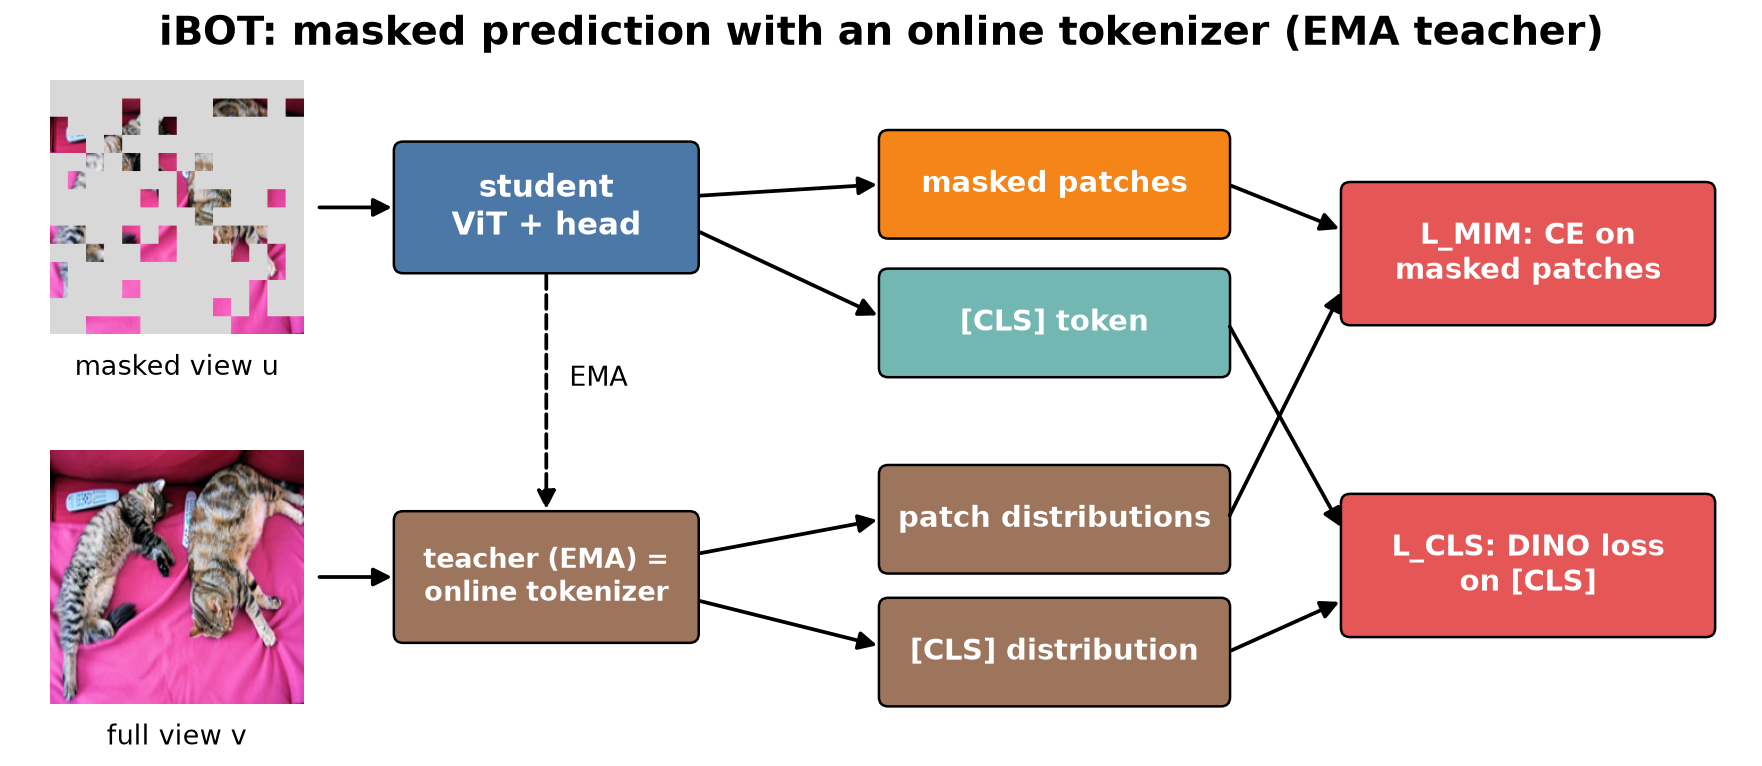

[iBOT](https://arxiv.org/abs/2111.07832) соединяет MIM и самодистилляцию DINO.

- Студент видит маскированный вид $\hat u$, учитель (EMA студента) — полный вид $v$.
- Для каждого маскированного патча студент предсказывает распределение, которое учитель выдал на этой позиции. Учитель играет роль токенизатора, причём «онлайн»: он учится вместе с моделью, и не нужен заранее обученный токенизатор, как в BEiT.
- На [CLS] — обычная DINO-потеря между видами.

$
\mathcal L_{\text{MIM}}=-\sum_{i\in M}P_t(v)_i^\top\log P_s(\hat u)_i,\qquad\mathcal L=\mathcal L_{\text{MIM}}+\mathcal L_{[\text{CLS}]}.
$

Результат: 82.3% linear probing и 87.8% fine-tuning на ImageNet-1K ([iBOT](https://arxiv.org/abs/2111.07832)). iBOT одновременно хорош и «как есть», и после дообучения. Его патчевая потеря отвечает за сильные плотные признаки DINOv2.

### 4.5. I-JEPA: предсказание в пространстве признаков без аугментаций

[I-JEPA](https://arxiv.org/abs/2301.08243) (Joint-Embedding Predictive Architecture):

- Из одного «контекстного» блока изображения предсказываются эмбеддинги нескольких «целевых» блоков того же изображения. Эмбеддинги целей считает EMA-энкодер, а предсказывает их отдельный предиктор.
- Метод не генеративный (пиксели не восстанавливаются) и не опирается на вручную подобранные аугментации.
- Критична стратегия маскирования: целевые блоки должны быть достаточно крупными, чтобы быть семантическими, а контекст — достаточно информативным и пространственно распределённым.

Авторы обучили ViT-Huge/14 на ImageNet на 16 GPU A100 менее чем за 72 часа ([I-JEPA](https://arxiv.org/abs/2301.08243)).

### 4.6. Сводная таблица методов

| Метод | Что сравнивается | Против коллапса | Негативы | Сильная сторона | Типичный протокол |
|---|---|---|---|---|---|
| SimCLR | 2 вида в батче | негативы | батч | простота | linear |
| MoCo v2 | запрос и очередь | негативы | очередь | обычный батч | linear |
| BYOL | online и EMA-target | предиктор + EMA | нет | устойчивость к батчу | linear |
| SimSiam | 2 вида | stop-grad + предиктор | нет | минимальность | linear |
| SwAV | коды прототипов | equipartition | нет | multi-crop, кластеры | linear |
| Barlow Twins | кросс-корреляция | декорреляция | нет | без асимметрии | linear |
| VICReg | 3 явных члена | variance + covariance | нет | интерпретируемость | linear |
| DINO | распределения | центрирование + заострение | нет | k-NN, внимание | k-NN + linear |
| DINOv2 | DINO + iBOT + KoLeo | Sinkhorn + KoLeo | нет | универсальный замороженный энкодер | k-NN, linear, плотные задачи |
| BEiT | дискретные токены | реконструкция | нет | fine-tuning | fine-tune |
| MAE | пиксели | реконструкция | нет | скорость, fine-tuning | fine-tune / partial |
| iBOT | токены учителя | как DINO | нет | глобальные + плотные | linear + fine-tune |
| I-JEPA | эмбеддинги блоков | EMA-цель | нет | без аугментаций | linear, плотные |

## 5. Оценка представлений

### 5.1. Зачем отдельный протокол

SSL-потерю нельзя сравнивать между методами: у SimCLR, DINO и MAE разные потери и разные шкалы. Сравнивают качество на downstream-задаче при фиксированной, по возможности простой надстройке над энкодером. Простота важна: чем мощнее надстройка, тем больше она «доучивает» сама и тем меньше измеряет энкодер.

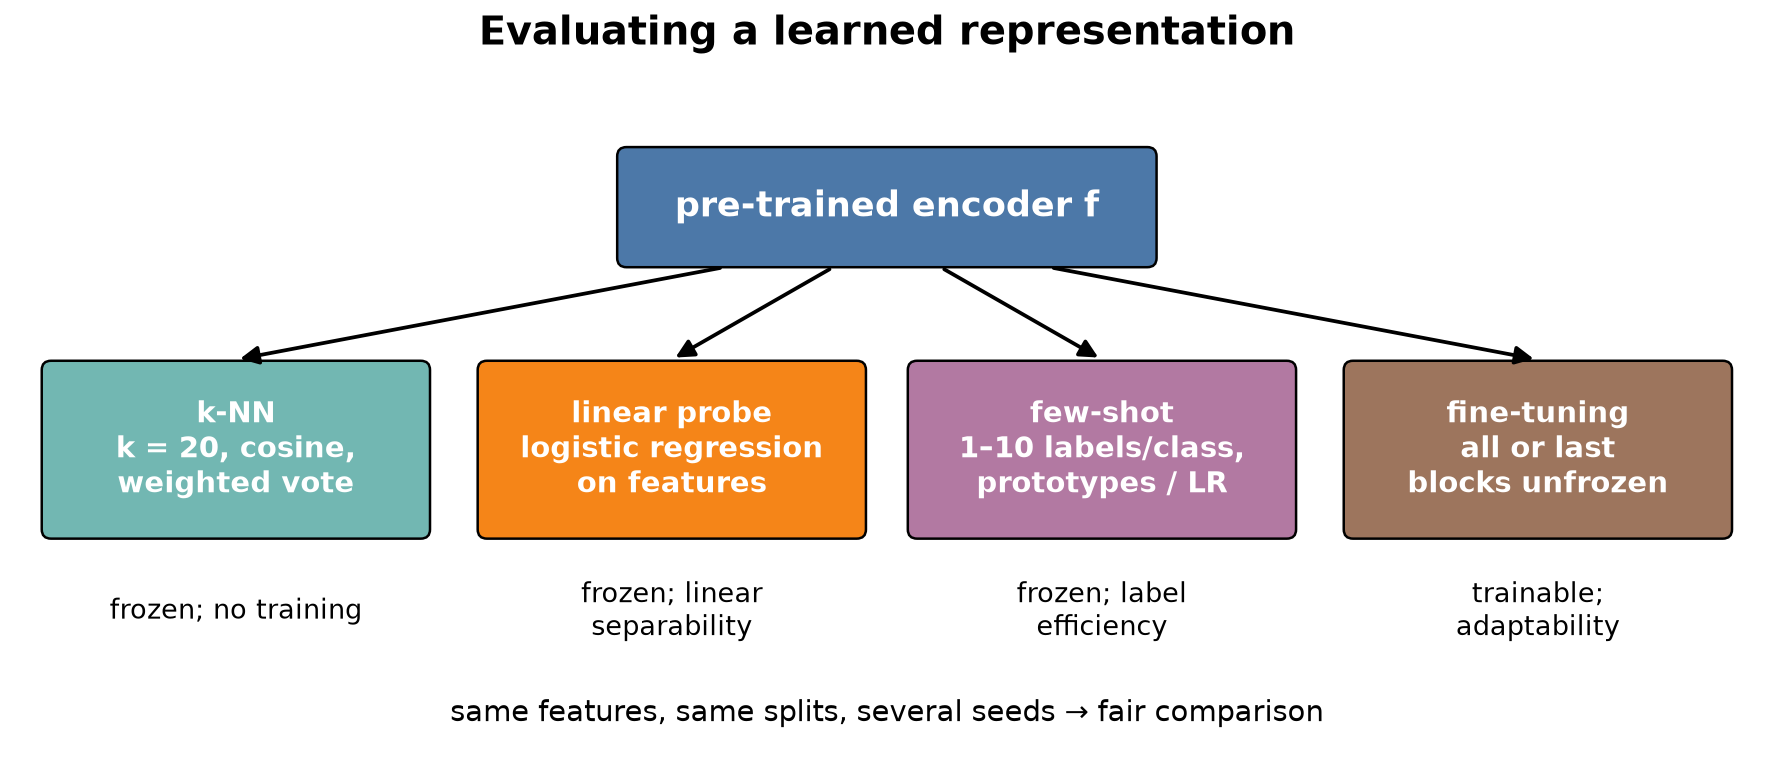

| Протокол | Что обучается | Что измеряет | Плюсы | Минусы |
|---|---|---|---|---|
| Weighted k-NN | ничего | локальную геометрию: похожи ли соседи по классу | нет гиперпараметров обучения, быстро | чувствителен к масштабу и «хабам» |
| Linear probe | один линейный слой | линейную разделимость классов | стандарт литературы | недооценивает нелинейно доступную информацию (MAE) |
| Few-shot | прототипы или регуляризованный LR на 1–10 примерах/класс | эффективность по разметке | ближе к реальной задаче курса | большой разброс, нужно много повторов |
| Partial / full fine-tuning | последние блоки или всё | адаптируемость | лучший абсолютный результат | дорого, много гиперпараметров, сложно сравнивать |
| Плотные задачи (сегментация, глубина) на замороженных патч-признаках | лёгкая голова | качество локальных признаков | важно для детекции и сегментации | нужен размеченный плотный набор |

### 5.2. Общие правила корректного сравнения

1. Энкодер заморожен (кроме fine-tuning). Признаки извлекаются один раз в режиме `eval()` и кешируются.
2. Предобработка соответствует модели: нормализация `mean/std` из конфигурации модели, разрешение, кратное размеру патча. Для ViT-S/14 это 224 = 16 × 14.
3. Зафиксирован тип признака: [CLS], среднее по патчам, их конкатенация или конкатенация [CLS] нескольких последних слоёв. В практикуме (раздел 13.1) у MAE сравниваются оба варианта.
4. Гиперпараметры (k, τ, C у логистической регрессии) подбираются на валидации, выделенной из обучающей части. Никогда не на test.
5. Одинаковые разбиения и одинаковые seed выбора размеченных примеров для всех моделей. Тогда сравнения парные, и разброс из-за выбора примеров частично сокращается.
6. Результаты приводятся как среднее ± стандартное отклонение по seed, с указанием числа seed и размера теста.
7. Разбиение по группам (лекция 1): снимки одного объекта, сцены или пациента не попадают одновременно в train и test. Иначе k-NN «находит» почти-дубликаты, и оценка завышается.
8. Проверяется пересечение с данными предобучения. Если тестовые изображения домена могли попасть в предобучающий корпус модели, результат оптимистичен. DINOv2 специально удалял почти-дубликаты тестовых наборов бенчмарков ([DINOv2](https://arxiv.org/abs/2304.07193)), но ваш домен никто не проверял.

### 5.3. Weighted k-NN

Протокол [DINO](https://arxiv.org/abs/2104.14294):

- признаки замороженной модели нормируются;
- для тестового $x$ находятся $k=20$ ближайших обучающих $T_i$ по косинусу;
- голоса взвешиваются:
$
\alpha_i=\exp\!\big(T_i^\top x/\tau\big),\quad\tau=0.07,\qquad
\hat y=\arg\max_c\sum_{i\in\mathcal N_k(x)}\alpha_i\,\mathbb 1[c_i=c].
$

Авторы отмечают, что $k=20$ стабильно лучше других значений, а $\tau$ не настраивалась. Протокол не требует аугментаций и выполняется за один проход по данным.

Почему взвешивание. При малом $\tau$ голос почти целиком отдаётся самым похожим соседям, при большом голосование становится обычным невзвешенным. Чего стоит ожидать (проверяется в разделе 13.2 практикума):

- при $\tau=0.07$ результат слабо зависит от $k$ в широком диапазоне: далёкие соседи получают малый вес;
- при $\tau=0.5$ далёкие соседи голосуют почти наравне, и с ростом $k$ точность падает;
- при $\tau=0.02$ голос почти полностью отдаётся ближайшему соседу, и результат застывает около 1-NN.

```python
def weighted_knn(Xtr, ytr, Xte, k=20, tau=0.07, n_classes=10):
    """Xtr, Xte — L2-нормированные признаки (numpy)."""
    S = Xte @ Xtr.T; k = min(k, len(ytr))
    idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
    w = np.exp(np.take_along_axis(S, idx, 1) / tau)
    votes = np.stack([(w * (ytr[idx] == c)).sum(1) for c in range(n_classes)], 1)
    return votes.argmax(1)
```

Проблема «хабов» (hubness). В пространствах высокой размерности некоторые точки оказываются ближайшими соседями непропорционально многих других и «перетягивают» голоса. Помогают $\ell_2$-нормировка, центрирование признаков (вычитание среднего по обучающей выборке перед нормировкой) и малое $\tau$.

### 5.4. Linear probing

Над замороженными признаками обучается линейный классификатор $\hat y=\arg\max(Wh+b)$ с кросс-энтропией.

Два варианта реализации:

- Литературный стандарт на ImageNet по [DINO](https://arxiv.org/abs/2104.14294): SGD, 100 эпох, батч 1024, без weight decay, с аугментациями (random resized crop и отражение), скорость обучения подбирается. Для ViT-S берётся конкатенация [CLS] последних 4 блоков (размерность 1536), для ViT-B — [CLS] последнего блока.
- Практический вариант для небольших наборов курса: признаки без аугментаций, логистическая регрессия (L-BFGS из scikit-learn) с подбором коэффициента регуляризации $C$ по сетке $\{10^{-3},\dots,10^{2}\}$ на валидации.

Тонкости:

- Нормировка: стандартизация признаков (`StandardScaler`) или $\ell_2$-нормировка. Без неё оптимизатор может долго сходиться, а сравнение моделей с разным масштабом признаков некорректно.
- При малом числе примеров на класс линейная модель переобучается, и регуляризация обязательна.
- Linear probe и k-NN измеряют разное. Если linear сильно лучше k-NN, классы разделимы, но кластеры «растянуты». Если они близки, признаки хорошо кластеризованы по классам.

### 5.5. Few-shot

Постановка «$n$-shot»: $n$ размеченных примеров на класс, $n\in\{1,2,5,10\}$.

Методы:

1. Прототипы (nearest class mean). Признак класса — среднее нормированных признаков его примеров, классификация по косинусу:
$
\mu_c=\frac1{n}\sum_{i:y_i=c}\bar h_i,\qquad\hat y=\arg\max_c\ \bar h^\top\bar\mu_c.
$
2. Логистическая регрессия с сильной регуляризацией.
3. k-NN с $k\le n$ (при $n=1$ это 1-NN, совпадающий с прототипами).

Главная особенность few-shot — огромный разброс из-за выбора примеров. Насколько велик разброс, видно в разделе 13.3 практикума по столбцу с диапазоном точности. В статьях few-shot результаты усредняют по сотням или тысячам эпизодов. Для курсовых работ — минимум 5, лучше 20 повторов, с доверительным интервалом.

```python
def prototypes(Xtr, ytr, Xte, n_classes):
    P = np.stack([Xtr[ytr == c].mean(0) for c in range(n_classes)])
    P /= np.linalg.norm(P, axis=1, keepdims=True)
    return (Xte @ P.T).argmax(1)
```

### 5.6. Кривые качества по объёму разметки

Кривая label efficiency строится так:

- по оси $x$ — число размеченных примеров на класс $n$ (логарифмическая шкала);
- по оси $y$ — качество на фиксированном тесте;
- для каждого $n$ — несколько seed выбора примеров.

Кривая отвечает на практические вопросы:

1. Сколько разметки нужно, чтобы достичь заданного качества, например 90% от максимума?
2. Где насыщение, после которого разметка почти не помогает?
3. Какой энкодер выгоднее при данном бюджете разметки? Кривые могут пересекаться.

Полезные скалярные сводки:

- $n_{90}$ — минимальное $n$, при котором достигается 90% от качества при полной разметке;
- площадь под кривой в логарифмических координатах (среднее качество по сетке $n$).

Статистика сравнения. Для $n_{\text{test}}$ тестовых изображений стандартная ошибка точности $\hat a$ равна $\sqrt{\hat a(1-\hat a)/n_{\text{test}}}$. При 1000 изображениях и $\hat a=0.95$ это около 0.7 п.п. Разница двух моделей меньше 1–2 п.п. на таком тесте статистически ненадёжна.

Для парного сравнения двух моделей на одном тесте используют:

- тест Мак-Немара по числу примеров, где ошибается только одна из моделей;
- bootstrap по тестовым изображениям (или по группам, если они есть) с 95% интервалом для разности точностей.

```python
def bootstrap_diff(correct_a, correct_b, n_boot=2000, seed=0):
    """correct_*: булевы массивы правильности по тестовым примерам (одни и те же примеры)."""
    r = np.random.default_rng(seed); n = len(correct_a); d = []
    for _ in range(n_boot):
        i = r.integers(0, n, n); d.append(correct_a[i].mean() - correct_b[i].mean())
    return np.mean(correct_a) - np.mean(correct_b), np.percentile(d, [2.5, 97.5])
```

## 6. Визуализация эмбеддингов

### 6.1. Зачем и с какими ожиданиями

Двумерная проекция признаков помогает:

- увидеть общую структуру данных;
- заметить смешение классов и выбросы;
- обнаружить кластеры, совпадающие не с классами, а с источником данных. Это главный инструмент поиска паразитных признаков (часть 7).

При этом проекция 384- или 768-мерного пространства на плоскость неизбежно искажает геометрию. Поэтому правило курса: проекция — иллюстрация и источник гипотез, а не измерение. Количественные выводы делаются по метрикам в исходном пространстве (k-NN, linear probe, метрики кластеризации).

### 6.2. PCA

Линейная проекция на две главные компоненты.

Плюсы:

- детерминирована;
- сохраняет глобальные расстояния вдоль главных направлений;
- быстра.

Минус: две компоненты из сотен объясняют малую долю дисперсии (спектр — в разделе 13.1 практикума), и классы перекрываются. PCA полезна как первый шаг: сокращение до 50 компонент перед t-SNE или UMAP ускоряет их и снижает шум.

### 6.3. t-SNE

t-SNE (van der Maaten, Hinton) строит в исходном пространстве распределение сходств с гауссовыми ядрами. Ширина $\sigma_i$ подбирается так, чтобы perplexity распределения $p_{\cdot|i}$ равнялась заданной, то есть $2^{H(p_{\cdot|i})}=\text{perplexity}$:

$
p_{j|i}=\frac{\exp(-\|x_i-x_j\|^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\|x_i-x_k\|^2/2\sigma_i^2)},\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}.
$

В двумерном пространстве используется распределение Стьюдента с одной степенью свободы:

$
q_{ij}=\frac{(1+\|y_i-y_j\|^2)^{-1}}{\sum_{k\ne l}(1+\|y_k-y_l\|^2)^{-1}},\qquad\min_{y}\ \mathrm{KL}(P\|Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$

Следствия формул:

- KL сильно штрафует случай, когда близкие в исходном пространстве точки (большое $p_{ij}$) оказались далеко на плоскости. Обратная ситуация штрафуется слабо. Поэтому t-SNE хорошо сохраняет локальные соседства и плохо — глобальные расстояния.
- Тяжёлые хвосты распределения Стьюдента «раздвигают» кластеры. Расстояния между кластерами на картинке не равны исходным.
- Perplexity — это примерно эффективное число соседей, которое учитывает каждая точка.

### 6.4. UMAP

[UMAP](https://arxiv.org/abs/1802.03426):

- строит взвешенный граф $k$ ближайших соседей, параметр `n_neighbors`;
- ищет двумерное вложение, сохраняющее этот граф: минимизирует кросс-энтропию между нечёткими множествами рёбер в исходном пространстве и в проекции.

По словам авторов, качество визуализации сопоставимо с t-SNE, глобальная структура сохраняется, вероятно, лучше, а работает UMAP быстрее.

Параметры:

- `n_neighbors` (по умолчанию 15) — баланс локального и глобального. Больше — более глобальная картина.
- `min_dist` (0.1) — насколько плотно упаковываются точки кластера.
- `metric` — для нормированных SSL-признаков `cosine`.
- `random_state` — для воспроизводимости. С фиксированным seed UMAP работает в однопоточном режиме, медленнее.

### 6.5. Как не обмануться: уроки Distill

По статье [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/):

1. Гиперпараметры важны. Типичный диапазон perplexity 5–50, и его нужно просматривать. Perplexity должна быть меньше числа точек.
2. Размеры кластеров ничего не значат. t-SNE расширяет плотные кластеры и сжимает разреженные. В примере статьи кластер, в 10 раз более разбросанный, выглядел того же размера.
3. Расстояния между кластерами могут ничего не значить. В примере с тремя кластерами, где одна пара в 5 раз дальше другой, при малой perplexity кластеры выглядели равноудалёнными.
4. Случайный шум может выглядеть кластерами. 500 точек из стандартного 100-мерного гауссова распределения при perplexity 2 дают выраженные сгустки (воспроизведение — раздел 14.2 практикума).
5. Иногда форму можно увидеть, только перебрав несколько perplexity. Топология тоже может искажаться: вложенные множества, узлы.
6. Нужно дождаться сходимости. В статье использовалось 5000 итераций. «Защемлённые» формы — признак ранней остановки. Разные запуски дают разные картинки.

### 6.6. Рецепт визуализации для отчёта

1. Нормировать признаки ($\ell_2$). При размерности больше 100 предварительно сократить PCA до 50 компонент.
2. Построить UMAP (`n_neighbors` 15 и 50) и t-SNE (perplexity 5, 30, 50), по 2 seed каждого.
3. Раскрасить одну и ту же проекцию:
   - по классу;
   - по каждому полю метаданных: источник, устройство, дата, разметчик, разрешение, наличие текста или рамки;
   - по ошибке модели (верно/неверно).
4. Посчитать trustworthiness и k-NN в исходном пространстве.
5. Подписывать выводы двух типов: «что видно» (структура, смешение классов, выделяющиеся группы) и «что нельзя утверждать» (размеры кластеров, расстояния между ними, плотность).

```python
import umap
from sklearn.manifold import TSNE, trustworthiness
from sklearn.decomposition import PCA

def project_all(X, seed=0):
    X50 = PCA(50, random_state=seed).fit_transform(X) if X.shape[1] > 100 else X
    E = {f"UMAP n={n}": umap.UMAP(n_neighbors=n, min_dist=0.1, metric="cosine", random_state=seed).fit_transform(X)
         for n in (15, 50)}
    E.update({f"t-SNE p={p}": TSNE(perplexity=p, init="pca", random_state=seed).fit_transform(X50) for p in (5, 30, 50)})
    T = {k: trustworthiness(X, v, n_neighbors=10, metric="cosine") for k, v in E.items()}
    return E, T
```

## 7. Паразитные признаки и shortcut learning

### 7.1. Определение

[Geirhos et al.](https://arxiv.org/abs/2004.07780) определяют shortcut как решающее правило, которое хорошо работает на стандартных бенчмарках, но не переносится на более сложные условия тестирования, например на реальные сценарии.

Паразитный (spurious) признак — свойство входа, которое в обучающих данных коррелирует с меткой, но не связано с ней причинно: фон, водяной знак, марка сканера, рамка. Shortcut возникает, когда модель предпочитает паразитный признак настоящему (core), потому что он проще: его легче извлечь при той же или большей точности на train.

Формально. Пусть данные разбиты на группы $g=(y,a)$, где $y$ — метка, $a$ — паразитный атрибут. Средняя точность может быть высокой, тогда как точность на «нетипичных» группах (где $a$ не совпадает с обычной для $y$ парой) низкая. Поэтому вводят точность на худшей группе:

$
\text{worst-group acc}=\min_{g}\ \frac{1}{|D_g|}\sum_{(x,y)\in D_g}\mathbb 1[\hat y(x)=y].
$

### 7.2. Классические примеры

Текстура вместо формы. CNN, обученные на ImageNet, сильно смещены к распознаванию текстур, в отличие от людей. Это проверено на изображениях с конфликтом формы и текстуры, например силуэт кошки с текстурой кожи слона. Обучение на Stylized-ImageNet сдвигает ResNet-50 к форме и повышает устойчивость к искажениям ([Geirhos et al., 2019](https://arxiv.org/abs/1811.12231)).

Waterbirds ([Sagawa et al.](https://arxiv.org/abs/1911.08731)):

- птицы из CUB вырезаны по маскам и наложены на фоны из Places (вода: океан, озеро; суша: бамбуковый и лиственный лес);
- в обучающей выборке 95% водоплавающих птиц — на воде, 95% сухопутных — на суше;
- всего 4795 обучающих примеров, в самой малой группе (водоплавающие на суше) 56;
- валидация и тест сбалансированы по группам.

Худшая группа при обычном обучении (ERM) и при group DRO ([Sagawa et al.](https://arxiv.org/abs/1911.08731), тест):

| Режим | ERM | Group DRO |
|---|---|---|
| Стандартная регуляризация | 60.0% | 76.9% |
| Сильный $\ell_2$ | 21.3% | 84.6% |
| Ранняя остановка | 6.7% | 86.0% |

Средняя точность при этом может оставаться высокой. Авторы подчёркивают, что регуляризация важна именно для худшей группы. Групповой DRO с усиленной регуляризацией даёт прирост worst-group accuracy на 10–40 п.п. В той же работе есть набор CelebA: цель — светлые волосы, паразитный атрибут — пол, худшая группа — светловолосые мужчины.

Медицина ([Zech et al., PLOS Medicine](https://journals.plos.org/plosmedicine/article?id=10.1371/journal.pmed.1002683)):

- CNN для пневмонии на рентгенограммах определяли больницу-источник с точностью 99.95% (NIH) и 99.98% (Mount Sinai);
- внутри Mount Sinai — отделение (стационар или приёмное) со 100% точностью;
- модель использовала маркеры стороны и металлическую метку на пациенте;
- распространённость пневмонии различалась по больницам, поэтому модель могла предсказывать болезнь косвенно, через «узнавание» больницы, и плохо переносилась на внешние данные.

Clever Hans. Методы объяснения показывают, что модели с высокими метриками иногда опираются на нерелевантные артефакты, а стандартные метрики этого не различают. Авторы предложили полуавтоматический анализ релевантностей (Spectral Relevance Analysis) для поиска таких стратегий ([Lapuschkin et al.](https://arxiv.org/abs/1902.10178)).

### 7.3. Shortcut-ы внутри самообучения

SSL особенно подвержен shortcut-ам: pretext-задачу можно решить любым способом, и модель выберет самый простой.

| Shortcut | Где | Чем устраняется |
|---|---|---|
| Стыки краёв, хроматическая аберрация | пазлы, предсказание положения патча | зазоры между патчами, цветовые искажения |
| Цветовая гистограмма | контрастное обучение с одними кропами | color jitter и grayscale: SimCLR crop-only — 40.3% против 67.9% с полным набором ([BYOL](https://arxiv.org/abs/2006.07733)) |
| Утечка через статистики BatchNorm | MoCo, контраст внутри батча | shuffling BN ([MoCo](https://arxiv.org/abs/1911.05722)) |
| Интерполяция соседних патчей | MIM с малой долей маски | 75% маскирования ([MAE](https://arxiv.org/abs/2111.06377)) |
| Высоконормные «черновые» токены в фоне | большие ViT | регистры ([Darcet et al.](https://arxiv.org/abs/2309.16588)) |
| Водяные знаки, рамки, текст, метаданные камеры | любые веб-данные и архивы | очистка данных, кропы, аудит |

Последняя строка важна для курсового проекта. SSL-энкодер запоминает всё, что помогает решить pretext-задачу и не уничтожено аугментациями. Если на половине снимков вашего домена есть метка времени в углу, она будет в эмбеддинге. Дальше любой классификатор, обученный на смещённой выборке, может ею воспользоваться.

### 7.4. Контролируемый эксперимент

В разделе 15 практикума на CIFAR-10 искусственно создаётся паразитная корреляция «красный квадрат в углу ↔ кошка» и сравниваются CNN с нуля, замороженный DINOv2 и способы борьбы из раздела 7.6. Там же — аудит инструментами раздела 7.5.

### 7.5. Как обнаружить паразитные признаки

1. Метаданные — в таблицу. Для каждого изображения хранить источник, устройство, дату, площадку, разметчика, разрешение и формат. Без метаданных искать shortcut-ы почти невозможно.
2. Probe на метаданные. Обучить linear probe предсказывать каждое поле метаданных по эмбеддингу. Высокая точность сама по себе не плоха: камеру часто можно узнать. Опасно сочетание двух условий:
   - атрибут хорошо предсказуем;
   - распределение классов по значениям атрибута неравномерно.

   Именно такая ситуация была с больницами у [Zech et al.](https://journals.plos.org/plosmedicine/article?id=10.1371/journal.pmed.1002683).
3. Таблица сопряжённости «класс × атрибут» на train. Сильно неравномерные строки — кандидаты на shortcut.
4. Метрики по группам. Средняя точность, точность каждой группы и worst-group accuracy на тесте, сбалансированном по группам.
5. Контрфактические тесты:
   - закрасить или вырезать подозрительную область (угол, текст, рамку);
   - заменить фон;
   - перевернуть корреляцию, как в разделе 15 практикума.

   Резкое изменение предсказаний — улика.
6. Внешний тест: данные из другого источника, другой камеры, другого периода.
7. Карты атрибуции (Grad-CAM, attention rollout, LRP) — как подсказка, где искать, но не как доказательство.
8. Проекции UMAP, окрашенные по метаданным. Если кластеры совпадают с источником, а не с классом, это тревожный сигнал. Отсутствие такой картины не доказывает отсутствие проблемы (раздел 15.3 практикума).

### 7.6. Как бороться

| Подход | Нужны метки групп | Идея |
|---|---|---|
| Очистка данных | нет | удалить артефакт: обрезать рамку, замазать текст, привести форматы к одному |
| Аугментации против артефакта | нет | случайно добавлять или удалять артефакт, рандомизировать фон и цвет |
| Балансировка и переразвешивание групп | да | выравнять вклад редких групп |
| Group DRO ([Sagawa et al.](https://arxiv.org/abs/1911.08731)) | да | минимизировать потерю на худшей группе + сильная регуляризация |
| JTT ([Liu et al.](https://arxiv.org/abs/2107.09044)) | только на валидации | сначала обычная модель на несколько эпох, затем вторая модель с повышенным весом примеров, на которых ошиблась первая |
| Переобучение последнего слоя ([Kirichenko et al.](https://arxiv.org/abs/2204.02937)) | на малой сбалансированной выборке | признаки уже содержат core-информацию, достаточно переобучить линейную голову |
| Замороженный сильный SSL-энкодер + linear probe | нет | меньше возможностей переучить признаки под артефакт (раздел 15 практикума) |

По [JTT](https://arxiv.org/abs/2107.09044): в среднем на четырёх задачах из компьютерного зрения и NLP метод закрывает 75% разрыва в worst-group accuracy между обычным обучением и group DRO. При этом метки групп нужны только на небольшой валидации для подбора гиперпараметров.

```python
def group_report(y_true, y_pred, attr):
    """Точность по группам (класс, атрибут) и худшая группа."""
    rep = {}
    for c in np.unique(y_true):
        for a in np.unique(attr):
            m = (y_true == c) & (attr == a)
            if m.sum(): rep[(int(c), int(a))] = (float((y_pred[m] == c).mean()), int(m.sum()))
    worst = min(v[0] for v in rep.values())
    return rep, worst

def metadata_probe(X, meta, seed=0):
    """Насколько поле метаданных предсказуемо по эмбеддингу (кросс-валидация)."""
    from sklearn.model_selection import cross_val_score
    return cross_val_score(LogisticRegression(max_iter=3000), X, meta, cv=5).mean()
```

## 8. Практические рецепты

### 8.1. Какой энкодер брать в курсовом проекте

| Ситуация | Рекомендация | Почему |
|---|---|---|
| Классификация или поиск похожих, мало разметки, данные похожи на фотографии | DINOv2 ViT-S/14 или ViT-B/14, замороженный; k-NN или linear probe | сильные признаки «как есть» (часть 5, практикум, раздел 13) |
| Плотные задачи на замороженных признаках (сегментация, глубина) | DINOv2 с регистрами, патч-токены + лёгкая голова | гладкие карты признаков ([Darcet et al.](https://arxiv.org/abs/2309.16588)) |
| Есть GPU и время на дообучение, домен далёк от фотографий | MAE или DINOv2 + partial fine-tuning последних блоков | MAE раскрывается при дообучении ([MAE](https://arxiv.org/abs/2111.06377)) |
| Очень специфичный домен (микроскопия, тепловизор, рентген), много неразмеченных данных | продолжить SSL-предобучение на своих данных (DINO, BYOL или MAE), начиная с публичных весов | адаптация распределения |
| Нужна устойчивость к паразитным признакам | замороженный энкодер + аудит (часть 7) + переобучение головы на сбалансированной выборке | раздел 7.6, практикум, раздел 15 |

### 8.2. Мини-SSL своими руками

Рабочие реализации SimCLR, MoCo v2, BYOL, DINO и MAE на маленьких сетях — в разделе 11 практикума. Для своего домена на GPU тот же код масштабируется заменой `SmallCNN` на ResNet-18 из `torchvision` и увеличением разрешения до 96–128.

Что логировать при обучении:

- потерю;
- $\mathcal L_{\text{align}}$ и $\mathcal L_{\text{uniform}}$ на фиксированной валидационной пачке;
- эффективный ранг и std нормированных проекций;
- k-NN-точность на малой размеченной валидации раз в несколько эпох.

Рост k-NN и стабильный эффективный ранг означают, что обучение идёт нормально. Падение std к нулю и эффективного ранга к единицам — коллапс.

### 8.3. Частые ошибки

1. Оценка по признаку после проекционной головы, а не до неё.
2. Признаки извлекаются в режиме `train()`: BatchNorm и dropout меняют результат.
3. Неверная нормализация входа (чужие `mean/std`) или разрешение, не кратное патчу ViT.
4. Подбор k, τ, C по тестовой выборке.
5. Один seed в few-shot.
6. Утечка между train и test через почти-дубликаты или кадры одного видео.
7. Выводы о расстояниях между кластерами по t-SNE.
8. Сравнение методов в разных протоколах: linear у одного, fine-tuning у другого.
9. Аугментации, уничтожающие нужную для задачи информацию (цвет, ориентацию).
10. Отсутствие метаданных и аудита паразитных признаков.

# Часть II. Практикум

## 9. Подготовка

Флаг `FAST_DEV_RUN = True` включает сокращённый режим для CPU: меньше шагов предобучения и меньше изображений в оценке. В Colab с GPU поставьте `False`: предобучение станет в 10 раз длиннее, оценка пойдёт на больших выборках. Признаки предобученных моделей кэшируются в папке `ssl_l4_cache`, поэтому повторный запуск ячеек их не пересчитывает.

In [1]:
FAST_DEV_RUN = True

import os, sys, io, time, math, copy, random, subprocess, warnings
warnings.filterwarnings("ignore")
for pkg, mod in (("umap-learn", "umap"), ("timm", "timm")):
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download
import timm, umap, sklearn, transformers
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize, StandardScaler
from sklearn.manifold import TSNE, trustworthiness
from sklearn.decomposition import PCA

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
T0 = time.time()
def seed_all(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(0)
plt.rcParams.update({"font.size": 13, "axes.titlesize": 14, "figure.dpi": 100})
ART = Path("ssl_l4_cache"); ART.mkdir(exist_ok=True)

S = dict(
    n_pool=10000 if FAST_DEV_RUN else 50000,     # неразмеченные изображения для мини-предобучения (раздел 11)
    ssl_steps=300 if FAST_DEV_RUN else 3000,     # шагов предобучения на метод
    ssl_bs=256 if FAST_DEV_RUN else 512,
    width=16 if FAST_DEV_RUN else 32,            # ширина маленькой CNN
    n_eval_test=2000 if FAST_DEV_RUN else 10000, # тест для мини-моделей
    per_class_tr=150 if FAST_DEV_RUN else 500,   # размеченный train для предобученных энкодеров (раздел 12)
    per_class_te=100 if FAST_DEV_RUN else 300,
    shortcut_tr=300 if FAST_DEV_RUN else 1000,   # раздел 15: изображений на класс
    shortcut_te=200 if FAST_DEV_RUN else 500,
    seeds=5,
)
print(f"device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}, torch {torch.__version__}, timm {timm.__version__}, "
      f"transformers {transformers.__version__}, sklearn {sklearn.__version__}, потоков CPU: {torch.get_num_threads()}")
print(S)

device=cpu, FAST_DEV_RUN=True, torch 2.14.1+cpu, timm 1.0.30, transformers 5.19.0, sklearn 1.9.1, потоков CPU: 2
{'n_pool': 10000, 'ssl_steps': 300, 'ssl_bs': 256, 'width': 16, 'n_eval_test': 2000, 'per_class_tr': 150, 'per_class_te': 100, 'shortcut_tr': 300, 'shortcut_te': 200, 'seeds': 5}


Данные — CIFAR-10 ([Krizhevsky, 2009](https://www.cs.toronto.edu/~kriz/cifar.html)): 60 000 цветных изображений 32×32 в 10 классах. Берём parquet-версию с Hugging Face Hub ([uoft-cs/cifar10](https://huggingface.co/datasets/uoft-cs/cifar10)).

Роли подвыборок:

- **пул без меток** (`n_pool` изображений из train) — для мини-предобучения в разделе 11, метки при этом не используются;
- **размеченный train** — те же изображения, но теперь с метками, для k-NN и linear probe;
- **тест** — первые `n_eval_test` изображений test-части.

Изображения храним одним тензором `uint8`: 10 000 картинок 32×32 занимают 30 МБ.

пул: (10000, 32, 32, 3), тест: (2000, 32, 32, 3), классы в пуле: [1033 1013  996  974  956  989 1044 1003  977 1015]; загрузка 2 с


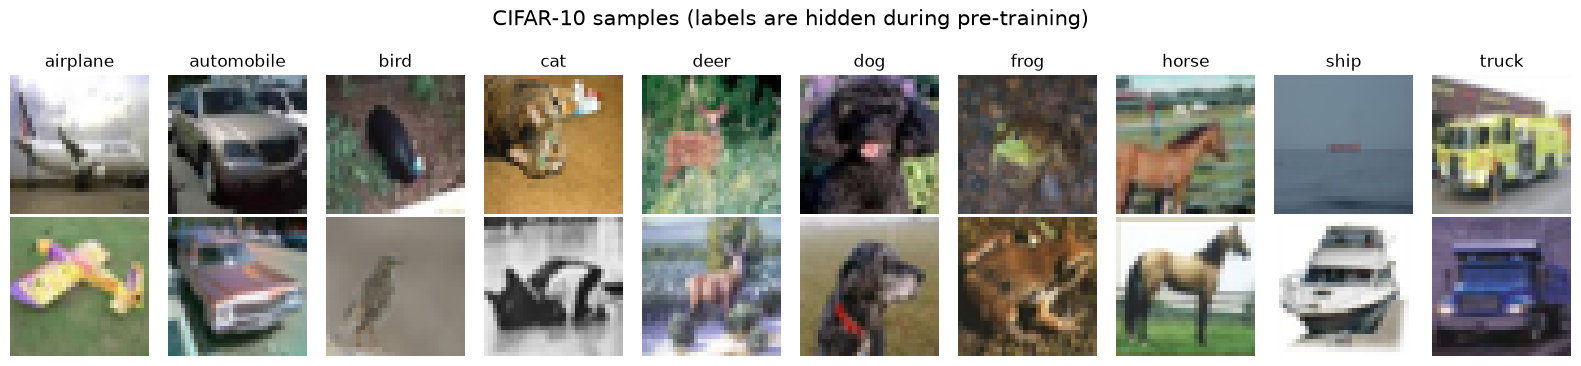

In [2]:
def load_parquet(repo, f):
    return pq.read_table(hf_hub_download(repo, f, repo_type="dataset")).to_pandas()

def decode(col):
    return np.stack([np.asarray(Image.open(io.BytesIO(b["bytes"])).convert("RGB")) for b in col])

t = time.time()
tr = load_parquet("uoft-cs/cifar10", "plain_text/train-00000-of-00001.parquet")
te = load_parquet("uoft-cs/cifar10", "plain_text/test-00000-of-00001.parquet")
rng = np.random.RandomState(0)
pool_idx = rng.permutation(len(tr))[:S["n_pool"]]
X_POOL = decode(tr.img.values[pool_idx]); Y_POOL = tr.label.values[pool_idx]
X_TEST = decode(te.img.values[:S["n_eval_test"]]); Y_TEST = te.label.values[:S["n_eval_test"]]
TR_ALL, TE_ALL = tr, te   # полные таблицы нужны в разделах 12 и 15
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print(f"пул: {X_POOL.shape}, тест: {X_TEST.shape}, классы в пуле: {np.bincount(Y_POOL)}; загрузка {time.time()-t:.0f} с")

fig, ax = plt.subplots(2, 10, figsize=(16, 3.8))
for c in range(10):
    for r in range(2):
        ax[r, c].imshow(X_POOL[np.where(Y_POOL == c)[0][r]]); ax[r, c].axis("off")
    ax[0, c].set_title(CLASSES[c], fontsize=12)
plt.suptitle("CIFAR-10 samples (labels are hidden during pre-training)", fontsize=15); plt.tight_layout(); plt.show()

Аугментации — сердце joint-embedding-методов (раздел 1.4). Стандартные `torchvision.transforms` обрабатывают по одному изображению на CPU, и на маленьких картинках это узкое место. Поэтому ниже аугментации реализованы сразу на батче тензоров: у каждого изображения свои случайные параметры, а работает всё и на GPU.

- **Random resized crop с отражением** — через аффинную сетку `F.affine_grid` и `F.grid_sample`: доля площади $s\sim U(0.2, 1)$, соотношение сторон от 3/4 до 4/3. Нижняя граница 0.2 вместо 0.08 у SimCLR — обычная поправка для изображений 32×32.
- **Color jitter** с вероятностью 0.8: яркость, контраст и насыщенность умножаются на случайные множители из $[0.6, 1.4]$.
- **Перевод в оттенки серого** с вероятностью 0.2.

Гауссово размытие для CIFAR-10 обычно отключают: на 32×32 оно уничтожает слишком много деталей.

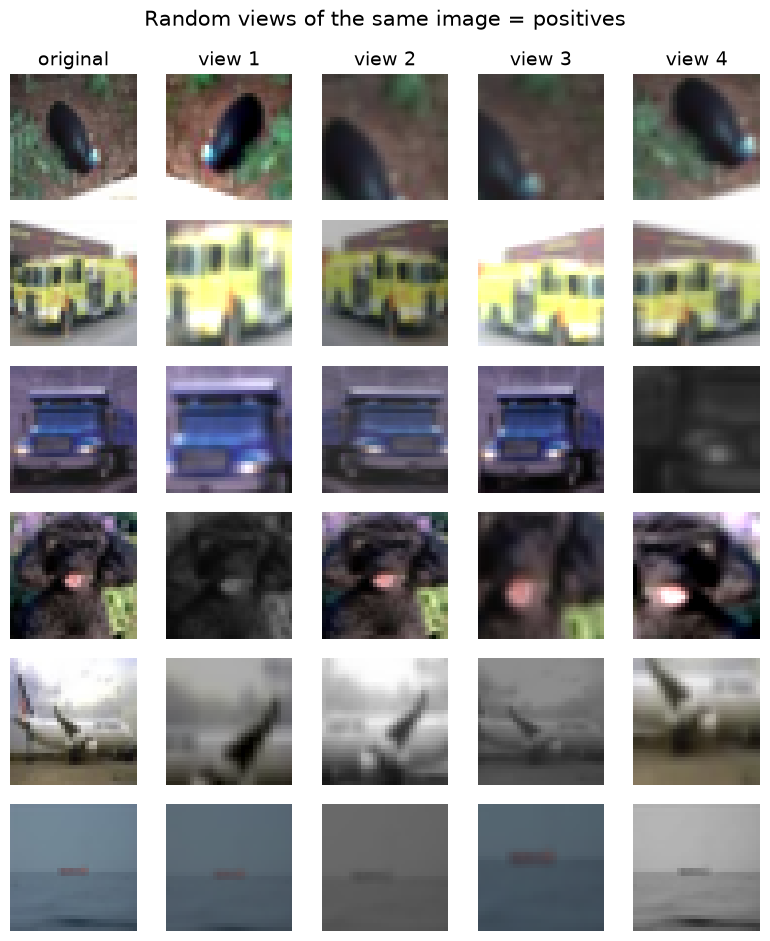

In [3]:
MEAN = torch.tensor([0.491, 0.482, 0.447]).view(1, 3, 1, 1)
STD = torch.tensor([0.247, 0.243, 0.261]).view(1, 3, 1, 1)
LUMA = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)

def to_tensor(X_uint8):
    return torch.tensor(X_uint8).permute(0, 3, 1, 2).float() / 255

def norm(x):
    return (x - MEAN.to(x.device)) / STD.to(x.device)

def augment(x, scale=(0.2, 1.0), out=None, jitter=0.4, p_jitter=0.8, p_gray=0.2):
    """x: батч в [0,1], форма (B,3,H,W). Возвращает нормированный батч другого вида того же изображения."""
    B, dev = x.shape[0], x.device
    s = torch.empty(B, device=dev).uniform_(*scale)
    r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(3 / 4), math.log(4 / 3)))
    w, h = torch.sqrt(s * r).clamp(max=1), torch.sqrt(s / r).clamp(max=1)
    cx, cy = (torch.rand(B, device=dev) * 2 - 1) * (1 - w), (torch.rand(B, device=dev) * 2 - 1) * (1 - h)
    flip = torch.where(torch.rand(B, device=dev) < 0.5, -1.0, 1.0)
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0], theta[:, 0, 2], theta[:, 1, 1], theta[:, 1, 2] = w * flip, cx, h, cy
    size = (B, 3, out or x.shape[2], out or x.shape[3])
    x = F.grid_sample(x, F.affine_grid(theta, size, align_corners=False), align_corners=False, padding_mode="reflection")
    u = lambda: 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * jitter
    xj = x * u()
    mu = xj.mean((1, 2, 3), keepdim=True); xj = (xj - mu) * u() + mu
    g = (xj * LUMA.to(dev)).sum(1, keepdim=True); xj = (xj - g) * u() + g
    m = (torch.rand(B, 1, 1, 1, device=dev) < p_jitter).float()
    x = (m * xj + (1 - m) * x).clamp(0, 1)
    gm = (torch.rand(B, 1, 1, 1, device=dev) < p_gray).float()
    x = gm * (x * LUMA.to(dev)).sum(1, keepdim=True).expand_as(x) + (1 - gm) * x
    return norm(x)

XP = to_tensor(X_POOL)
seed_all(1)
x8 = XP[:6]
views = [augment(x8) for _ in range(4)]
show = lambda v: (v * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()
fig, ax = plt.subplots(6, 5, figsize=(8, 9.6))
for i in range(6):
    ax[i, 0].imshow(X_POOL[i])
    for j in range(4):
        ax[i, j + 1].imshow(show(views[j])[i])
for a in ax.flat: a.axis("off")
ax[0, 0].set_title("original"); [ax[0, j + 1].set_title(f"view {j+1}") for j in range(4)]
plt.suptitle("Random views of the same image = positives", fontsize=15); plt.tight_layout(); plt.show()

## 10. Функции потерь и мониторы коллапса своими руками

### 10.1. NT-Xent: две записи одной формулы

В разделе 2.2 потеря SimCLR записана для одной пары $(i, j)$:

$
\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.
$

На практике её считают одной матрицей: склеивают $2N$ векторов, вычисляют матрицу сходств $2N\times 2N$, закрывают диагональ и применяют кросс-энтропию, где «правильный класс» строки $i$ — номер её пары. Ниже обе записи сравниваются численно. Заодно проверим две опорные точки:

- при случайных эмбеддингах и большой температуре потеря близка к $\log(2N-1)$: позитив неотличим от $2N-2$ негативов;
- при идеальном совпадении видов и ортогональных эмбеддингах разных изображений сходство позитива 1, негативов 0, и потеря равна $\log\bigl(1+(2N-2)e^{-1/\tau}\bigr)$: при $\tau=1$ это 3.86, при $\tau=0.05$ почти ноль.

In [4]:
def nt_xent(z1, z2, tau=0.2):
    """SimCLR: 2N видов, у каждого 1 позитив и 2N-2 негатива."""
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    n = z1.shape[0]
    sim = z @ z.T / tau
    sim = sim.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), float("-inf"))
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(n)]).to(z.device)
    return F.cross_entropy(sim, target)

def nt_xent_loop(z1, z2, tau=0.2):
    """Та же потеря по формуле для каждой пары, медленно и наглядно."""
    z = F.normalize(torch.cat([z1, z2]), dim=1); n = z1.shape[0]; total = 0.0
    for i in range(2 * n):
        j = (i + n) % (2 * n)
        den = sum(torch.exp(z[i] @ z[k] / tau) for k in range(2 * n) if k != i)
        total += -torch.log(torch.exp(z[i] @ z[j] / tau) / den)
    return total / (2 * n)

seed_all(0)
N, d = 64, 32
z1, z2 = torch.randn(N, d), torch.randn(N, d)
print(f"случайные, tau=0.2: матрично {nt_xent(z1, z2):.4f}, по формуле {nt_xent_loop(z1, z2):.4f}")
print(f"случайные, tau=1.0: {nt_xent(z1, z2, 1.0):.4f};  log(2N-1) = {math.log(2*N-1):.4f}")
e = torch.eye(N)      # N ортогональных векторов, второй вид совпадает с первым
for tau in (1.0, 0.2, 0.05):
    print(f"идеальные виды, tau={tau}: {nt_xent(e, e, tau):.4f}")

случайные, tau=0.2: матрично 5.1175, по формуле 5.1175
случайные, tau=1.0: 4.8380;  log(2N-1) = 4.8442
идеальные виды, tau=1.0: 3.8576
идеальные виды, tau=0.2: 0.6146
идеальные виды, tau=0.05: 0.0000


**Что видно.** Матричная и поэлементная записи совпали до четвёртого знака: 5.1175 при $\tau=0.2$. При случайных эмбеддингах и $\tau=1$ потеря 4.838, почти ровно $\log(2N-1)=\log 127=4.844$: позитив неотличим от негативов. Для идеальных видов формула $\log\bigl(1+(2N-2)e^{-1/\tau}\bigr)$ подтверждается: 3.858 при $\tau=1$, 0.615 при $\tau=0.2$ и 0.000 при $\tau=0.05$. Значит, при большой температуре потеря не может опуститься низко даже на идеальном представлении. Её абсолютное значение без указания $\tau$ и $N$ ничего не говорит.

### 10.2. Температура и трудные негативы

По разделу 2.3 градиент потери по сходству с негативом $k$ равен $p_k/\tau$, где $p_k$ — softmax-вес этого негатива. Проверим это автоградиентом, а затем посмотрим, какая доля всего «веса» градиента приходится на самые похожие негативы при разных $\tau$. Сходства 4095 негативов сгенерированы из $\mathcal N(0.1,\,0.25^2)$, как на рис. 10.

In [5]:
seed_all(0)
s = torch.empty(4096).normal_(0.1, 0.25).clamp(-1, 1); s[0] = 0.8   # s[0] — позитив
s.requires_grad_(True)
tau = 0.1
loss = -torch.log_softmax(s / tau, 0)[0]; loss.backward()
p = torch.softmax(s.detach() / tau, 0)
print(f"max |grad - p/tau| по негативам: {(s.grad[1:] - p[1:] / tau).abs().max():.2e}; grad по позитиву {s.grad[0]:.3f} = (p_0 - 1)/tau = {(p[0]-1)/tau:.3f}")

neg = s.detach()[1:].sort(descending=True).values
rows = []
for tau in (0.05, 0.1, 0.2, 0.5, 1.0):
    w = torch.softmax(neg / tau, 0)
    rows.append({"tau": tau, "top-1 share": w[0].item(), "top-10 share": w[:10].sum().item(), "top-100 share": w[:100].sum().item(),
                 "effective negatives": (1 / (w ** 2).sum()).item()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

max |grad - p/tau| по негативам: 5.96e-08; grad по позитиву -9.903 = (p_0 - 1)/tau = -9.903
 tau  top-1 share  top-10 share  top-100 share  effective negatives
0.05        0.207         0.918          0.996                6.758
0.10        0.072         0.429          0.759               39.821
0.20        0.010         0.074          0.264              733.586
0.50        0.001         0.012          0.074             3154.221
1.00        0.001         0.005          0.044             3844.537


**Что видно.** Автоградиент совпал с формулой $p_k/\tau$ с точностью $6\cdot10^{-8}$, а градиент по позитиву равен $(p_0-1)/\tau$. Температура решает, кто получает градиент. При $\tau=0.05$ десять самых похожих негативов из 4095 забирают 92% веса, эффективное число негативов $1/\sum w_k^2$ около 7. При $\tau=0.2$ на первую десятку приходится 7%, эффективных негативов около 730. При $\tau=1$ их 3845, то есть почти все. Малая $\tau$ фокусирует обучение на трудных негативах, но делает его чувствительным к ложным негативам — другим изображениям того же класса.

### 10.3. Мониторы коллапса

Раздел 3.1 вводит три числа, которые стоит логировать при любом SSL-обучении:

- **std нормированных эмбеддингов** по каждой координате, усреднённое: у здорового представления близко к $1/\sqrt d$ ([SimSiam](https://arxiv.org/abs/2011.10566)), при полном коллапсе равно 0;
- **эффективный ранг** ([Roy, Vetterli, 2007](https://infoscience.epfl.ch/record/110188)) — экспонента энтропии нормированного спектра сингулярных чисел матрицы нормированных эмбеддингов, от 1 до $d$. Без центрирования это метрика RankMe ([Garrido et al., 2023](https://arxiv.org/abs/2210.02885)); если матрицу центрировать, у полного коллапса останется спектр шума, и ранг окажется обманчиво высоким;
- **uniformity** ([Wang, Isola, 2020](https://arxiv.org/abs/2005.10242)) — $\log\mathbb E\,e^{-2\|z_i-z_j\|^2}$, чем меньше, тем равномернее точки на сфере.

Проверим их на трёх искусственных облаках, как на рис. 11: здоровое, полный коллапс, размерностный коллапс в плоскость.

In [6]:
@torch.no_grad()
def collapse_stats(z):
    z = F.normalize(z.float(), dim=1)
    sv = torch.linalg.svdvals(z)
    p = sv / sv.sum(); erank = torch.exp(-(p * torch.log(p + 1e-12)).sum()).item()
    sq = torch.pdist(z[:2000]).pow(2)
    return {"std": z.std(0).mean().item(), "1/sqrt(d)": 1 / math.sqrt(z.shape[1]), "erank": erank,
            "uniformity": torch.log(torch.exp(-2 * sq).mean()).item()}

def alignment(z1, z2):
    return (F.normalize(z1, dim=1) - F.normalize(z2, dim=1)).norm(dim=1).pow(2).mean().item()

seed_all(0)
d = 128
clouds = {"healthy": torch.randn(1000, d),
          "complete collapse": torch.ones(1000, d) + 1e-4 * torch.randn(1000, d),
          "dimensional collapse (rank 2)": torch.randn(1000, 2) @ torch.randn(2, d)}
print(pd.DataFrame({k: collapse_stats(v) for k, v in clouds.items()}).T.round(3).to_string())

                                 std  1/sqrt(d)    erank  uniformity
healthy                        0.088      0.088  125.851      -3.938
complete collapse              0.000      0.088    1.014       0.000
dimensional collapse (rank 2)  0.078      0.088    1.998      -1.568


**Что видно.** Здоровое облако даёт std 0.088, ровно $1/\sqrt{128}$, эффективный ранг 126 из 128 и uniformity −3.94. При полном коллапсе все три числа вырождаются: std 0, ранг 1.01, uniformity 0. Размерностный коллапс в плоскость std почти не замечает: 0.078 против 0.088. Эффективный ранг выдаёт его сразу — 2.0. Поэтому std ловит только полный коллапс, а для размерностного нужен спектр.

### 10.4. Центрирование и заострение в DINO

В DINO учитель выдаёт распределение $P_t=\mathrm{softmax}((g(x)-c)/\tau_t)$. По [статье DINO](https://arxiv.org/abs/2104.14294) две операции работают в противоположные стороны:

- центрирование мешает одной координате доминировать, но толкает к равномерному распределению;
- заострение (малая $\tau_t$) делает распределения острыми, но в одиночку ведёт к доминированию одной координаты.

Модель ниже — игрушечная: выходы «учителя» — случайные логиты плюс общий для всех изображений сдвиг в одну координату. Именно такое смещение и разгоняется до коллапса, если его не гасить. Для каждой комбинации считаем две энтропии:

- $H(\bar P)$ — энтропия среднего по батчу распределения: если она мала, все изображения отправлены в одну координату;
- $\mathbb E H(P)$ — средняя энтропия одного распределения: если она близка к $\log K$, выходы равномерны и не несут информации.

Здоровая комбинация — высокая $H(\bar P)$ и низкая $\mathbb E H(P)$.

In [7]:
seed_all(0)
K, B = 256, 512
logits = torch.randn(B, K) * 0.5
logits[:, 7] += 3.0          # общий для всех изображений сдвиг — зародыш коллапса
center = logits.mean(0)      # в DINO это EMA средних выходов учителя
rows = []
for c_on in (False, True):
    for tau_t in (0.04, 1.0):
        P = torch.softmax((logits - (center if c_on else 0)) / tau_t, 1)
        Pm = P.mean(0)
        rows.append({"centering": c_on, "tau_t": tau_t,
                     "H(mean P)": -(Pm * Pm.log()).sum().item(),
                     "mean H(P)": -(P * (P + 1e-12).log()).sum(1).mean().item(),
                     "share of argmax = 7": (P.argmax(1) == 7).float().mean().item()})
print(f"log K = {math.log(K):.3f}")
print(pd.DataFrame(rows).round(3).to_string(index=False))

log K = 5.545
 centering  tau_t  H(mean P)  mean H(P)  share of argmax = 7
     False   0.04      0.001      0.000                1.000
     False   1.00      5.405      5.281                1.000
      True   0.04      5.356      0.444                0.004
      True   1.00      5.545      5.421                0.004


**Что видно.** Без центрирования и с острым учителем ($\tau_t=0.04$) все 512 изображений отправлены в координату 7: $H(\bar P)=0.001$ — это коллапс в одну координату. Только центрирование при $\tau_t=1$ даёт противоположный коллапс: $H(\bar P)=5.545=\log K$, $\mathbb E H(P)=5.42$, то есть каждый выход почти равномерен. Здоровая комбинация — центрирование плюс заострение: координаты используются равномерно ($H(\bar P)=5.36$), а отдельное распределение острое ($\mathbb E H(P)=0.44$), и доля координаты 7 падает до 0.004.

## 11. Мини-предобучение с нуля: SimCLR, MoCo, BYOL, DINO, MAE

Обучим семь вариантов одного маленького энкодера на 10 000 неразмеченных изображениях CIFAR-10 при одинаковом бюджете шагов. Два варианта — специально сломанные, чтобы увидеть коллапс. Это учебный масштаб: настоящие методы обучаются сотни эпох на миллионах изображений, у нас — около восьми эпох на CPU. Поэтому абсолютные числа низкие, а сравнивать стоит знаки и порядок эффектов.

Общая часть:

- энкодер `SmallCNN`: четыре свёрточных блока `Conv–BN–ReLU` с пулингом, ширина 16, выход $h\in\mathbb R^{128}$, около 100 тыс. параметров;
- оптимизатор AdamW, косинусное расписание скорости обучения с разогревом на 10% шагов;
- каждые 25 шагов логируются потеря и мониторы коллапса из раздела 10.3: std нормированной проекции $z$ и эффективный ранг признаков $h$ на фиксированной тысяче изображений;
- оценка — weighted k-NN и linear probe по признакам $h$ (раздел 5), метки появляются только здесь.

In [8]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class SmallCNN(nn.Module):
    def __init__(self, w=16):
        super().__init__()
        self.net = nn.Sequential(block(3, w), nn.MaxPool2d(2), block(w, 2 * w), nn.MaxPool2d(2),
                                 block(2 * w, 4 * w), nn.MaxPool2d(2), block(4 * w, 8 * w),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.dim = 8 * w
    def forward(self, x):
        return self.net(x)

def mlp(i, h, o):
    return nn.Sequential(nn.Linear(i, h), nn.BatchNorm1d(h), nn.ReLU(inplace=True), nn.Linear(h, o))

@torch.no_grad()
def ema_update(target, online, m):
    for pt, po in zip(target.parameters(), online.parameters()):
        pt.mul_(m).add_(po.detach(), alpha=1 - m)
    for bt, bo in zip(target.buffers(), online.buffers()):
        bt.copy_(bo)

def cosine_m(step, total, base=0.99):
    """Коэффициент EMA растёт от base к 1 по косинусу, как в BYOL и DINO."""
    return 1 - (1 - base) * (math.cos(math.pi * step / total) + 1) / 2

XT = to_tensor(X_TEST)
X_MON = norm(XP[:1000]).to(DEVICE)   # фиксированные чистые изображения для монитора

@torch.no_grad()
def embed(enc, X, bs=500):
    is_mod = isinstance(enc, nn.Module)
    if is_mod: enc.eval()
    out = [enc(norm(X[i:i + bs]).to(DEVICE)).float().cpu() for i in range(0, len(X), bs)]
    if is_mod: enc.train()
    return torch.cat(out)

def knn_eval(ftr, ytr, fte, yte, k=20, T=0.07, n_cls=10):
    """Weighted k-NN по косинусу с весами exp(s/T), как в протоколе DINO."""
    ftr, fte = F.normalize(torch.as_tensor(ftr).float(), dim=1), F.normalize(torch.as_tensor(fte).float(), dim=1)
    ytr = torch.as_tensor(ytr).long(); correct = 0
    for i in range(0, len(fte), 1000):
        sim, idx = (fte[i:i + 1000] @ ftr.T).topk(k, dim=1)
        votes = torch.zeros(len(sim), n_cls).scatter_add_(1, ytr[idx], torch.exp(sim / T))
        correct += (votes.argmax(1).numpy() == np.asarray(yte)[i:i + 1000]).sum()
    return correct / len(fte)

def linear_probe(ftr, ytr, fte, yte, C=1.0):
    sc = StandardScaler().fit(ftr)
    clf = LogisticRegression(max_iter=2000, C=C).fit(sc.transform(ftr), ytr)
    return clf.score(sc.transform(fte), yte)

def evaluate(enc, project=None):
    ftr, fte = embed(enc, XP).numpy(), embed(enc, XT).numpy()
    r = {"kNN": knn_eval(ftr, Y_POOL, fte, Y_TEST), "linear": linear_probe(ftr, Y_POOL, fte, Y_TEST),
         **{f"h_{k}": v for k, v in collapse_stats(torch.tensor(fte)).items() if k in ("std", "erank")}}
    if project is not None:   # k-NN в пространстве, где считается SSL-потеря (выход головы)
        enc.eval(); ztr, zte = embed(project, XP), embed(project, XT)
        r.update({"z_kNN": knn_eval(ztr, Y_POOL, zte, Y_TEST), "z_std": collapse_stats(zte)["std"], "z_erank": collapse_stats(zte)["erank"]})
    return r

print("параметров в энкодере:", sum(p.numel() for p in SmallCNN(S["width"]).parameters()))

параметров в энкодере: 97680


Методы записаны как маленькие классы с общим интерфейсом: `loss(x)` получает батч исходных изображений, сам делает виды и возвращает потерю и проекцию для монитора, `after_step` обновляет учителя. Формулы — из разделов 2–4.

- **SimCLR**: NT-Xent по $2N$ видам, $\tau=0.2$.
- **MoCo v2**: ключевой энкодер — EMA запросного, очередь из 4096 ключей, $\tau=0.2$.
- **BYOL**: онлайн-сеть с предиктором предсказывает выход EMA-цели, потеря $2-2\cos$, симметризована.
- **BYOL без предиктора** — сломанный вариант: по [статье BYOL](https://arxiv.org/abs/2006.07733) без предиктора обучение коллапсирует.
- **DINO**: голова с выходом $K=1024$, $\tau_s=0.1$, $\tau_t=0.04$, центрирование с $m=0.9$, multi-crop из двух глобальных видов 32×32 и четырёх локальных 16×16; учитель видит только глобальные.
- **DINO без центрирования** — сломанный вариант из раздела 10.4.
- **Supervised** — тот же энкодер с линейной головой и метками на тех же аугментациях; это ориентир сверху, не SSL.

In [9]:
class SimCLR(nn.Module):
    def __init__(self, w, tau=0.2):
        super().__init__(); self.enc = SmallCNN(w); self.proj = mlp(self.enc.dim, 512, 128); self.tau = tau
    def loss(self, x):
        z1, z2 = self.proj(self.enc(augment(x))), self.proj(self.enc(augment(x)))
        return nt_xent(z1, z2, self.tau), z1
    def project(self, x): return self.proj(self.enc(x))
    def after_step(self, step, total): pass

class MoCo(nn.Module):
    def __init__(self, w, tau=0.2, K=4096, m=0.99):
        super().__init__()
        self.q = nn.Sequential(SmallCNN(w), mlp(8 * w, 512, 128)); self.enc = self.q[0]
        self.k = copy.deepcopy(self.q).requires_grad_(False)
        self.register_buffer("queue", F.normalize(torch.randn(K, 128), dim=1)); self.ptr = 0
        self.tau, self.m, self.K = tau, m, K
    def loss(self, x):
        q = F.normalize(self.q(augment(x)), dim=1)
        with torch.no_grad():
            k = F.normalize(self.k(augment(x)), dim=1)
        logits = torch.cat([(q * k).sum(1, keepdim=True), q @ self.queue.T], 1) / self.tau
        loss = F.cross_entropy(logits, torch.zeros(len(q), dtype=torch.long, device=q.device))
        self._keys = k
        return loss, q
    def project(self, x): return self.q(x)
    def after_step(self, step, total):
        ema_update(self.k, self.q, self.m)
        n = len(self._keys); idx = (torch.arange(n) + self.ptr) % self.K   # очередь обновляется после шага
        self.queue[idx.to(self.queue.device)] = self._keys; self.ptr = (self.ptr + n) % self.K

class BYOL(nn.Module):
    def __init__(self, w, predictor=True, m=0.99):
        super().__init__()
        self.online = nn.Sequential(SmallCNN(w), mlp(8 * w, 512, 128)); self.enc = self.online[0]
        self.pred = mlp(128, 512, 128) if predictor else nn.Identity()
        self.target = copy.deepcopy(self.online).requires_grad_(False); self.m = m
    def loss(self, x):
        v1, v2 = augment(x), augment(x)
        p1, p2 = self.pred(self.online(v1)), self.pred(self.online(v2))
        with torch.no_grad():
            t1, t2 = self.target(v1), self.target(v2)
        l = lambda p, t: 2 - 2 * F.cosine_similarity(p, t.detach(), dim=1).mean()
        return l(p1, t2) + l(p2, t1), p1
    def project(self, x): return self.online(x)
    def after_step(self, step, total):
        ema_update(self.target, self.online, cosine_m(step, total, self.m))

class DINOHead(nn.Module):
    def __init__(self, i, K=1024, bottleneck=64):
        super().__init__()
        self.mlp = mlp(i, 512, bottleneck)
        self.last = nn.utils.parametrizations.weight_norm(nn.Linear(bottleneck, K, bias=False))
    def forward(self, h):
        return self.last(F.normalize(self.mlp(h), dim=1))

class DINO(nn.Module):
    def __init__(self, w, K=1024, centering=True, tau_s=0.1, tau_t=0.04, m=0.99, n_local=4):
        super().__init__()
        self.student = nn.Sequential(SmallCNN(w), DINOHead(8 * w, K)); self.enc = self.student[0]
        self.teacher = copy.deepcopy(self.student).requires_grad_(False)
        self.register_buffer("center", torch.zeros(1, K))
        self.centering, self.tau_s, self.tau_t, self.m, self.n_local = centering, tau_s, tau_t, m, n_local
    def loss(self, x):
        g = [augment(x, scale=(0.35, 1.0)) for _ in range(2)]
        loc = [augment(x, scale=(0.1, 0.35), out=16) for _ in range(self.n_local)]
        with torch.no_grad():
            t_out = [self.teacher(v) for v in g]
            t_prob = [torch.softmax((t - self.center) / self.tau_t, 1) for t in t_out]
        s_out = [self.student(v) for v in g + loc]
        loss, n = 0.0, 0
        for ti, tp in enumerate(t_prob):
            for si, so in enumerate(s_out):
                if si == ti: continue
                loss = loss + torch.sum(-tp * F.log_softmax(so / self.tau_s, 1), 1).mean(); n += 1
        if self.centering:
            with torch.no_grad():
                self.center.mul_(0.9).add_(torch.cat(t_out).mean(0, keepdim=True), alpha=0.1)
        self._t_prob = t_prob[0]
        return loss / n, s_out[0]
    def project(self, x): return self.student(x)
    def after_step(self, step, total):
        ema_update(self.teacher, self.student, cosine_m(step, total, self.m))

class Supervised(nn.Module):
    def __init__(self, w):
        super().__init__(); self.enc = SmallCNN(w); self.head = nn.Linear(8 * w, 10)
    def loss(self, x, y):
        h = self.enc(augment(x)); return F.cross_entropy(self.head(h), y), h
    def after_step(self, step, total): pass

Цикл обучения общий для всех методов. Из выхода учителя DINO дополнительно логируем энтропию среднего распределения $H(\bar P_t)$ и среднюю энтропию $\mathbb E H(P_t)$, как в разделе 10.4.

In [10]:
def train_ssl(model, steps=None, bs=None, lr=2e-3, labels=False, log_every=25, seed=0):
    seed_all(seed); steps, bs = steps or S["ssl_steps"], bs or S["ssl_bs"]
    model = model.to(DEVICE).train()
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    warm = max(1, steps // 10)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps)))
    hist, t = [], time.time()
    for step in range(steps):
        i = torch.randint(0, len(XP), (bs,))
        x = XP[i].to(DEVICE)
        loss, z = model.loss(x, torch.as_tensor(Y_POOL[i.numpy()]).to(DEVICE)) if labels else model.loss(x)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        model.after_step(step, steps)
        if step % log_every == 0 or step == steps - 1:
            with torch.no_grad():
                model.enc.eval(); h = model.enc(X_MON); model.enc.train()
            rec = {"step": step, "loss": loss.item(), "z_std": F.normalize(z.detach().float(), dim=1).std(0).mean().item(),
                   "h_erank": collapse_stats(h)["erank"]}
            if isinstance(model, DINO):
                P = model._t_prob; Pm = P.mean(0)
                rec.update({"H(mean P_t)": -(Pm * (Pm + 1e-12).log()).sum().item(), "mean H(P_t)": -(P * (P + 1e-12).log()).sum(1).mean().item()})
            hist.append(rec)
    return model, pd.DataFrame(hist), time.time() - t

W = S["width"]
RUNS = {
    "SimCLR": lambda: SimCLR(W),
    "MoCo v2": lambda: MoCo(W),
    "BYOL": lambda: BYOL(W),
    "BYOL, no predictor": lambda: BYOL(W, predictor=False),
    "DINO": lambda: DINO(W),
    "DINO, no centering": lambda: DINO(W, centering=False),
}
RES, HIST, MINI = {}, {}, {}
seed_all(0); RES["random init"] = evaluate(SmallCNN(W).to(DEVICE))
for name, make in RUNS.items():
    model, hist, sec = train_ssl(make())
    model.eval(); RES[name] = {**evaluate(model.enc, project=model.project), "sec": sec}; HIST[name] = hist; MINI[name] = model.enc
    print(f"{name:20s} {sec:5.0f} с  kNN {RES[name]['kNN']:.3f}  linear {RES[name]['linear']:.3f}  "
          f"z_std {hist.z_std.iloc[-1]:.3f}  erank(h) {RES[name]['h_erank']:.1f}", flush=True)
model, hist, sec = train_ssl(Supervised(W), labels=True)
RES["supervised (labels)"] = {**evaluate(model.enc), "sec": sec}; HIST["supervised (labels)"] = hist
print(f"{'supervised (labels)':20s} {sec:5.0f} с  kNN {RES['supervised (labels)']['kNN']:.3f}  linear {RES['supervised (labels)']['linear']:.3f}")

SimCLR                  61 с  kNN 0.462  linear 0.510  z_std 0.088  erank(h) 50.7


MoCo v2                 48 с  kNN 0.454  linear 0.511  z_std 0.087  erank(h) 50.2


BYOL                    91 с  kNN 0.363  linear 0.482  z_std 0.061  erank(h) 41.8


BYOL, no predictor      90 с  kNN 0.398  linear 0.475  z_std 0.018  erank(h) 45.5


DINO                   129 с  kNN 0.387  linear 0.476  z_std 0.026  erank(h) 42.1


DINO, no centering     130 с  kNN 0.384  linear 0.482  z_std 0.001  erank(h) 36.1


supervised (labels)     30 с  kNN 0.569  linear 0.602


**Что видно.** За 300 шагов (около восьми эпох) контрастные методы впереди. SimCLR и MoCo v2 дают k-NN 0.462 и 0.454, linear 0.51, против 0.356 и 0.439 у случайной инициализации. BYOL и DINO за этот бюджет почти не ушли от случайной сети по k-NN (0.36–0.39), хотя по linear probe прибавили 4 пункта. Методам без негативов нужны сотни эпох, и на таком коротком обучении сравнивать их с SimCLR по итоговому качеству нечестно. Supervised с метками — 0.569 и 0.602, это ориентир сверху. Сломанные варианты по качеству энкодера от исправных почти не отличаются. Коллапс виден в другом месте — на графиках ниже и в столбцах `z_*` сводной таблицы.

Динамика обучения. Слева потеря (у каждого метода своя шкала, поэтому она нормирована на значение в начале), в центре std нормированной проекции $z$ (пунктир — $1/\sqrt{128}$, уровень здоровой проекции SimCLR, MoCo и BYOL), справа эффективный ранг признаков $h$ энкодера.

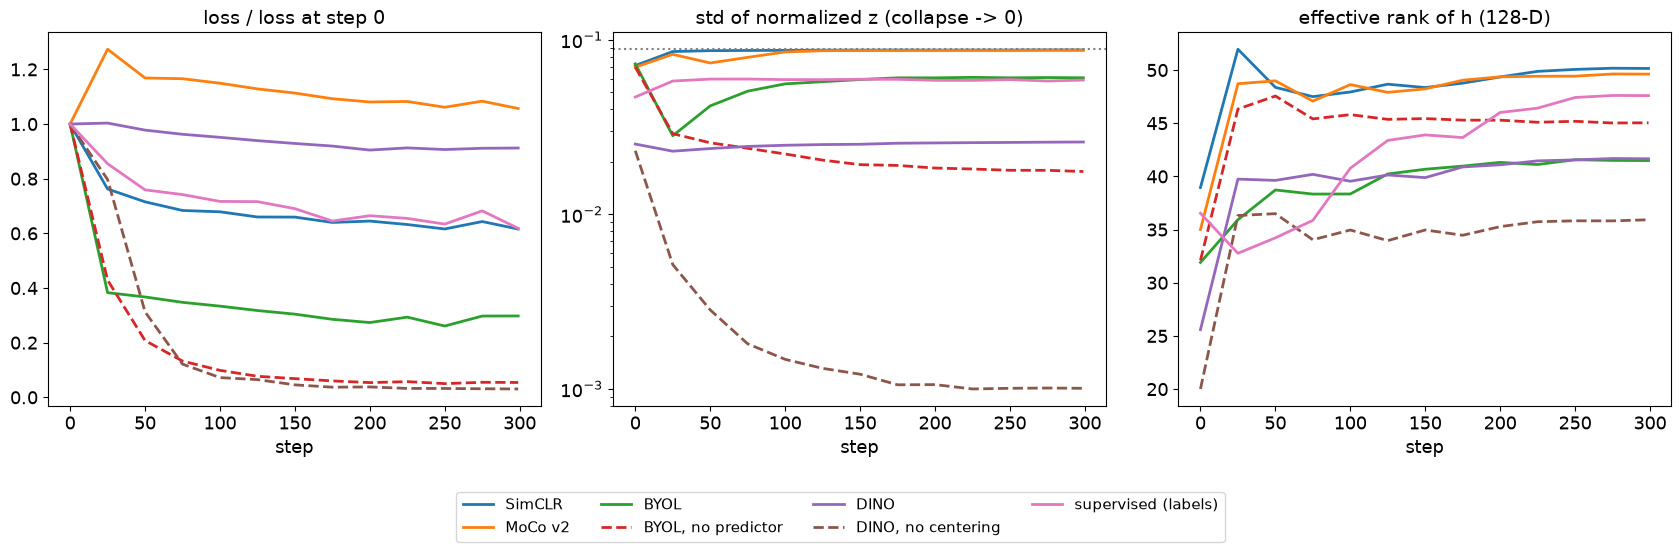

учитель DINO в конце:            H(mean P_t) = 6.55, mean H(P_t) = 5.27  (log K = 6.93)
учитель DINO без центрирования: H(mean P_t) = 0.28, mean H(P_t) = 0.09


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))
for name, h in HIST.items():
    ls = "--" if ("no " in name) else "-"
    ax[0].plot(h.step, h.loss / h.loss.iloc[0], ls, label=name, lw=2)
    ax[1].plot(h.step, h.z_std, ls, lw=2); ax[2].plot(h.step, h.h_erank, ls, lw=2)
ax[1].axhline(1 / math.sqrt(128), color="gray", ls=":")
ax[0].set_title("loss / loss at step 0"); ax[1].set_title("std of normalized z (collapse -> 0)"); ax[2].set_title("effective rank of h (128-D)")
for a in ax: a.set_xlabel("step")
ax[1].set_yscale("log")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=11, bbox_to_anchor=(0.5, 0.0))
plt.tight_layout(rect=(0, 0.13, 1, 1)); plt.show()
d = HIST["DINO"].iloc[-1]; dn = HIST["DINO, no centering"].iloc[-1]
print(f"учитель DINO в конце:            H(mean P_t) = {d['H(mean P_t)']:.2f}, mean H(P_t) = {d['mean H(P_t)']:.2f}  (log K = {math.log(1024):.2f})")
print(f"учитель DINO без центрирования: H(mean P_t) = {dn['H(mean P_t)']:.2f}, mean H(P_t) = {dn['mean H(P_t)']:.2f}")

**Что видно.** Средний график — главный. У SimCLR и MoCo std проекции держится на уровне $1/\sqrt{128}\approx0.088$. У DINO без центрирования он падает на два порядка, до 0.001, а потеря одновременно уходит почти в ноль. Это и есть коллапс: учитель и ученик договорились выдавать одно и то же. Энтропии учителя это подтверждают: без центрирования $H(\bar P_t)=0.28$ из $\log K=6.93$, то есть почти все изображения отправлены в один прототип; у исправного DINO 6.55. BYOL без предиктора тоже уходит вниз, до 0.018 против 0.061 у BYOL с предиктором, и его потеря подозрительно мала. Эффективный ранг $h$ при этом почти не страдает (36–45 против 42–51): за 300 шагов коллапс затронул голову, а не энкодер. Вывод для практики: мониторы надо снимать с того выхода, по которому считается потеря. Низкая потеря методов без негативов — тревожный, а не хороший знак.

### 11.1. MAE в миниатюре

Masked autoencoder (раздел 4.3) требует трансформера: маскирование патчей естественно для токенов. Соберём крошечный ViT:

- патчи 4×4, то есть 64 токена на изображение 32×32;
- энкодер: 4 блока, ширина 128, 4 головы;
- декодер: 2 блока, ширина 64;
- маскируется 75% патчей, энкодер видит только 16 видимых;
- потеря — MSE по пикселям маскированных патчей.

Аугментации у MAE минимальные: только кроп и отражение. Признак для оценки — среднее по всем 64 токенам энкодера без маски.

MAE: 0.92 млн параметров, 108 с, потеря 1.361 -> 0.511, kNN 0.322, linear 0.448


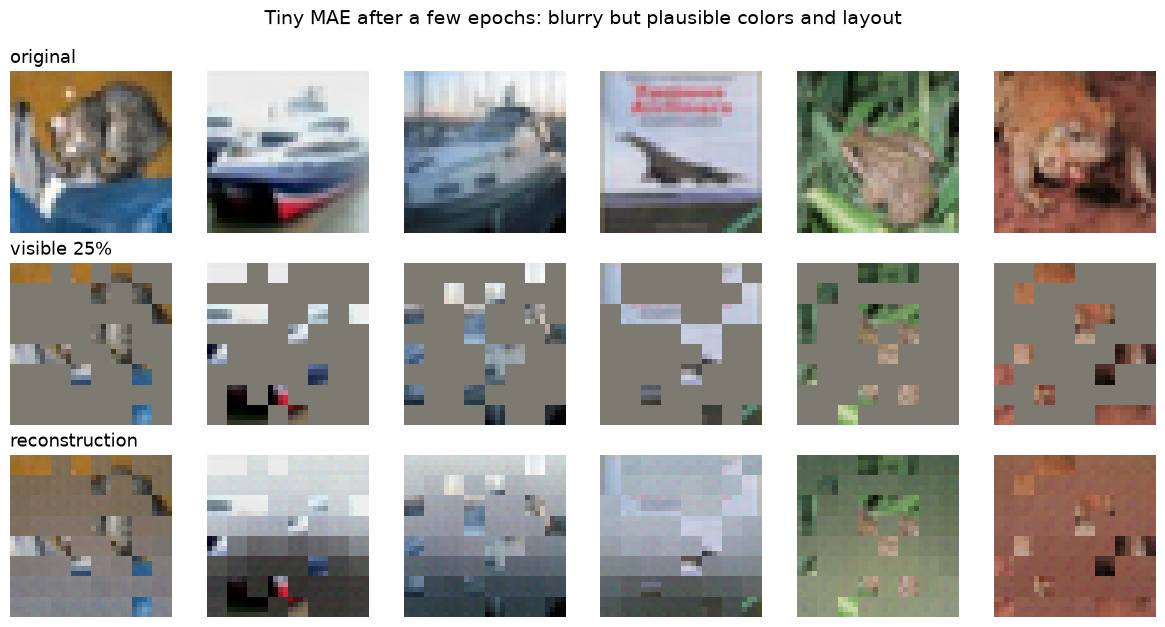

In [12]:
class TinyMAE(nn.Module):
    def __init__(self, patch=4, dim=128, depth=4, heads=4, dec_dim=64, dec_depth=2, mask_ratio=0.75):
        super().__init__()
        self.p, self.n, self.mask_ratio = patch, (32 // patch) ** 2, mask_ratio
        layer = lambda d, h: nn.TransformerEncoderLayer(d, h, 4 * d, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
        self.embed = nn.Conv2d(3, dim, patch, patch)
        self.pos = nn.Parameter(torch.randn(1, self.n, dim) * 0.02)
        self.blocks = nn.ModuleList([layer(dim, heads) for _ in range(depth)]); self.norm_e = nn.LayerNorm(dim)
        self.dec_embed = nn.Linear(dim, dec_dim); self.mask_token = nn.Parameter(torch.zeros(1, 1, dec_dim))
        self.dec_pos = nn.Parameter(torch.randn(1, self.n, dec_dim) * 0.02)
        self.dec_blocks = nn.ModuleList([layer(dec_dim, 4) for _ in range(dec_depth)]); self.norm_d = nn.LayerNorm(dec_dim)
        self.pred = nn.Linear(dec_dim, patch * patch * 3)
    @property
    def enc(self):        # для общего цикла: признаки даёт сам forward
        return self
    def patchify(self, x):
        B, p = x.shape[0], self.p
        return x.unfold(2, p, p).unfold(3, p, p).permute(0, 2, 3, 1, 4, 5).reshape(B, self.n, 3 * p * p)
    def unpatchify(self, t):
        B, p, g = t.shape[0], self.p, 32 // self.p
        return t.reshape(B, g, g, 3, p, p).permute(0, 3, 1, 4, 2, 5).reshape(B, 3, 32, 32)
    def encode(self, x, mask_ratio):
        tok = self.embed(x).flatten(2).transpose(1, 2) + self.pos
        B, keep = tok.shape[0], int(self.n * (1 - mask_ratio))
        order = torch.rand(B, self.n, device=x.device).argsort(1)
        ids_keep = order[:, :keep]
        tok = torch.gather(tok, 1, ids_keep[..., None].expand(-1, -1, tok.shape[2]))
        for b in self.blocks: tok = b(tok)
        return self.norm_e(tok), ids_keep
    def forward(self, x):                       # признаки для оценки: без маски, среднее по токенам
        return self.encode(x, 0.0)[0].mean(1)
    def reconstruct(self, x):
        lat, ids_keep = self.encode(x, self.mask_ratio)
        B, D = lat.shape[0], self.mask_token.shape[2]
        full = self.mask_token.expand(B, self.n, D).clone()
        full.scatter_(1, ids_keep[..., None].expand(-1, -1, D), self.dec_embed(lat))
        full = full + self.dec_pos
        for b in self.dec_blocks: full = b(full)
        mask = torch.ones(B, self.n, device=x.device); mask.scatter_(1, ids_keep, 0.0)
        return self.pred(self.norm_d(full)), mask
    def loss(self, x):
        v = augment(x, scale=(0.35, 1.0), p_jitter=0.0, p_gray=0.0)
        pred, mask = self.reconstruct(v)
        err = ((pred - self.patchify(v)) ** 2).mean(-1)
        return (err * mask).sum() / mask.sum(), pred.mean(1)
    def after_step(self, step, total): pass

mae, hist, sec = train_ssl(TinyMAE(), lr=1.5e-3)
RES["MAE (tiny ViT)"] = {**evaluate(mae), "sec": sec}; HIST_MAE = hist
print(f"MAE: {sum(p.numel() for p in mae.parameters())/1e6:.2f} млн параметров, {sec:.0f} с, потеря {hist.loss.iloc[0]:.3f} -> {hist.loss.iloc[-1]:.3f}, "
      f"kNN {RES['MAE (tiny ViT)']['kNN']:.3f}, linear {RES['MAE (tiny ViT)']['linear']:.3f}")

seed_all(3)
with torch.no_grad():
    mae.eval(); x = norm(XT[:6]).to(DEVICE); pred, mask = mae.reconstruct(x); mae.train()
    vis = mae.patchify(x) * (1 - mask[..., None])
    mix = mae.patchify(x) * (1 - mask[..., None]) + pred * mask[..., None]
fig, ax = plt.subplots(3, 6, figsize=(12, 6.4))
for j in range(6):
    for r, img in enumerate((x, mae.unpatchify(vis), mae.unpatchify(mix))):
        ax[r, j].imshow(show(img.cpu())[j]); ax[r, j].axis("off")
for r, t in enumerate(("original", "visible 25%", "reconstruction")):
    ax[r, 0].set_title(t, loc="left", fontsize=13)
plt.suptitle("Tiny MAE after a few epochs: blurry but plausible colors and layout", fontsize=14); plt.tight_layout(); plt.show()

**Что видно.** Потеря MAE упала с 1.36 до 0.51. Реконструкции размыты, но цвета и крупная раскладка сцены восстанавливаются по 16 видимым патчам из 64. Качество признаков низкое: k-NN 0.322 и linear 0.448 — k-NN даже ниже, чем у случайной CNN. Это согласуется с разделом 4.3: признаки MAE плохо линейно разделимы и раскрываются при дообучении. Кроме того, крошечному ViT без индуктивных смещений свёрток за 300 шагов труднее, чем CNN.

Сводная таблица мини-предобучения. `kNN` — weighted k-NN ($k=20$, $T=0.07$) с банком из 10 000 изображений пула, `linear` — логистическая регрессия по стандартизованным признакам, обе на 2000 тестовых изображениях. `h_erank` — эффективный ранг признаков энкодера. Столбцы `z_*` относятся к выходу проекционной головы, где считается SSL-потеря: k-NN, std нормированных векторов и эффективный ранг. Для DINO это 1024 логита головы.

In [13]:
mini = pd.DataFrame(RES).T[["kNN", "linear", "h_erank", "z_kNN", "z_std", "z_erank", "sec"]]
print(mini.round(3).to_string())

                       kNN  linear  h_erank  z_kNN  z_std  z_erank      sec
random init          0.356   0.439   24.282    NaN    NaN      NaN      NaN
SimCLR               0.462   0.510   50.673  0.460  0.087   61.298   61.155
MoCo v2              0.454   0.511   50.207  0.452  0.087   53.359   48.182
BYOL                 0.364   0.482   41.822  0.346  0.072   31.521   90.867
BYOL, no predictor   0.398   0.475   45.496  0.363  0.019   14.113   90.425
DINO                 0.387   0.476   42.104  0.333  0.027   15.326  129.232
DINO, no centering   0.384   0.482   36.135  0.330  0.001    1.759  130.336
supervised (labels)  0.568   0.602   48.373    NaN    NaN      NaN   29.989
MAE (tiny ViT)       0.322   0.448   22.693    NaN    NaN      NaN  107.616


**Что видно.** Столбцы `z_*` показывают то, что скрыто в $h$. У DINO без центрирования эффективный ранг 1024 логитов головы равен 1.8, std 0.001: голова схлопнулась. У исправного DINO ранг 15, у SimCLR 61. У BYOL без предиктора ранг проекции 14 против 32 у BYOL, но k-NN по $h$ у него даже выше (0.398 против 0.364). Короткое обучение не успевает передать коллапс головы энкодеру, поэтому сломанный метод по таблице качества «выглядит лучше» исправного. Это предупреждение: ранжирование методов по одной метрике на малом бюджете ненадёжно. Время обучения на CPU: от 48 с у MoCo до 130 с у DINO с multi-crop.

## 12. Предобученные энкодеры: что даёт масштаб

Мини-модели раздела 11 показывают механику, но не качество. Возьмём пять ViT, обученных по-разному, и сравним их признаки на одной подвыборке CIFAR-10. Изображения 32×32 увеличиваются до 224×224, как и в стандартных протоколах переноса.

| Имя | Веса | Как обучен |
|---|---|---|
| DINOv2 ViT-S/14 | `facebook/dinov2-small` | DINO + iBOT + KoLeo на LVD-142M, дистилляция из ViT-g ([Oquab et al.](https://arxiv.org/abs/2304.07193)) |
| DINO ViT-S/16 | `timm/vit_small_patch16_224.dino` | DINO на ImageNet-1k без меток ([Caron et al.](https://arxiv.org/abs/2104.14294)) |
| MAE ViT-B/16 | `facebook/vit-mae-base` | MAE на ImageNet-1k без меток ([He et al.](https://arxiv.org/abs/2111.06377)) |
| supervised ViT-S/16 | `timm/vit_small_patch16_224.augreg_in21k_ft_in1k` | с учителем на ImageNet-21k, затем ImageNet-1k ([Steiner et al.](https://arxiv.org/abs/2106.10270)) |
| random ViT-S/16 | без весов | случайная инициализация, нижняя граница |

Отдельных открытых весов iBOT в `timm` и `transformers` нет, поэтому iBOT представлен через DINOv2: его функция потерь включает iBOT-член на маскированных патчах (раздел 4.4).

Признак изображения — выход [CLS] после последнего LayerNorm. У MAE дополнительно берём среднее по патч-токенам: по [статье MAE](https://arxiv.org/abs/2111.06377) [CLS] при предобучении не получает отдельного сигнала, и тип признака важен (раздел 5.2).

Размер выборки: `per_class_tr` размеченных изображений на класс из train и `per_class_te` из test.

In [14]:
from transformers import AutoModel, ViTMAEForPreTraining
rng = np.random.RandomState(1)
def per_class(df, n):
    y = df.label.values
    return np.concatenate([rng.choice(np.where(y == c)[0], n, replace=False) for c in range(10)])
itr, ite = per_class(TR_ALL, S["per_class_tr"]), per_class(TE_ALL, S["per_class_te"])
XA_TR, YA_TR = decode(TR_ALL.img.values[itr]), TR_ALL.label.values[itr]
XA_TE, YA_TE = decode(TE_ALL.img.values[ite]), TE_ALL.label.values[ite]
print("размеченный train:", XA_TR.shape, " тест:", XA_TE.shape)

IMNET = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))
def prep(X_uint8, mean, std, size=224):
    x = torch.tensor(X_uint8).permute(0, 3, 1, 2).float() / 255
    x = F.interpolate(x, size=(size, size), mode="bicubic", align_corners=False).clamp(0, 1)
    return (x - torch.tensor(mean).view(1, 3, 1, 1)) / torch.tensor(std).view(1, 3, 1, 1)

_enc = {}
def get_encoder(name):
    """Возвращает (модель, функция признаков, mean, std)."""
    if name in _enc: return _enc[name]
    if name == "DINOv2 ViT-S/14":
        m = AutoModel.from_pretrained("facebook/dinov2-small")
        fn = lambda x: {"cls": m(pixel_values=x).pooler_output}
        mean, std = IMNET
    elif name == "MAE ViT-B/16":
        m = ViTMAEForPreTraining.from_pretrained("facebook/vit-mae-base")
        def fn(x):
            m.config.mask_ratio = 0.0                     # для признаков маску отключаем: энкодер видит все патчи
            hs = m.vit(pixel_values=x).last_hidden_state
            m.config.mask_ratio = 0.75
            return {"cls": hs[:, 0], "mean": hs[:, 1:].mean(1)}
        mean, std = IMNET
    else:
        mid = {"DINO ViT-S/16": "vit_small_patch16_224.dino", "supervised ViT-S/16": "vit_small_patch16_224.augreg_in21k_ft_in1k",
               "random ViT-S/16": "vit_small_patch16_224"}[name]
        seed_all(0)
        m = timm.create_model(mid, pretrained=name != "random ViT-S/16", num_classes=0, dynamic_img_size=True)
        cfg = timm.data.resolve_data_config({}, model=m); mean, std = cfg["mean"], cfg["std"]
        fn = lambda x: {"cls": m(x)}
    m = m.to(DEVICE).eval()
    _enc[name] = (m, fn, mean, std); return _enc[name]

def features(name, X, tag, bs=50):
    path = ART / f"{name.replace('/', '_').replace(' ', '_')}_{tag}.npz"
    if path.exists(): return dict(np.load(path))
    m, fn, mean, std = get_encoder(name); out = {}
    with torch.inference_mode():
        for i in range(0, len(X), bs):
            for k, v in fn(prep(X[i:i + bs], mean, std).to(DEVICE)).items():
                out.setdefault(k, []).append(v.float().cpu().numpy())
    out = {k: np.concatenate(v) for k, v in out.items()}
    np.savez(path, **out); return out

ENCODERS = ["DINOv2 ViT-S/14", "DINO ViT-S/16", "MAE ViT-B/16", "supervised ViT-S/16", "random ViT-S/16"]
FEAT = {}
for name in ENCODERS:
    t = time.time()
    ftr, fte = features(name, XA_TR, "tr"), features(name, XA_TE, "te")
    for k in ftr:
        key = name if k == "cls" else f"{name}, mean patch"
        FEAT[key] = (ftr[k], fte[k])
    print(f"{name:22s} dim {ftr['cls'].shape[1]:4d}  {time.time()-t:5.0f} с", flush=True)
print(f"с начала блокнота прошло {(time.time()-T0)/60:.1f} мин")

размеченный train: (1500, 32, 32, 3)  тест: (1000, 32, 32, 3)


DINOv2 ViT-S/14        dim  384    148 с


DINO ViT-S/16          dim  384     99 с


MAE ViT-B/16           dim  768    359 с


supervised ViT-S/16    dim  384    101 с


random ViT-S/16        dim  384    103 с


с начала блокнота прошло 26.0 мин


**Что видно.** Извлечение признаков на CPU заняло от 100 с (ViT-S) до 360 с (MAE ViT-B/16 с 86 млн параметров) на 2500 изображений 224×224. Это самая дорогая часть блокнота, поэтому признаки кэшируются в `npz`: повторный запуск занимает секунды.

### 12.1. Что видят модели: карты внимания DINO, главные компоненты патчей DINOv2, реконструкции MAE

Три классические картинки из статей, воспроизведённые на одной фотографии из COCO val2017 ([изображение 39769](http://images.cocodataset.org/val2017/000000039769.jpg), две кошки на диване) и на нескольких изображениях CIFAR-10.

- **Карты внимания [CLS] последнего слоя DINO.** По [статье DINO](https://arxiv.org/abs/2104.14294) головы внимания самообученного ViT выделяют объекты без какой-либо разметки сегментации.
- **PCA патч-признаков DINOv2.** По [статье DINOv2](https://arxiv.org/abs/2304.07193) первая главная компонента патчей отделяет объект от фона, а три компоненты, посчитанные затем только по патчам объектов и отображённые в RGB, совпадают на одинаковых частях разных объектов. Здесь первая компонента считается отдельно для каждого изображения; её знак произволен, поэтому фоном считается сторона, которая чаще встречается у краёв кадра. Три цветовые компоненты считаются совместно по всем четырём изображениям.
- **Реконструкция MAE** при маскировании 75% патчей.

Фотография подаётся в разрешении 448×448: позиционные эмбеддинги интерполируются, и карты получаются детальнее (28×28 патчей у ViT-S/16, 32×32 у ViT-S/14). Для карт внимания timm-модели внимание пересчитывается вручную из весов `qkv` последнего блока: быстрые ядра внимания матрицу не возвращают.

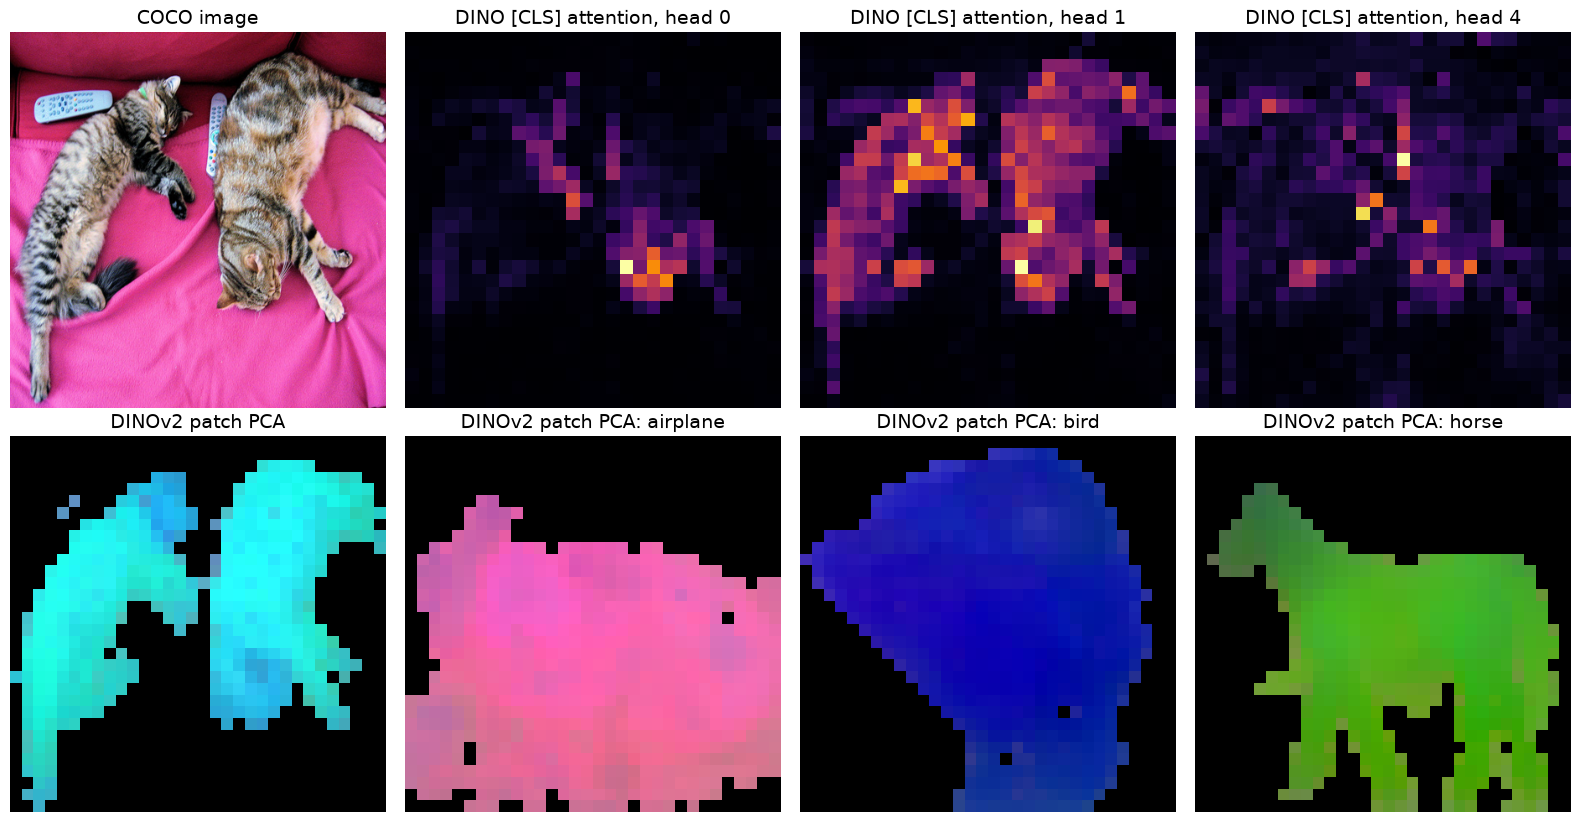

доля маскированных патчей: 0.75, MSE по маскированным патчам: 0.168


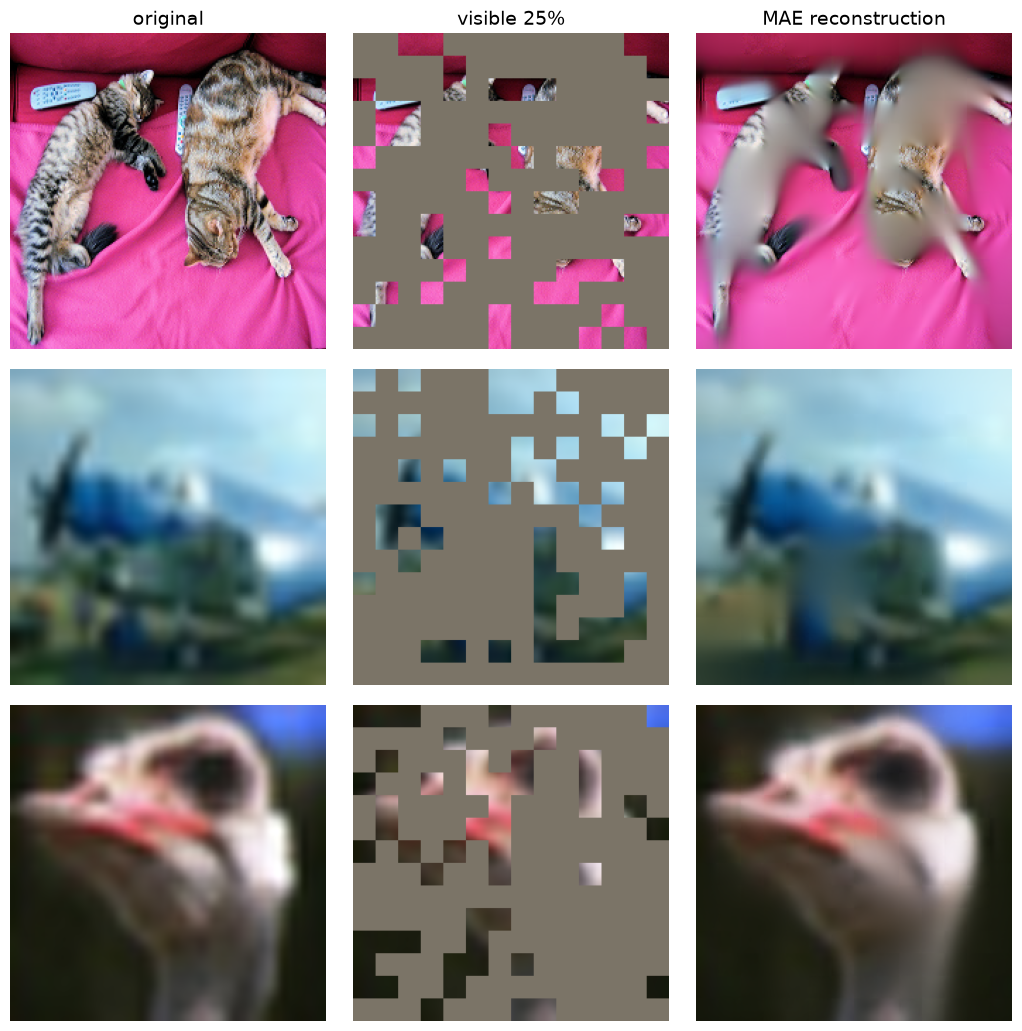

In [15]:
import urllib.request
try:
    with urllib.request.urlopen("http://images.cocodataset.org/val2017/000000039769.jpg", timeout=30) as r:
        COCO = Image.open(io.BytesIO(r.read())).convert("RGB")
except Exception as e:
    print("COCO недоступен, берём изображение CIFAR:", e); COCO = Image.fromarray(XA_TE[0])
coco = np.asarray(COCO.resize((448, 448), Image.BICUBIC))

@torch.no_grad()
def cls_attention_timm(m, x):
    """Внимание [CLS] -> патчи в последнем блоке timm-ViT, по головам."""
    feats = {}
    h = m.blocks[-1].norm1.register_forward_hook(lambda mod, i, o: feats.__setitem__("x", o))
    m(x); h.remove()
    a = m.blocks[-1].attn; B, N, C = feats["x"].shape
    qkv = a.qkv(feats["x"]).reshape(B, N, 3, a.num_heads, C // a.num_heads).permute(2, 0, 3, 1, 4)
    q, k = qkv[0], qkv[1]
    q, k = a.q_norm(q), a.k_norm(k)
    att = (q @ k.transpose(-2, -1) * a.scale).softmax(-1)
    return att[0, :, 0, 1:]                                   # (heads, patches)

m_dino, _, mean, std = get_encoder("DINO ViT-S/16")
x = prep(coco[None], mean, std, size=448).to(DEVICE)
att = cls_attention_timm(m_dino, x).reshape(-1, 28, 28).cpu().numpy()

m2, _, mean2, std2 = get_encoder("DINOv2 ViT-S/14")
with torch.no_grad():
    xs = prep(np.concatenate([coco[None], np.stack([np.asarray(Image.fromarray(XA_TE[i]).resize((448, 448), Image.BICUBIC)) for i in (5, 205, 705)])]), mean2, std2, size=448)
    pt = m2(pixel_values=xs.to(DEVICE)).last_hidden_state[:, 1:].cpu().numpy()   # (4, 32*32, 384)
g = int(math.sqrt(pt.shape[1]))
border = np.zeros((g, g), bool); border[:2] = border[-2:] = True; border[:, :2] = border[:, -2:] = True
fg = []
for i in range(len(pt)):                                   # шаг 1: первая компонента патчей каждого изображения
    p1 = PCA(1).fit_transform(pt[i])[:, 0].reshape(g, g)
    m = p1 > 0
    if m[border].mean() > m[~border].mean(): m = ~m          # знак компоненты произволен: фон чаще у краёв
    fg.append(m.ravel())
fg = np.concatenate(fg); flat = pt.reshape(-1, pt.shape[2])
pc3 = PCA(3).fit(flat[fg]).transform(flat)                 # шаг 2: три компоненты по патчам объектов всех изображений -> RGB
lo, hi = np.percentile(pc3[fg], 1, axis=0), np.percentile(pc3[fg], 99, axis=0)
pc3 = ((pc3 - lo) / (hi - lo)).clip(0, 1); pc3[~fg] = 0
pc3 = pc3.reshape(len(pt), g, g, 3)

fig, ax = plt.subplots(2, 4, figsize=(16, 8.4))
ax[0, 0].imshow(coco); ax[0, 0].set_title("COCO image")
for j, hd in enumerate((0, 1, 4)):
    ax[0, j + 1].imshow(att[hd], cmap="inferno"); ax[0, j + 1].set_title(f"DINO [CLS] attention, head {hd}")
for j in range(4):
    ax[1, j].imshow(pc3[j]); ax[1, j].set_title("DINOv2 patch PCA" if j == 0 else f"DINOv2 patch PCA: {CLASSES[YA_TE[(5, 205, 705)[j - 1]]]}")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()

m_mae = get_encoder("MAE ViT-B/16")[0]
with torch.no_grad():
    torch.manual_seed(0)
    xm = torch.cat([prep(coco[None], *IMNET), prep(XA_TE[[5, 205]], *IMNET)]).to(DEVICE)
    out = m_mae(pixel_values=xm)
    rec = m_mae.unpatchify(out.logits); mask = out.mask.unsqueeze(-1).repeat(1, 1, 16 * 16 * 3)
    mask = m_mae.unpatchify(mask)
    visible = xm * (1 - mask); mixed = xm * (1 - mask) + rec * mask
un = lambda t: (t.cpu() * torch.tensor(IMNET[1]).view(1, 3, 1, 1) + torch.tensor(IMNET[0]).view(1, 3, 1, 1)).clamp(0, 1).permute(0, 2, 3, 1).numpy()
fig, ax = plt.subplots(3, 3, figsize=(10.5, 10.5))
for i in range(3):
    for j, (img, t) in enumerate(((xm, "original"), (visible, "visible 25%"), (mixed, "MAE reconstruction"))):
        ax[i, j].imshow(un(img)[i]); ax[i, j].axis("off")
        if i == 0: ax[i, j].set_title(t)
print(f"доля маскированных патчей: {out.mask.mean().item():.2f}, MSE по маскированным патчам: {out.loss.item():.3f}")
plt.tight_layout(); plt.show()

**Что видно.** Головы DINO на фотографии из COCO выделяют кошек, хотя модель никогда не видела масок: голова 1 покрывает силуэты обеих кошек целиком, головы 0 и 4 акцентируют отдельные части — голову и лапы, — а на диван почти не реагируют. PCA патчей DINOv2 отделяет кошек от розового дивана, а на увеличенных изображениях CIFAR-10 — самолёт, птицу и лошадь от фона. Цвета трёх совместных компонент различаются по классам: кошки, самолёт, птица и лошадь получают разные оттенки, то есть патч-признаки несут семантику объекта. MAE по 25% видимых патчей восстанавливает фон и общий силуэт кошек, но шерсть и мелкие детали размыты: MSE по маскированным патчам 0.168. Это наглядная причина, по которой MAE учит раскладку и текстуру, а не категории.

## 13. Оценка представлений: k-NN, linear probe, few-shot, кривые по разметке

### 13.1. Один протокол на все модели

Правила из раздела 5.2: одинаковые изображения, одинаковое разбиение, замороженные энкодеры, гиперпараметры классификатора подбираются на валидации внутри train, а не на тесте.

- **k-NN**: weighted k-NN по косинусу, $k=20$, $T=0.07$ — протокол [DINO](https://arxiv.org/abs/2104.14294).
- **Linear probe**: логистическая регрессия по стандартизованным признакам. Сила регуляризации $C\in\{0.01, 0.1, 1\}$ выбирается на 20% train, затем модель переобучается на всём train.
- **Геометрия**: эффективный ранг и uniformity нормированных признаков (раздел 10.3).

                          dim    kNN  linear  best C    erank  uniformity
encoder                                                                  
DINOv2 ViT-S/14           384  0.947   0.957    0.01  296.154      -3.344
DINO ViT-S/16             384  0.909   0.919    0.01  262.770      -2.370
MAE ViT-B/16              768  0.692   0.820    0.10  143.279      -0.205
MAE ViT-B/16, mean patch  768  0.431   0.838    0.10  133.729      -1.283
supervised ViT-S/16       384  0.937   0.952    0.01  277.866      -2.827
random ViT-S/16           384  0.268   0.336    0.10   56.958      -1.671


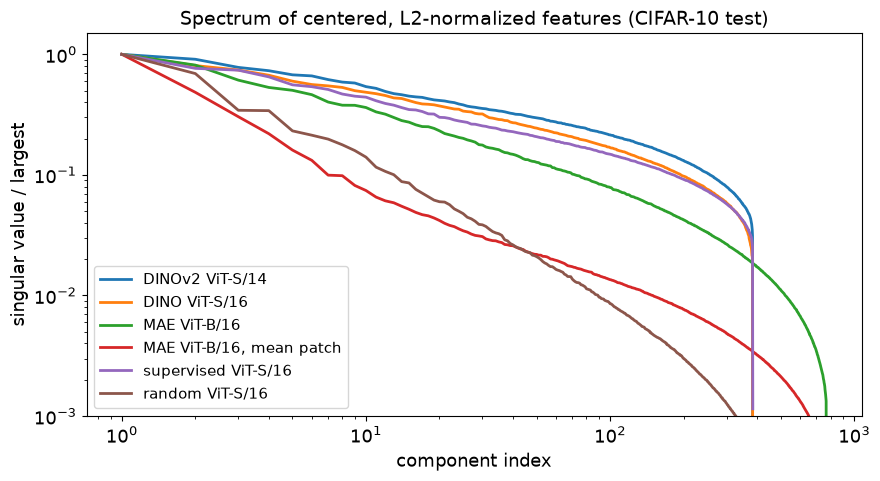

In [16]:
def linear_probe_cv(ftr, ytr, fte, yte, Cs=(0.01, 0.1, 1.0), seed=0):
    r = np.random.RandomState(seed); idx = r.permutation(len(ftr)); nv = len(ftr) // 5
    va, fit = idx[:nv], idx[nv:]
    best = max(Cs, key=lambda C: linear_probe(ftr[fit], ytr[fit], ftr[va], ytr[va], C))
    return linear_probe(ftr, ytr, fte, yte, best), best

rows = []
for key, (ftr, fte) in FEAT.items():
    lin, C = linear_probe_cv(ftr, YA_TR, fte, YA_TE)
    g = collapse_stats(torch.tensor(fte))
    rows.append({"encoder": key, "dim": ftr.shape[1], "kNN": knn_eval(ftr, YA_TR, fte, YA_TE), "linear": lin, "best C": C,
                 "erank": g["erank"], "uniformity": g["uniformity"]})
EVAL = pd.DataFrame(rows).set_index("encoder")
print(EVAL.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for key, (ftr, fte) in FEAT.items():
    z = F.normalize(torch.tensor(fte), dim=1)
    sv = torch.linalg.svdvals(z - z.mean(0)).numpy(); ax.loglog(np.arange(1, len(sv) + 1), sv / sv[0], lw=2, label=key)
ax.set_xlabel("component index"); ax.set_ylabel("singular value / largest"); ax.set_ylim(1e-3, 1.5)
ax.set_title("Spectrum of centered, L2-normalized features (CIFAR-10 test)"); ax.legend(fontsize=11); plt.tight_layout(); plt.show()

**Что видно.** Порядок по обоим протоколам: DINOv2 (k-NN 0.947, linear 0.957) ≥ supervised ViT-S/16 (0.937 и 0.952) > DINO (0.909 и 0.919) ≫ MAE ≫ случайная сеть (0.268 и 0.336). Самообученная DINOv2 на этом переносе не уступает модели, обученной с метками ImageNet-21k. MAE — главный урок раздела. Разрыв k-NN и linear у неё огромен: по [CLS] 0.692 против 0.820, по среднему патчей 0.431 против 0.838. Признаки содержат информацию о классе, но не в косинусной геометрии, которую использует k-NN. Тип признака меняет k-NN почти вдвое. Геометрия согласуется с качеством: эффективный ранг 296 у DINOv2 и 57 у случайной сети, uniformity −3.34 против −0.21 у [CLS] MAE. На графике спектра DINOv2 и DINO затухают медленнее всех, а среднее патчей MAE и случайная сеть — быстрее всех.

### 13.2. Чувствительность k-NN к $k$ и температуре

Weighted k-NN считается надёжным именно потому, что почти не требует настройки. Проверим это на признаках DINOv2.

In [17]:
ftr, fte = FEAT["DINOv2 ViT-S/14"]
grid = pd.DataFrame({f"T={T}": {k: knn_eval(ftr, YA_TR, fte, YA_TE, k=k, T=T) for k in (1, 5, 10, 20, 50, 100, 200)} for T in (0.02, 0.07, 0.5)})
grid.index.name = "k"
print(grid.round(3).to_string())

     T=0.02  T=0.07  T=0.5
k                         
1     0.937   0.937  0.937
5     0.936   0.946  0.944
10    0.937   0.949  0.948
20    0.939   0.947  0.939
50    0.941   0.947  0.932
100   0.941   0.948  0.930
200   0.941   0.947  0.920


**Что видно.** Таблица почти плоская: при $T=0.07$ точность от 0.937 ($k=1$) до 0.949 ($k=10$). Худшее значение во всей сетке 0.920 ($k=200$, $T=0.5$): при большой температуре далёкие соседи голосуют почти наравне с близкими. Протокол $k=20$, $T=0.07$ находится на плато, и на хороших признаках k-NN действительно почти не требует настройки.

### 13.3. Few-shot: прототипы против логистической регрессии

Протокол: $n$ размеченных примеров на класс из train ($n=1, 2, 5, 10$), оценка на всём тесте, 10 случайных эпизодов на каждое $n$. Два классификатора:

- **прототипы** (nearest class mean): средний нормированный вектор класса, предсказание — ближайший по косинусу прототип ([Snell et al.](https://arxiv.org/abs/1703.05175));
- **логистическая регрессия** с $C=0.1$.

Выводим среднее и полуширину 95%-го доверительного интервала $1.96\,\sigma/\sqrt{n_{\text{ep}}}$.

In [18]:
def sample_shots(y, n, seed):
    r = np.random.RandomState(seed)
    return np.concatenate([r.choice(np.where(y == c)[0], n, replace=False) for c in range(10)])

def prototype_acc(ftr, ytr, fte, yte):
    ftr, fte = normalize(ftr), normalize(fte)
    P = normalize(np.stack([ftr[ytr == c].mean(0) for c in range(10)]))
    return ((fte @ P.T).argmax(1) == yte).mean()

FS_MODELS = ["DINOv2 ViT-S/14", "DINO ViT-S/16", "MAE ViT-B/16, mean patch", "supervised ViT-S/16", "random ViT-S/16"]
rows = []
for key in FS_MODELS:
    ftr, fte = FEAT[key]
    for n in (1, 2, 5, 10):
        pa, la = [], []
        for ep in range(10):
            i = sample_shots(YA_TR, n, 100 + ep)
            pa.append(prototype_acc(ftr[i], YA_TR[i], fte, YA_TE)); la.append(linear_probe(ftr[i], YA_TR[i], fte, YA_TE, C=0.1))
        ci = lambda a: 1.96 * np.std(a) / np.sqrt(len(a))
        rows.append({"encoder": key, "shots": n, "prototypes": f"{np.mean(pa):.3f} ± {ci(pa):.3f}", "logreg": f"{np.mean(la):.3f} ± {ci(la):.3f}",
                     "proto range": f"{min(pa):.2f}-{max(pa):.2f}"})
FS = pd.DataFrame(rows)
print(FS.to_string(index=False))

                 encoder  shots    prototypes        logreg proto range
         DINOv2 ViT-S/14      1 0.705 ± 0.022 0.691 ± 0.028   0.64-0.76
         DINOv2 ViT-S/14      2 0.789 ± 0.015 0.784 ± 0.017   0.74-0.82
         DINOv2 ViT-S/14      5 0.869 ± 0.012 0.877 ± 0.012   0.82-0.90
         DINOv2 ViT-S/14     10 0.906 ± 0.006 0.919 ± 0.004   0.89-0.92
           DINO ViT-S/16      1 0.567 ± 0.024 0.568 ± 0.029   0.49-0.62
           DINO ViT-S/16      2 0.675 ± 0.026 0.682 ± 0.021   0.56-0.71
           DINO ViT-S/16      5 0.786 ± 0.015 0.795 ± 0.015   0.73-0.82
           DINO ViT-S/16     10 0.840 ± 0.010 0.845 ± 0.008   0.81-0.87
MAE ViT-B/16, mean patch      1 0.150 ± 0.010 0.368 ± 0.022   0.12-0.17
MAE ViT-B/16, mean patch      2 0.176 ± 0.012 0.441 ± 0.020   0.14-0.20
MAE ViT-B/16, mean patch      5 0.198 ± 0.010 0.570 ± 0.014   0.17-0.23
MAE ViT-B/16, mean patch     10 0.219 ± 0.007 0.650 ± 0.010   0.20-0.23
     supervised ViT-S/16      1 0.718 ± 0.030 0.665 ± 0.028   0.

**Что видно.** При одном примере на класс DINOv2 и supervised ViT дают около 0.70, DINO — 0.57, случайная сеть — 0.14 при уровне случайного угадывания 0.10. Разброс эпизодов большой: у DINOv2 при $n=1$ от 0.64 до 0.76, поэтому одно число без интервала вводит в заблуждение. На хороших признаках прототипы и логистическая регрессия равны в пределах интервалов. На MAE они расходятся сильнее всего: 0.15 у прототипов против 0.37 у логрегрессии при $n=1$. Средний вектор класса в косинусной метрике у MAE почти бесполезен, линейный классификатор находит информативные направления.

### 13.4. Кривые качества по объёму разметки

Главный график раздела 5.6: качество как функция числа размеченных примеров на класс. Для каждой точки 5 случайных подвыборок, полоса — одно стандартное отклонение. Число соседей в k-NN — $\min(20, n)$, чтобы при одном примере на класс не голосовали чужие классы.

кривые: 51 с


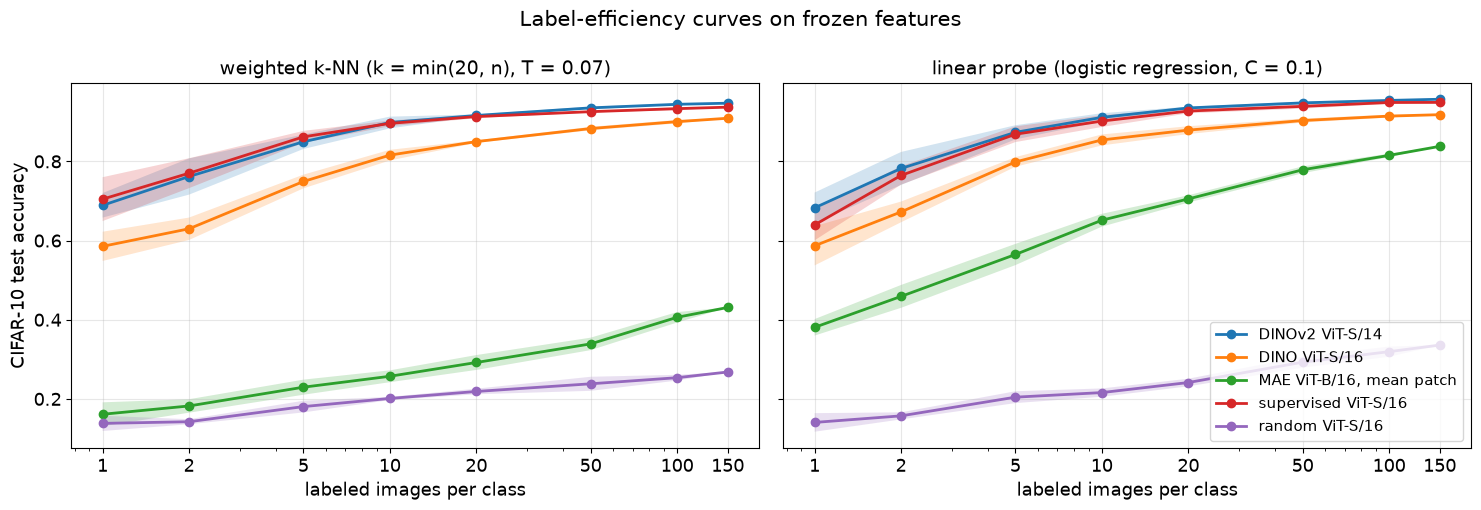

                          knn n=1  knn n=10  knn n=150  lin n=1  lin n=10  lin n=150
DINOv2 ViT-S/14             0.689     0.898      0.947    0.683     0.911      0.957
DINO ViT-S/16               0.585     0.816      0.909    0.587     0.854      0.918
MAE ViT-B/16, mean patch    0.161     0.257      0.431    0.381     0.651      0.838
supervised ViT-S/16         0.705     0.896      0.937    0.640     0.902      0.949
random ViT-S/16             0.138     0.201      0.268    0.141     0.216      0.336


In [19]:
NS = [n for n in (1, 2, 5, 10, 20, 50, 100, 150, 300, 500) if n <= S["per_class_tr"]]
CURVES = {}
t = time.time()
for key in FS_MODELS:
    ftr, fte = FEAT[key]; CURVES[key] = {"knn": [], "lin": []}
    for n in NS:
        reps = 1 if n == S["per_class_tr"] else S["seeds"]
        kk, ll = [], []
        for sd in range(reps):
            i = sample_shots(YA_TR, n, sd) if n < S["per_class_tr"] else np.arange(len(YA_TR))
            kk.append(knn_eval(ftr[i], YA_TR[i], fte, YA_TE, k=min(20, n)))
            ll.append(linear_probe(ftr[i], YA_TR[i], fte, YA_TE, C=0.1))
        CURVES[key]["knn"].append((np.mean(kk), np.std(kk))); CURVES[key]["lin"].append((np.mean(ll), np.std(ll)))
print(f"кривые: {time.time()-t:.0f} с")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for key in FS_MODELS:
    for a, kind in zip(ax, ("knn", "lin")):
        m, s = np.array(CURVES[key][kind]).T
        a.plot(NS, m, "o-", lw=2, label=key); a.fill_between(NS, m - s, m + s, alpha=0.2)
for a, t_ in zip(ax, ("weighted k-NN (k = min(20, n), T = 0.07)", "linear probe (logistic regression, C = 0.1)")):
    a.set_xscale("log"); a.set_xticks(NS); a.set_xticklabels(NS); a.set_xlabel("labeled images per class"); a.set_title(t_); a.grid(alpha=0.3)
ax[0].set_ylabel("CIFAR-10 test accuracy")
ax[1].legend(fontsize=11, loc="lower right"); plt.suptitle("Label-efficiency curves on frozen features", fontsize=15); plt.tight_layout(); plt.show()
tab = pd.DataFrame({key: {f"{kind} n={n}": CURVES[key][kind][j][0] for kind in ("knn", "lin") for j, n in enumerate(NS) if n in (1, 10, NS[-1])} for key in FS_MODELS}).T
print(tab.round(3).to_string())

**Что видно.** Кривые подтверждают главное свойство хороших представлений — эффективность по разметке. DINOv2 с 10 примерами на класс (0.898 по k-NN) почти догоняет DINO со 150 (0.909), а MAE со 150 примерами по linear (0.838) уступает DINOv2 с 5 примерами (около 0.87 на графике). Кривые DINOv2 и supervised почти совпадают; при $n=1$ supervised чуть выше по k-NN (0.705 против 0.689), но ниже по linear (0.640 против 0.683). Расстояние между кривыми сокращается с ростом $n$: сравнивать представления полезнее в левой части графика.

## 14. Визуализация эмбеддингов: PCA, t-SNE, UMAP

### 14.1. Три проекции одних признаков

Проецируем тестовые признаки DINOv2 тремя методами, а для сравнения строим UMAP признаков других энкодеров. Перед t-SNE и UMAP признаки сжимаются PCA до 50 компонент: это стандартный приём, он ускоряет расчёт и убирает шум (раздел 6.2).

Картинку нельзя принимать на веру, поэтому для каждой проекции считаем два числа:

- **trustworthiness@10** ([Venna, Kaski, 2001](https://link.springer.com/chapter/10.1007/3-540-44668-0_68)) — насколько 10 ближайших соседей точки на плоскости действительно были её соседями в исходном пространстве, от 0 до 1;
- **точность 10-NN на плоскости** (leave-one-out) против той же точности в полном пространстве: сколько информации о классе пережило проекцию.

                 projection  trust@10  10-NN acc
                 full 384-D     1.000      0.936
                        PCA     0.808      0.662
      t-SNE (perplexity 30)     0.975      0.921
      UMAP (n_neighbors 15)     0.973      0.928
UMAP of supervised ViT-S/16     0.969      0.921
       UMAP of MAE ViT-B/16     0.916      0.541
    UMAP of random ViT-S/16     0.984      0.216
19 с


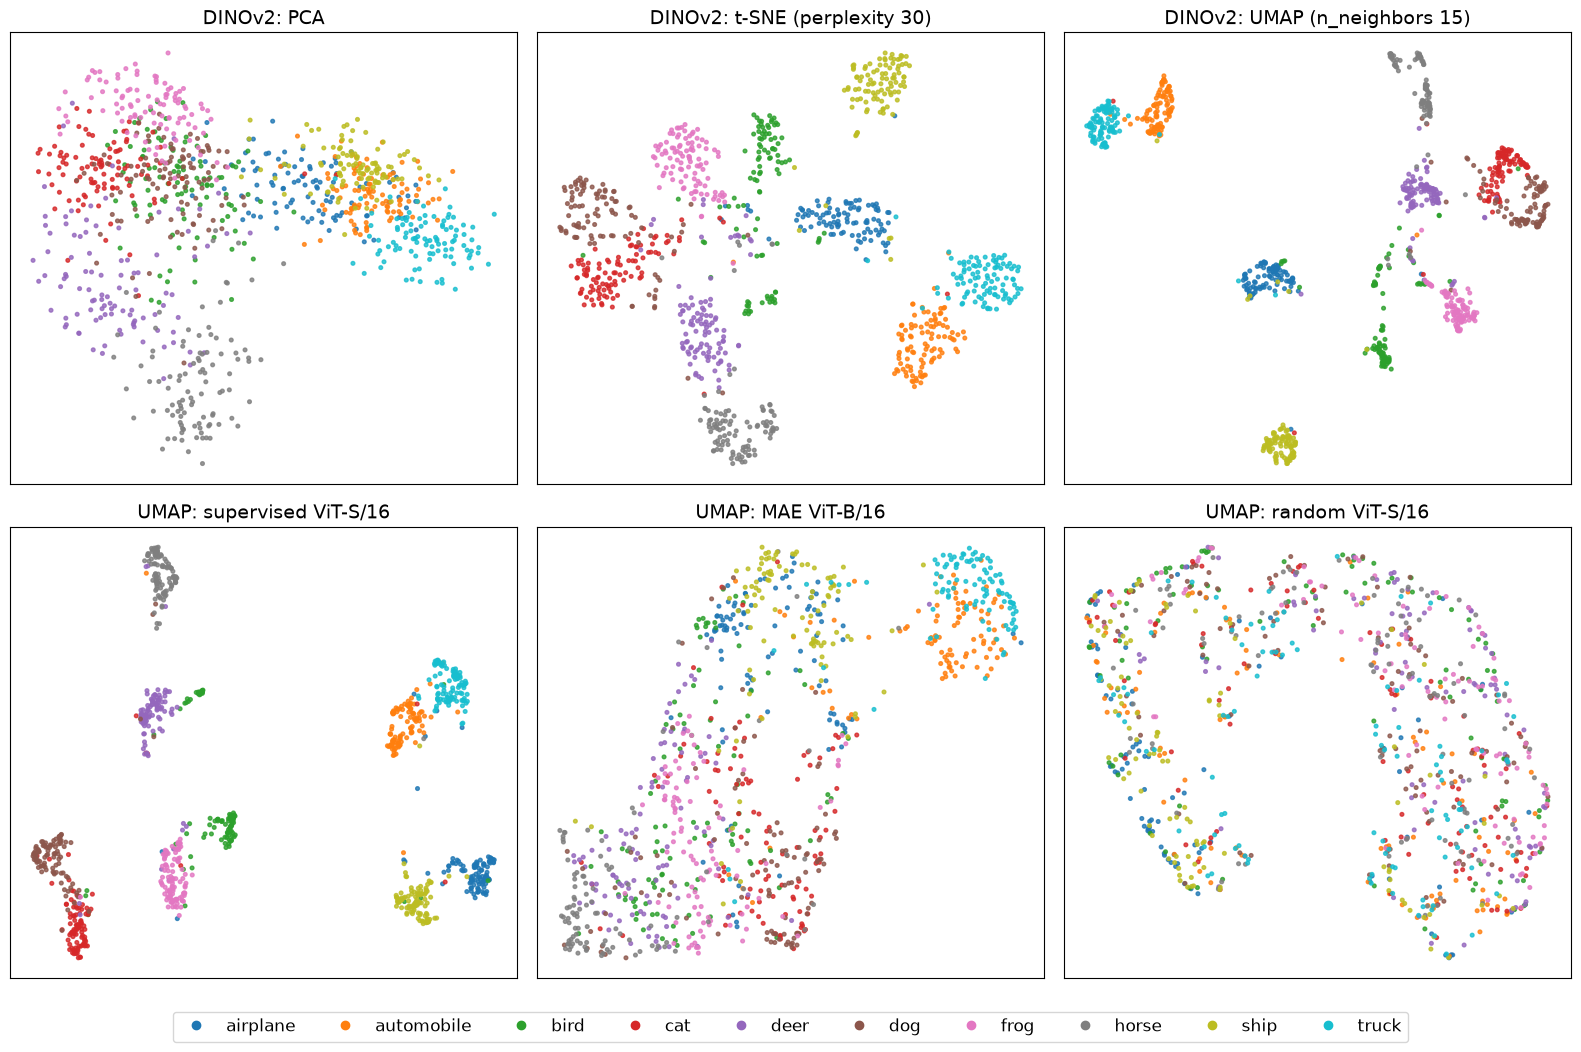

In [20]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

def loo_knn(Z, y, k=10):
    return cross_val_score(KNeighborsClassifier(k), Z, y, cv=5).mean()

def project_all(X, seed=0):
    X50 = PCA(50, random_state=seed).fit_transform(normalize(X))
    return {"PCA": PCA(2, random_state=seed).fit_transform(normalize(X)),
            "t-SNE (perplexity 30)": TSNE(2, perplexity=30, init="pca", random_state=seed).fit_transform(X50),
            "UMAP (n_neighbors 15)": umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=seed).fit_transform(X50)}

t = time.time()
fte = FEAT["DINOv2 ViT-S/14"][1]
PROJ = project_all(fte)
rows = [{"projection": "full 384-D", "trust@10": 1.0, "10-NN acc": loo_knn(normalize(fte), YA_TE)}]
for k, Z in PROJ.items():
    rows.append({"projection": k, "trust@10": trustworthiness(normalize(fte), Z, n_neighbors=10), "10-NN acc": loo_knn(Z, YA_TE)})
others = {k: umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=0).fit_transform(PCA(50, random_state=0).fit_transform(normalize(FEAT[k][1])))
          for k in ("supervised ViT-S/16", "MAE ViT-B/16", "random ViT-S/16")}
for k, Z in others.items():
    rows.append({"projection": f"UMAP of {k}", "trust@10": trustworthiness(normalize(FEAT[k][1]), Z, n_neighbors=10), "10-NN acc": loo_knn(Z, YA_TE)})
print(pd.DataFrame(rows).round(3).to_string(index=False)); print(f"{time.time()-t:.0f} с")

cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(2, 3, figsize=(16, 10.5))
for a, (k, Z) in zip(ax.flat, list(PROJ.items()) + [(f"UMAP: {k}", Z) for k, Z in others.items()]):
    a.scatter(Z[:, 0], Z[:, 1], c=[cmap(c) for c in YA_TE], s=7, alpha=0.8)
    a.set_title(k if k.startswith("UMAP:") else f"DINOv2: {k}"); a.set_xticks([]); a.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=cmap(c), label=CLASSES[c]) for c in range(10)]
fig.legend(handles=handles, loc="lower center", ncol=10, fontsize=12, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Что видно.** Картинки t-SNE и UMAP для DINOv2 выглядят как десять чистых кластеров, PCA — как размытое облако. Цифры говорят то же. Trustworthiness: PCA 0.81, t-SNE 0.975, UMAP 0.973. Точность 10-NN на плоскости: 0.662 у PCA и 0.92–0.93 у t-SNE и UMAP при 0.936 в полном пространстве. Две нелинейные проекции сохранили почти всю информацию о классе, а PCA с двумя компонентами её теряет. Поучительна случайная сеть: у её UMAP trustworthiness самая высокая (0.984), а 10-NN — 0.216. Проекция честно сохранила соседства, просто в исходных признаках соседи не связаны с классом. Поэтому trustworthiness проверяет проекцию, а не представление. UMAP MAE — смесь с отдельным островом транспорта (автомобили и грузовики), 10-NN 0.541, в согласии с низким k-NN в разделе 13.

### 14.2. Как t-SNE рисует кластеры из шума

Повторим пример из статьи [Wattenberg et al., Distill](https://distill.pub/2016/misread-tsne/): 500 точек стандартного нормального распределения в 100-мерном пространстве. Кластеров там нет по построению. Проекции при трёх значениях perplexity и, для контроля, при нескольких seed.

perplexity   2, seed 0: trust@10 = 0.648


perplexity   2, seed 1: trust@10 = 0.653


perplexity  30, seed 0: trust@10 = 0.697


perplexity 100, seed 0: trust@10 = 0.632


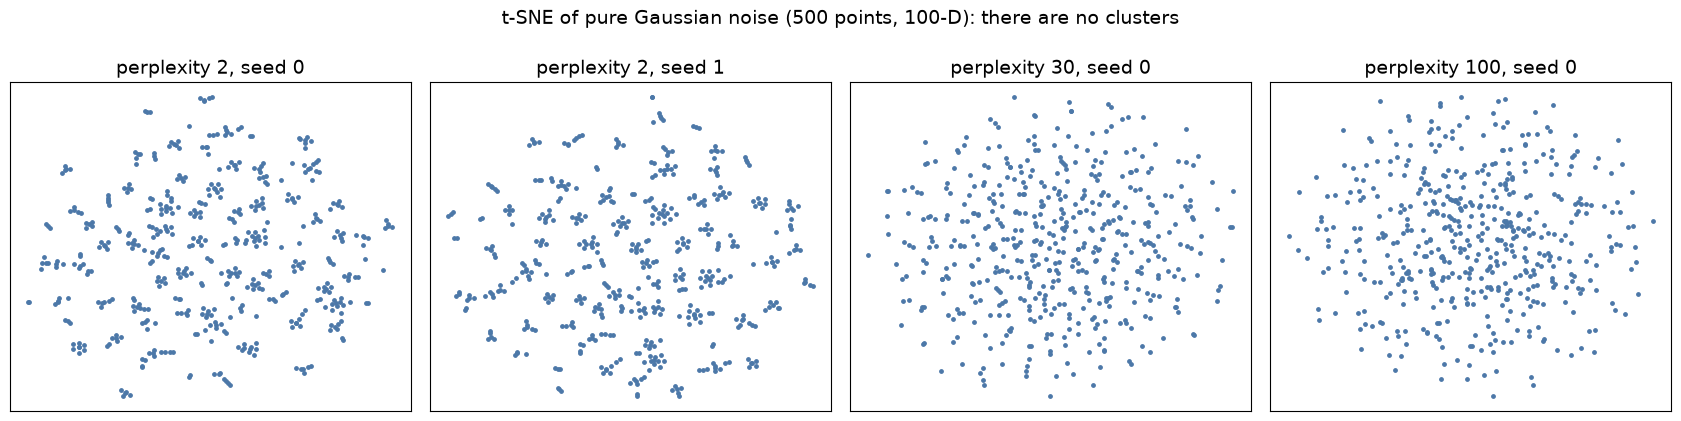

In [21]:
seed_all(0)
noise = np.random.randn(500, 100)
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
for a, (p, sd) in zip(ax, ((2, 0), (2, 1), (30, 0), (100, 0))):
    Z = TSNE(2, perplexity=p, init="random", random_state=sd).fit_transform(noise)
    a.scatter(Z[:, 0], Z[:, 1], s=6, color="#4C78A8"); a.set_title(f"perplexity {p}, seed {sd}"); a.set_xticks([]); a.set_yticks([])
    print(f"perplexity {p:3d}, seed {sd}: trust@10 = {trustworthiness(noise, Z, n_neighbors=10):.3f}")
plt.suptitle("t-SNE of pure Gaussian noise (500 points, 100-D): there are no clusters", fontsize=14); plt.tight_layout(); plt.show()

**Что видно.** При perplexity 2 t-SNE рисует десятки мелких «кластеров» из чистого гауссова шума, и при другом seed их расположение другое. При perplexity 30 и 100 облако однородное, как и должно быть. Trustworthiness на шуме 0.63–0.70 при любой perplexity, заметно ниже 0.97 на признаках DINOv2: высокая trustworthiness и устойчивость картинки к seed — минимальная проверка, прежде чем говорить о кластерах.

## 15. Паразитные признаки и shortcut learning: контролируемый эксперимент

### 15.1. Постановка

Бинарная задача «кошка / собака» из CIFAR-10. В обучающей выборке красный квадрат 8×8 в левом верхнем углу стоит на 95% кошек и 5% собак: квадрат почти идеально предсказывает класс, как больничная метка у [Zech et al.](https://journals.plos.org/plosmedicine/article?id=10.1371/journal.pmed.1002683). Три тестовых набора из одних и тех же тестовых изображений:

- **clean** — без квадратов;
- **flipped** — корреляция перевёрнута: квадрат на 95% собак и 5% кошек;
- **probe** — квадрат с вероятностью 0.5 независимо от класса, для проверки, закодирован ли квадрат в признаках.

Групп четыре: (класс, есть квадрат). Кроме средней точности считаем **worst-group accuracy** на flipped — точность на худшей из четырёх групп (раздел 7.5).

In [22]:
rs = np.random.RandomState(2)
def cat_dog(df, n):
    y = df.label.values
    idx = np.concatenate([rs.choice(np.where(y == c)[0], n, replace=False) for c in (3, 5)])
    return decode(df.img.values[idx]), (y[idx] == 5).astype(int)          # 0 = cat, 1 = dog

def stamp(X, y, p_cat, p_dog, seed):
    r = np.random.RandomState(seed); X = X.copy(); s = np.zeros(len(X), int)
    for i in range(len(X)):
        if r.rand() < (p_cat if y[i] == 0 else p_dog):
            X[i, :8, :8] = (255, 0, 0); s[i] = 1
    return X, s

Xs_tr0, ys_tr = cat_dog(TR_ALL, S["shortcut_tr"]); Xs_te0, ys_te = cat_dog(TE_ALL, S["shortcut_te"])
SC = {"train": stamp(Xs_tr0, ys_tr, 0.95, 0.05, 0), "clean": (Xs_te0, np.zeros(len(Xs_te0), int)),
      "flipped": stamp(Xs_te0, ys_te, 0.05, 0.95, 1), "probe": stamp(Xs_te0, ys_te, 0.5, 0.5, 2)}
YS = {"train": ys_tr, "clean": ys_te, "flipped": ys_te, "probe": ys_te}
print(pd.crosstab(pd.Series(ys_tr, name="class (0 cat, 1 dog)"), pd.Series(SC["train"][1], name="square")))

def group_report(y, pred, s):
    acc = {}
    for c in (0, 1):
        for a in (0, 1):
            m = (y == c) & (s == a)
            if m.sum(): acc[f"{'cat' if c == 0 else 'dog'}{'+sq' if a else ''}"] = (pred[m] == c).mean()
    return acc

square                  0    1
class (0 cat, 1 dog)          
0                      18  282
1                     283   17


**Что видно.** Корреляция в train почти идеальная: квадрат стоит у 282 из 300 кошек и только у 17 из 300 собак. Классификатор, который смотрит только на угол, получит на train 94%.

### 15.2. Модели и способы борьбы

1. **CNN с нуля** на пикселях смещённого train: `SmallCNN` шириной 32 с линейной головой, 40 эпох Adam. Отражения не используются, иначе квадрат переезжал бы в другой угол.
2. **CNN + перевзвешивание групп**: вес примера обратно пропорционален размеру его группы. Метки групп при этом нужны.
3. **CNN + аугментация против артефакта**: квадрат случайно ставится на половину изображений независимо от класса. Нужно знать, какой артефакт искать.
4. **DINOv2 (заморожен) + linear probe** на том же смещённом train.
5. **DINOv2 + переобучение последнего слоя** на маленькой сбалансированной выборке: по 15 изображений из каждой группы train. Это идея DFR ([Kirichenko et al.](https://arxiv.org/abs/2204.02937)).

In [23]:
def train_cnn(X, y, s, mode="erm", epochs=40, seed=0):
    seed_all(seed)
    net = nn.Sequential(SmallCNN(32), nn.Linear(256, 2)).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    g = 2 * y + s; w = (1.0 / np.bincount(g, minlength=4)[g]) if mode == "reweight" else np.ones(len(y))
    w = torch.tensor(w / w.mean(), dtype=torch.float32)
    xt, yt = to_tensor(X), torch.tensor(y)
    for ep in range(epochs):
        perm = torch.randperm(len(xt))
        for b in range(0, len(xt), 64):
            i = perm[b:b + 64]; xb = xt[i].clone()
            if mode == "augment":                                       # квадрат независимо от класса
                on = torch.rand(len(i)) < 0.5
                xb[on, :, :8, :8] = torch.tensor([1.0, 0, 0]).view(3, 1, 1)
                xb[~on, :, :8, :8] = to_tensor(Xs_tr0[i[~on].numpy()])[:, :, :8, :8]   # снять квадрат: исходные пиксели
            loss = (F.cross_entropy(net(norm(xb).to(DEVICE)), yt[i].to(DEVICE), reduction="none") * w[i].to(DEVICE)).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

@torch.no_grad()
def cnn_predict(net, X):
    return torch.cat([net(norm(to_tensor(X[i:i + 500])).to(DEVICE)).argmax(1).cpu() for i in range(0, len(X), 500)]).numpy()

t = time.time()
Xtr_b, s_tr = SC["train"]
SC_RES, CNN = {}, {}
for mode, title in (("erm", "CNN from scratch"), ("reweight", "CNN + group reweighting"), ("augment", "CNN + anti-artifact augmentation")):
    CNN[mode] = net = train_cnn(Xtr_b, ys_tr, s_tr, mode)
    r = {k: (cnn_predict(net, SC[k][0]) == YS[k]).mean() for k in ("train", "clean", "flipped")}
    r["worst group (flipped)"] = min(group_report(ys_te, cnn_predict(net, SC["flipped"][0]), SC["flipped"][1]).values())
    SC_RES[title] = r
print(f"CNN: {time.time()-t:.0f} с")

t = time.time()
SF = {k: normalize(features("DINOv2 ViT-S/14", SC[k][0], f"shortcut_{k}")["cls"]) for k in SC}
print(f"признаки DINOv2: {time.time()-t:.0f} с")
lp = LogisticRegression(max_iter=3000).fit(SF["train"], ys_tr)
r = {k: lp.score(SF[k], YS[k]) for k in ("train", "clean", "flipped")}
r["worst group (flipped)"] = min(group_report(ys_te, lp.predict(SF["flipped"]), SC["flipped"][1]).values())
SC_RES["DINOv2 + linear probe"] = r
g = 2 * ys_tr + s_tr
bal = np.concatenate([np.random.RandomState(3).choice(np.where(g == k)[0], min(15, (g == k).sum()), replace=False) for k in range(4)])
lp_dfr = LogisticRegression(max_iter=3000).fit(SF["train"][bal], ys_tr[bal])
r = {k: lp_dfr.score(SF[k], YS[k]) for k in ("train", "clean", "flipped")}
r["worst group (flipped)"] = min(group_report(ys_te, lp_dfr.predict(SF["flipped"]), SC["flipped"][1]).values())
SC_RES[f"DINOv2 + last-layer retraining ({len(bal)} balanced)"] = r
SCR = pd.DataFrame(SC_RES).T
print(SCR.round(3).to_string())
print("\nгруппы на flipped, CNN с нуля:", {k: round(float(v), 3) for k, v in group_report(ys_te, cnn_predict(CNN["erm"], SC["flipped"][0]), SC["flipped"][1]).items()})
print("группы на flipped, DINOv2 + LP:", {k: round(float(v), 3) for k, v in group_report(ys_te, lp.predict(SF["flipped"]), SC["flipped"][1]).items()})

CNN: 47 с


признаки DINOv2: 107 с
                                              train  clean  flipped  worst group (flipped)
CNN from scratch                              1.000  0.515    0.092                  0.016
CNN + group reweighting                       1.000  0.518    0.085                  0.005
CNN + anti-artifact augmentation              1.000  0.680    0.670                  0.500
DINOv2 + linear probe                         0.977  0.952    0.912                  0.868
DINOv2 + last-layer retraining (60 balanced)  0.937  0.930    0.920                  0.889

группы на flipped, CNN с нуля: {'cat': 0.043, 'cat+sq': 1.0, 'dog': 1.0, 'dog+sq': 0.016}
группы на flipped, DINOv2 + LP: {'cat': 0.946, 'cat+sq': 1.0, 'dog': 1.0, 'dog+sq': 0.868}


**Что видно.** CNN с нуля выучила квадрат: на train 100%, на clean 0.515 (уровень монетки), на flipped 0.092. По группам: собак с квадратом она почти всегда называет кошками (0.016), а кошек без квадрата — собаками (0.043). Перевзвешивание групп не помогло (flipped 0.085): при 100% точности на train все примеры, включая редкие группы, уже запомнены, и веса потери ничего не меняют. Это известное ограничение перевзвешивания для переобученных сетей ([Sagawa et al.](https://arxiv.org/abs/1911.08731)). Аугментация против артефакта разрывает корреляцию и поднимает flipped до 0.670, но худшая группа остаётся на 0.50: 600 изображений мало, чтобы CNN с нуля выучила кошек и собак. Замороженная DINOv2 с линейной головой на том же смещённом train даёт 0.952 на clean и 0.912 на flipped, худшая группа 0.868. Переобучение последнего слоя на 60 сбалансированных примерах поднимает худшую группу до 0.889 при небольшой потере на clean (0.930). Предобученное представление уже содержит признаки класса, и линейному классификатору проще опереться на них, чем на квадрат.

### 15.3. Аудит: закодирован ли квадрат и видно ли его на картинках

Три инструмента из раздела 7.5:

- **probe на атрибут**: логистическая регрессия предсказывает наличие квадрата по признакам DINOv2 на наборе probe, где квадрат не связан с классом (половина набора — обучение, половина — проверка);
- **карта чувствительности к закрытию** (occlusion): закрываем серым квадратом 8×8 разные места изображения и смотрим, насколько падает вероятность предсказанного класса у CNN;
- **UMAP** признаков DINOv2, где цвет — класс, а маркер — наличие квадрата.

квадрат предсказуем по признакам DINOv2: точность 0.700 (доля большинства 0.505)
косинус между направлением классификатора (смещённый train) и направлением 'квадрата': -0.297


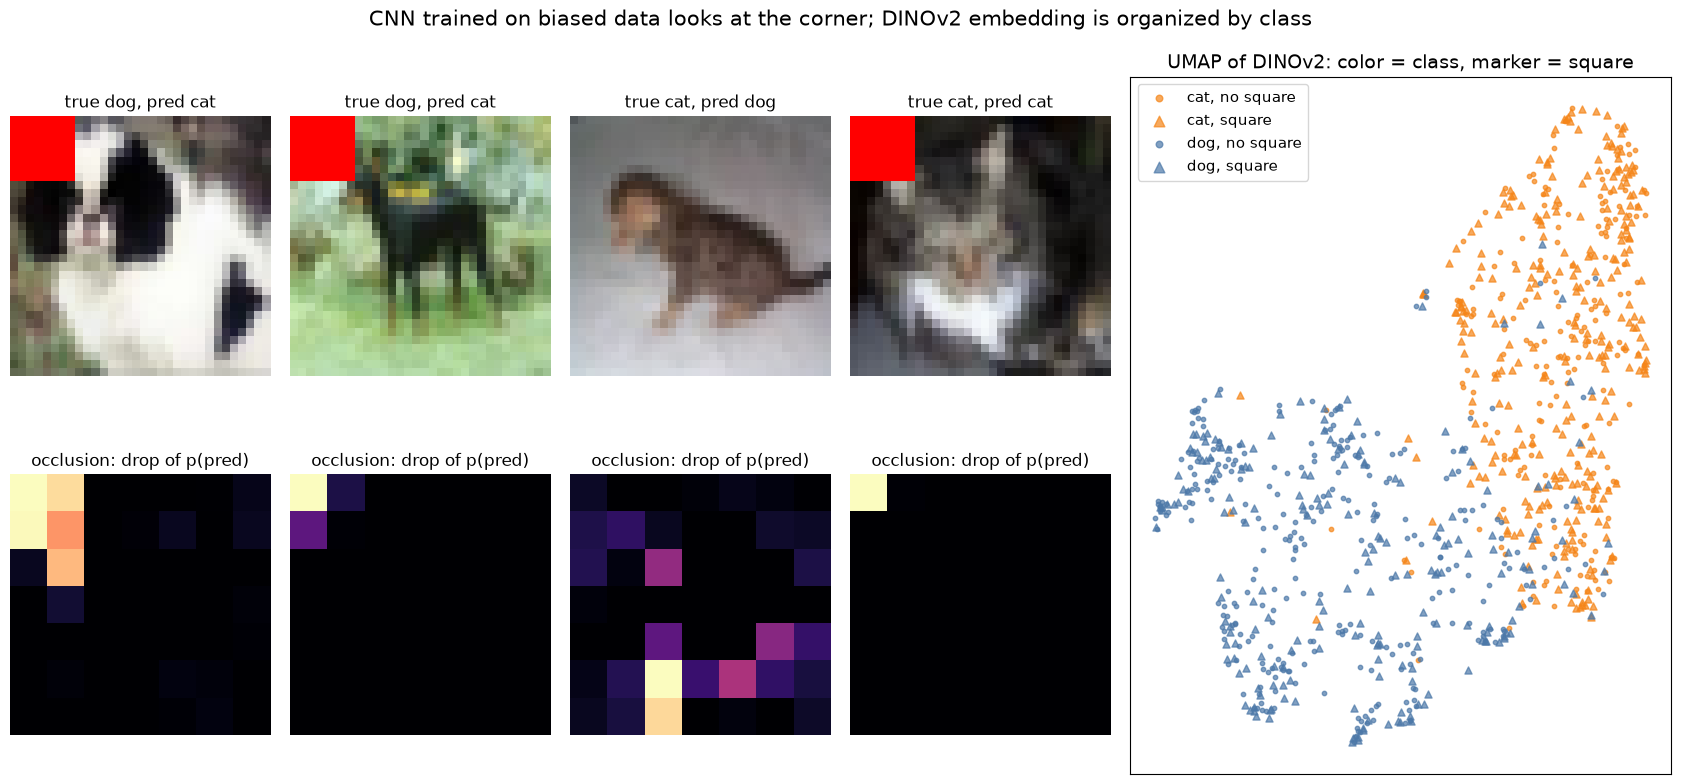

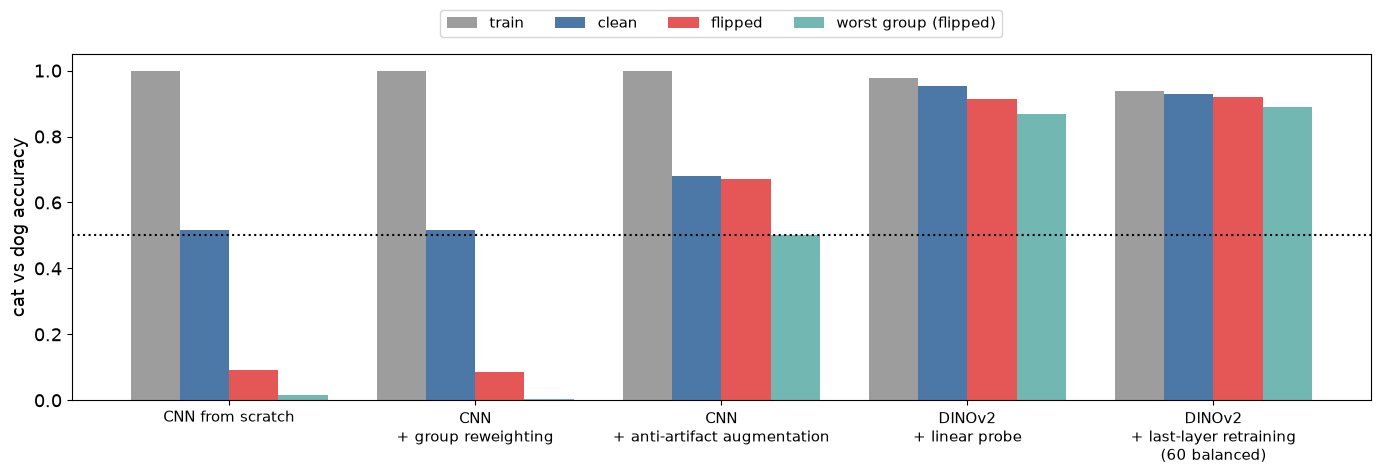

всего прошло 30.4 мин


In [24]:
Xp, sp = SF["probe"], SC["probe"][1]
half = np.random.RandomState(4).permutation(len(sp)); a_, b_ = half[: len(sp) // 2], half[len(sp) // 2:]
sq_acc = LogisticRegression(max_iter=3000).fit(Xp[a_], sp[a_]).score(Xp[b_], sp[b_])
print(f"квадрат предсказуем по признакам DINOv2: точность {sq_acc:.3f} (доля большинства {max(sp[b_].mean(), 1 - sp[b_].mean()):.3f})")
w_dir = lp.coef_[0] / np.linalg.norm(lp.coef_[0]); sq_dir = LogisticRegression(max_iter=3000).fit(Xp, sp).coef_[0]; sq_dir /= np.linalg.norm(sq_dir)
print(f"косинус между направлением классификатора (смещённый train) и направлением 'квадрата': {w_dir @ sq_dir:+.3f}")

@torch.no_grad()
def occlusion(net, x_uint8, size=8, stride=4):
    x = to_tensor(x_uint8[None]); base = torch.softmax(net(norm(x).to(DEVICE)), 1)[0]; c = base.argmax().item()
    pos = range(0, 32 - size + 1, stride); M = np.zeros((len(pos), len(pos)))
    batch = []
    for a in pos:
        for b in pos:
            xo = x.clone(); xo[:, :, a:a + size, b:b + size] = 0.5; batch.append(xo)
    p = torch.softmax(net(norm(torch.cat(batch)).to(DEVICE)), 1)[:, c].cpu().numpy()
    return (base[c].item() - p).reshape(len(pos), len(pos)), c

Xf, sf = SC["flipped"]
ex = [np.where((ys_te == 1) & (sf == 1))[0][0], np.where((ys_te == 1) & (sf == 1))[0][1], np.where((ys_te == 0) & (sf == 0))[0][0], np.where((ys_te == 0) & (sf == 1))[0][0]]
fig = plt.figure(figsize=(17, 8)); gsp = fig.add_gridspec(2, 6)
for j, i in enumerate(ex):
    M, c = occlusion(CNN["erm"], Xf[i])
    a = fig.add_subplot(gsp[0, j]); a.imshow(Xf[i]); a.set_title(f"true {'dog' if ys_te[i] else 'cat'}, pred {'dog' if c else 'cat'}", fontsize=12); a.axis("off")
    a = fig.add_subplot(gsp[1, j]); im = a.imshow(M, cmap="magma", vmin=0); a.set_title("occlusion: drop of p(pred)", fontsize=12); a.axis("off")
E = umap.UMAP(n_neighbors=15, metric="cosine", random_state=0).fit_transform(np.concatenate([SF["train"], SF["flipped"]]))
yy, ss = np.concatenate([ys_tr, ys_te]), np.concatenate([s_tr, sf])
a = fig.add_subplot(gsp[:, 4:])
for c, col, nm in ((0, "#F58518", "cat"), (1, "#4C78A8", "dog")):
    for s_, mk in ((0, "o"), (1, "^")):
        sel = (yy == c) & (ss == s_)
        a.scatter(*E[sel].T, s=10 if s_ == 0 else 26, marker=mk, color=col, alpha=0.7, label=f"{nm}, {'square' if s_ else 'no square'}")
a.legend(fontsize=11, markerscale=1.5); a.set_xticks([]); a.set_yticks([]); a.set_title("UMAP of DINOv2: color = class, marker = square")
plt.suptitle("CNN trained on biased data looks at the corner; DINOv2 embedding is organized by class", fontsize=15); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 5))
cols = ["train", "clean", "flipped", "worst group (flipped)"]; w = 0.2; xs = np.arange(len(SCR))
for j, (c, colr) in enumerate(zip(cols, ["#9D9D9D", "#4C78A8", "#E45756", "#72B7B2"])):
    ax.bar(xs + (j - 1.5) * w, SCR[c], w, label=c, color=colr)
ax.set_xticks(xs); ax.set_xticklabels([n.replace(" + ", "\n+ ").replace(" (", "\n(") for n in SCR.index], fontsize=11)
ax.axhline(0.5, ls=":", color="k"); ax.set_ylim(0, 1.05); ax.set_ylabel("cat vs dog accuracy"); ax.legend(ncol=4, fontsize=11, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout(); plt.show()
print(f"всего прошло {(time.time()-T0)/60:.1f} мин")

**Что видно.** Квадрат в признаках DINOv2 закодирован, но слабо: probe угадывает его с точностью 0.70 при доле большинства 0.505. Косинус между направлением классификатора, обученного на смещённом train, и направлением квадрата равен −0.30 (знак зависит от кодировки классов): голова частично опирается на квадрат. Этим и объясняется падение с 0.952 на clean до 0.912 на flipped. Карты закрытия у CNN подтверждают диагноз: у трёх ошибочных примеров с квадратом вероятность падает в основном при закрытии левого верхнего угла, а у кошки без квадрата чувствительность размазана по телу. На UMAP DINOv2 точки разделены по классу, а треугольники (есть квадрат) и кружки перемешаны внутри каждого класса. Это та же картина в геометрии: класс — главная ось представления, квадрат — второстепенная.

# Выводы

1. **Контрастные методы избегают коллапса за счёт негативов.** InfoNCE при случайных эмбеддингах равна $\log(2N-1)$, а температура решает, сколько негативов реально получают градиент: при $\tau=0.05$ около 7 из 4095, при $\tau=1$ почти все (раздел 10.2). На коротком бюджете SimCLR и MoCo v2 обучаются быстрее всех SSL-методов: k-NN 0.46 против 0.36 у случайной сети (раздел 11).
2. **Методы без негативов держатся на асимметрии.** Без предиктора BYOL и без центрирования DINO проекция коллапсирует: std $z$ падает до 0.018 и 0.001, энтропия учителя DINO — до 0.28 из 6.93, а потеря подозрительно мала. За 300 шагов коллапс затронул голову, а не энкодер, поэтому таблица качества его почти не видит. Мониторы надо снимать с того выхода, по которому считается потеря (разделы 10.3, 10.4, 11).
3. **Масштаб решает.** DINOv2 ViT-S/14 даёт k-NN 0.947 и linear 0.957 на CIFAR-10. Это на уровне ViT-S/16, обученного с метками ImageNet-21k (0.937 и 0.952), и выше DINO ViT-S/16 (0.909 и 0.919). Головы внимания DINO и главные компоненты патчей DINOv2 выделяют объекты без разметки (раздел 12).
4. **MAE нельзя оценивать одним k-NN.** У MAE ViT-B/16 разрыв k-NN и linear 0.43 против 0.84 по среднему патчей: информация о классе есть, но не в косинусной геометрии. Тип признака ([CLS] или среднее) меняет k-NN почти вдвое (раздел 13.1).
5. **Оценка — это протокол, а не одно число.** Weighted k-NN почти не зависит от $k$ и $T$ (0.920–0.949). Few-shot без доверительных интервалов вводит в заблуждение: при одном примере на класс эпизоды DINOv2 дают от 0.64 до 0.76. Кривая по объёму разметки показывает главное: DINOv2 с 10 примерами на класс почти догоняет DINO со 150 (разделы 13.2–13.4).
6. **Проекции надо проверять числами.** t-SNE и UMAP сохраняют соседства DINOv2 (trustworthiness 0.97, 10-NN на плоскости 0.92–0.93 при 0.936 в полном пространстве), а PCA теряет класс (0.66). Trustworthiness проверяет проекцию, а не представление: у случайной сети она 0.98 при 10-NN 0.22. При малой perplexity t-SNE рисует кластеры из чистого шума (раздел 14).
7. **Shortcut learning воспроизводится за минуту.** CNN с нуля выучила красный квадрат: 100% на train, 0.09 на flipped. Перевзвешивание групп при запоминании train не помогло, а аугментация против артефакта помогла частично (худшая группа 0.50). Замороженная DINOv2 с линейной головой даёт 0.91 на flipped, переобучение последнего слоя на 60 сбалансированных примерах поднимает худшую группу до 0.89. Аудит — probe на атрибут, карты закрытия, UMAP с маркером атрибута — показывает, что квадрат закодирован в DINOv2 слабо, а CNN смотрит в угол (раздел 15).
8. **Ограничения прогона.** Все числа получены на CPU в режиме `FAST_DEV_RUN`: около восьми эпох мини-предобучения, 1500 размеченных изображений для энкодеров, 600 — в эксперименте с паразитным признаком. Ветка для GPU не проверялась. Абсолютные значения на ней будут другими, ожидать стоит тех же направлений эффектов.

# Глоссарий


| Термин | Определение |
|---|---|
| Self-supervised learning | Обучение представлений на вспомогательной задаче, ответ на которую берётся из самих данных |
| Pretext task | Вспомогательная задача SSL (поворот, пазл, контраст, реконструкция) |
| Downstream task | Целевая задача, на которой оценивается представление |
| Позитив / негатив | Вид того же / другого изображения в контрастной задаче |
| InfoNCE, NT-Xent | Контрастные потери в форме кросс-энтропии по сходствам с температурой |
| Температура $\tau$ | Масштаб логитов softmax; малое значение концентрирует вес на самых похожих |
| Проекционная голова | MLP после энкодера, по выходу которого считается SSL-потеря; отбрасывается после обучения |
| EMA / momentum-энкодер | Сеть, веса которой — экспоненциальное скользящее среднее обучаемой сети |
| Stop-gradient | Запрет распространения градиента через ветвь |
| Коллапс (полный / размерностный) | Вырождение эмбеддингов в точку / в подпространство малой размерности |
| Эффективный ранг | Экспонента энтропии нормированного спектра сингулярных чисел |
| Alignment / uniformity | Близость позитивов / равномерность распределения признаков на сфере |
| Центрирование и заострение | Механизмы DINO против двух видов коллапса распределения учителя |
| Multi-crop | Глобальные и локальные кропы разного разрешения в одном шаге |
| Sinkhorn-Knopp | Итеративная нормировка матрицы для равномерного назначения кластерам |
| KoLeo | Регуляризатор, расталкивающий ближайших соседей в батче |
| Регистры | Дополнительные обучаемые токены ViT, убирающие артефакты в картах признаков |
| Masked image modeling | Восстановление скрытых патчей изображения |
| Онлайн-токенизатор | Учитель, задающий цели для маскированных патчей в iBOT |
| Linear probe | Линейный классификатор над замороженными признаками |
| Weighted k-NN | Классификация голосованием соседей с весами $\exp(\text{sim}/\tau)$ |
| Few-shot | Обучение на 1–10 примерах на класс |
| Label efficiency curve | Зависимость качества от объёма разметки |
| Trustworthiness | Мера сохранения локальных соседств при проекции |
| Perplexity (t-SNE) | Примерное эффективное число соседей точки |
| Паразитный признак | Признак, коррелирующий с меткой в обучающих данных без причинной связи |
| Shortcut learning | Опора модели на простой паразитный признак, не переносящийся на новые условия |
| Worst-group accuracy | Точность на худшей группе «класс × атрибут» |
| Group DRO, JTT | Методы обучения, повышающие точность на худшей группе |


# Контрольные вопросы

1. **Чему равна потеря NT-Xent при случайных эмбеддингах и $\tau=1$ для батча $N=256$? Почему?**
   Ответ: около $\log(2N-1)=\log 511\approx6.24$. Позитив неотличим от $2N-2=510$ негативов, softmax почти равномерен по 511 кандидатам. В разделе 10.1 при $N=64$ получено 4.838 против $\log127=4.844$.

2. **Какова нижняя граница NT-Xent при идеальном совпадении видов и ортогональных негативах для $N=256$ при $\tau=0.5$, 0.2 и 0.1?**
   Ответ: $\log\bigl(1+(2N-2)e^{-1/\tau}\bigr)$: 4.25 при $\tau=0.5$, 1.49 при $\tau=0.2$, 0.023 при $\tau=0.1$. Потеря ниже этой границы опуститься не может, поэтому её значение без $\tau$ и $N$ не интерпретируется.

3. **Чему равен градиент InfoNCE по сходству с негативом $k$? Что происходит при малой $\tau$?**
   Ответ: $p_k/\tau$, где $p_k$ — softmax-вес негатива. При малой $\tau$ вес концентрируется на самых похожих негативах: в разделе 10.2 при $\tau=0.05$ десять негативов из 4095 получают 92% веса, эффективное число негативов около 7.

4. **Коэффициент EMA учителя $m=0.996$. На сколько последних шагов примерно «усредняет» учитель? А при $m=0.99$?**
   Ответ: характерное окно $1/(1-m)$: 250 шагов при $m=0.996$ и 100 шагов при $m=0.99$.

5. **Почему std нормированных эмбеддингов не ловит размерностный коллапс, а эффективный ранг ловит?**
   Ответ: при коллапсе в плоскость точки по-прежнему разбросаны, и std координат почти не меняется (0.078 против 0.088 в разделе 10.3). Спектр же имеет два ненулевых сингулярных числа, и эффективный ранг равен 2.0 вместо 126.

6. **Что делают центрирование и заострение в DINO и что происходит, если оставить одно из них?**
   Ответ: центрирование вычитает средний выход учителя и не даёт одной координате доминировать, заострение (малая $\tau_t$) делает распределения острыми. Только заострение — все изображения в одной координате ($H(\bar P)=0.001$), только центрирование при $\tau_t=1$ — равномерные выходы ($\mathbb E H(P)=5.42\approx\log K=5.545$). Вместе: $H(\bar P)=5.36$, $\mathbb E H(P)=0.44$.

7. **Энтропия среднего распределения учителя DINO в конце мини-обучения 0.28 при $K=1024$. Что это значит?**
   Ответ: $\log K=6.93$, а $e^{0.28}\approx1.3$: учитель фактически использует один-два прототипа из 1024. Это коллапс варианта без центрирования (раздел 11), у исправного DINO 6.55.

8. **Во сколько раз MAE с маскированием 75% сокращает число токенов энкодера и стоимость self-attention для ViT-B/16 на 224×224?**
   Ответ: из 196 патчей энкодер видит 49, то есть токенов в 4 раза меньше. Стоимость attention квадратична по числу токенов, поэтому падает в 16 раз, а MLP-блоков — в 4 раза.

9. **Почему у MAE k-NN намного ниже linear probe? Приведите числа из раздела 13.**
   Ответ: MAE учится восстанавливать пиксели, и признаки содержат информацию о классе, но в направлениях, которые косинусная метрика не выделяет. По среднему патчей k-NN 0.431 против linear 0.838, по [CLS] 0.692 против 0.820. Для MAE стандартный протокол — дообучение или linear probe, а не k-NN.

10. **Сколько процентов точности даёт на train классификатор «есть квадрат — кошка» в разделе 15?**
    Ответ: квадрат у 282 из 300 кошек и у 17 из 300 собак, правильных ответов $282+283=565$ из 600, то есть 94.2%.

11. **Почему перевзвешивание групп не помогло CNN в разделе 15?**
    Ответ: сеть запомнила обучающую выборку (100% на train), потери на всех примерах, включая редкие группы, близки к нулю, и веса ничего не меняют. Это известное ограничение перевзвешивания для переобученных сетей ([Sagawa et al.](https://arxiv.org/abs/1911.08731)); помогают сильная регуляризация, ранняя остановка или сбалансированное переобучение последнего слоя.

12. **У UMAP случайной сети trustworthiness 0.984, а 10-NN на плоскости 0.216. Противоречие ли это?**
    Ответ: нет. Trustworthiness измеряет, сохранила ли проекция соседства исходного пространства, и проекция их сохранила. Но в признаках случайной сети соседи не связаны с классом, что видно уже по 10-NN в полном пространстве. Метрика проверяет проекцию, а не представление.

13. **Few-shot на DINOv2 при $n=1$: среднее 0.705, полуширина 95%-го интервала 0.022 по 10 эпизодам. Чему примерно равно стандартное отклонение эпизодов?**
    Ответ: $\sigma=0.022\cdot\sqrt{10}/1.96\approx0.035$. Отдельные эпизоды лежат от 0.64 до 0.76, поэтому одно число без интервала вводит в заблуждение.

# Задания

1. **Температура SimCLR.** Обучите SimCLR из раздела 11 при $\tau\in\{0.05, 0.1, 0.2, 0.5\}$ и постройте k-NN, std $z$ и эффективный ранг $h$ как функции $\tau$. Свяжите результат с долей веса трудных негативов из раздела 10.2.
2. **Размер очереди MoCo.** Сравните очереди 256, 1024, 4096 и 16 384 ключей при одном числе шагов. Где кончается выигрыш? Сколько эпох «стареет» самый старый ключ при каждом размере?
3. **Спасение сломанных вариантов.** Для BYOL без предиктора и DINO без центрирования увеличьте число шагов в 3–5 раз и проверьте, передаётся ли коллапс головы энкодеру: следите за эффективным рангом $h$ и k-NN. Затем добавьте к BYOL без предиктора VICReg-член на дисперсию (раздел 3.6) и сравните.
4. **Признаки MAE.** Для MAE ViT-B/16 сравните k-NN и linear probe по [CLS], среднему патчей, выходу промежуточного блока и по признакам после стандартизации. Какой признак ближе всего к DINOv2 и почему?
5. **Кривые по разметке на GPU.** Запустите блокнот с `FAST_DEV_RUN = False` и постройте кривые раздела 13.4 до 500 примеров на класс. Сравните положение точек пересечения кривых с прогоном на CPU.
6. **Shortcut другого типа.** Замените красный квадрат на менее заметный артефакт: изменение оттенка всего изображения, водяной знак или JPEG-сжатие одного класса. Повторите раздел 15 и аудит. Какие артефакты DINOv2 кодирует сильнее квадрата?
7. **Честная визуализация.** Для признаков supervised ViT и DINOv2 постройте UMAP при `n_neighbors` 5, 15, 50 и трёх seed, посчитайте trustworthiness и 10-NN. Сформулируйте, какие утверждения о «кластерах» на картинке подтверждаются числами, а какие нет.

# Источники


Контрастные методы:

- Chen T. et al. A Simple Framework for Contrastive Learning of Visual Representations (SimCLR), 2020 — https://arxiv.org/abs/2002.05709
- He K. et al. Momentum Contrast for Unsupervised Visual Representation Learning (MoCo), 2019 — https://arxiv.org/abs/1911.05722
- Chen X. et al. Improved Baselines with Momentum Contrastive Learning (MoCo v2), 2020 — https://arxiv.org/abs/2003.04297
- van den Oord A. et al. Representation Learning with Contrastive Predictive Coding, 2018 — https://arxiv.org/abs/1807.03748
- Wang T., Isola P. Understanding Contrastive Representation Learning through Alignment and Uniformity on the Hypersphere, 2020 — https://arxiv.org/abs/2005.10242

Методы без негативов:

- Grill J.-B. et al. Bootstrap Your Own Latent (BYOL), 2020 — https://arxiv.org/abs/2006.07733
- Chen X., He K. Exploring Simple Siamese Representation Learning (SimSiam), 2020 — https://arxiv.org/abs/2011.10566
- Caron M. et al. Unsupervised Learning of Visual Features by Contrasting Cluster Assignments (SwAV), 2020 — https://arxiv.org/abs/2006.09882
- Zbontar J. et al. Barlow Twins: Self-Supervised Learning via Redundancy Reduction, 2021 — https://arxiv.org/abs/2103.03230
- Bardes A., Ponce J., LeCun Y. VICReg, 2021 — https://arxiv.org/abs/2105.04906
- Caron M. et al. Emerging Properties in Self-Supervised Vision Transformers (DINO), 2021 — https://arxiv.org/abs/2104.14294
- Oquab M. et al. DINOv2: Learning Robust Visual Features without Supervision, 2023 — https://arxiv.org/abs/2304.07193
- Darcet T. et al. Vision Transformers Need Registers, 2023 — https://arxiv.org/abs/2309.16588
- Siméoni O. et al. DINOv3, 2025 — https://arxiv.org/abs/2508.10104; страница проекта — https://ai.meta.com/research/dinov3/

Masked image modeling:

- Bao H. et al. BEiT: BERT Pre-Training of Image Transformers, 2021 — https://arxiv.org/abs/2106.08254
- He K. et al. Masked Autoencoders Are Scalable Vision Learners (MAE), 2021 — https://arxiv.org/abs/2111.06377
- Zhou J. et al. iBOT: Image BERT Pre-Training with Online Tokenizer, 2021 — https://arxiv.org/abs/2111.07832
- Assran M. et al. Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture (I-JEPA), 2023 — https://arxiv.org/abs/2301.08243

Ранние pretext-задачи:

- Doersch C., Gupta A., Efros A. Unsupervised Visual Representation Learning by Context Prediction, 2015 — https://arxiv.org/abs/1505.05192
- Noroozi M., Favaro P. Unsupervised Learning of Visual Representations by Solving Jigsaw Puzzles, 2016 — https://arxiv.org/abs/1603.09246
- Gidaris S. et al. Unsupervised Representation Learning by Predicting Image Rotations, 2018 — https://arxiv.org/abs/1803.07728

Визуализация:

- van der Maaten L., Hinton G. Visualizing Data using t-SNE, JMLR, 2008 — https://www.jmlr.org/papers/v9/vandermaaten08a.html
- McInnes L. et al. UMAP: Uniform Manifold Approximation and Projection for Dimension Reduction, 2018 — https://arxiv.org/abs/1802.03426
- Wattenberg M., Viégas F., Johnson I. How to Use t-SNE Effectively. Distill, 2016 — https://distill.pub/2016/misread-tsne/
- scikit-learn: trustworthiness — https://scikit-learn.org/stable/modules/generated/sklearn.manifold.trustworthiness.html

Shortcut learning и робастность:

- Geirhos R. et al. Shortcut Learning in Deep Neural Networks, 2020 — https://arxiv.org/abs/2004.07780
- Geirhos R. et al. ImageNet-trained CNNs are biased towards texture; increasing shape bias improves accuracy and robustness, 2018 — https://arxiv.org/abs/1811.12231
- Sagawa S. et al. Distributionally Robust Neural Networks for Group Shifts, 2019 — https://arxiv.org/abs/1911.08731
- Liu E. Z. et al. Just Train Twice: Improving Group Robustness without Training Group Information, 2021 — https://arxiv.org/abs/2107.09044
- Kirichenko P., Izmailov P., Wilson A. G. Last Layer Re-Training is Sufficient for Robustness to Spurious Correlations, 2022 — https://arxiv.org/abs/2204.02937
- Lapuschkin S. et al. Unmasking Clever Hans Predictors and Assessing What Machines Really Learn, 2019 — https://arxiv.org/abs/1902.10178
- Zech J. R. et al. Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs, PLOS Medicine, 2018 — https://journals.plos.org/plosmedicine/article?id=10.1371/journal.pmed.1002683

Оценка и эффективный ранг:

- Garrido Q. et al. RankMe: Assessing the Downstream Performance of Pretrained Self-Supervised Representations by Their Rank, 2023 — https://arxiv.org/abs/2210.02885
- Roy O., Vetterli M. The effective rank: A measure of effective dimensionality, EUSIPCO, 2007 — https://infoscience.epfl.ch/record/110188
- Venna J., Kaski S. Neighborhood Preservation in Nonlinear Projection Methods: An Experimental Study, ICANN, 2001 — https://link.springer.com/chapter/10.1007/3-540-44668-0_68
- Snell J., Swersky K., Zemel R. Prototypical Networks for Few-shot Learning, 2017 — https://arxiv.org/abs/1703.05175
- Steiner A. et al. How to train your ViT? Data, Augmentation, and Regularization in Vision Transformers, 2021 — https://arxiv.org/abs/2106.10270

Данные и модели практикума:

- Krizhevsky A. Learning Multiple Layers of Features from Tiny Images (CIFAR-10), 2009 — https://www.cs.toronto.edu/~kriz/cifar.html
- CIFAR-10 в формате parquet на Hugging Face — https://huggingface.co/datasets/uoft-cs/cifar10
- DINOv2 ViT-S/14 — https://huggingface.co/facebook/dinov2-small
- DINO ViT-S/16 — https://huggingface.co/timm/vit_small_patch16_224.dino
- MAE ViT-B/16 — https://huggingface.co/facebook/vit-mae-base
- ViT-S/16, обученный с учителем на ImageNet-21k и ImageNet-1k — https://huggingface.co/timm/vit_small_patch16_224.augreg_in21k_ft_in1k
- Фотография COCO val2017 № 39769 — http://images.cocodataset.org/val2017/000000039769.jpg
- Библиотеки: timm — https://github.com/huggingface/pytorch-image-models; transformers — https://github.com/huggingface/transformers; umap-learn — https://umap-learn.readthedocs.io/